# Pac-Man AI final project report

Christian Gore and Phillip Kononenko  
CSCI 3202, Introduction to Artificial Intelligence  
Option 1, Choose Your Own Project

[Jump to the extra-credit AI explanation](#extra-credit)

## Project goal and final outcome

We built a small Pac-Man game to test whether Q-learning could learn to collect objectives without getting caught. For the final version, Pac-Man collects two pellets while the ghost uses BFS to chase it and Q-learning to choose where to search after losing sight of it.

After training, the saved Pac-Man policies won 6,691 of 10,000 scheduled test games against the learned ghosts, or 66.91%. All five independently trained policy pairs exceeded our final 55% target. The result describes a two-pellet game. Our intermediate report studied a four-corner game, so its 73.6% result is historical evidence for a different task, not a directly comparable score.

## Development since the intermediate report

The intermediate implementation already had a 5 by 5 environment, wall discovery, a limited-vision ghost, random and BFS baselines, Q-learning, and reproducible evaluation. Pac-Man had to visit all four corners. One frozen learned policy won 736 of 1,000 test games, compared with 149 for BFS and zero for random movement. That submission recorded 476 passing tests. Its report and notebook remain preserved as the intermediate record.

Our professor asked whether adding learning or pathfinding to the ghost could help. The intermediate ghost already used BFS during pursuit. We responded by keeping BFS navigation and learning the search direction after visibility is lost. The two-pellet objective was a separate team design decision, not a requirement or an approval stated in that feedback.

For the final version, we changed the objective to two randomly placed pellets and added learning to the ghost's search decisions. We also expanded Pac-Man's state representation and used five independent training runs. We then tested Pac-Man before and after more training against the same ghosts so that we could compare the results under the new rules.

We did not add the power-up described as future work in our intermediate report. We spent that time on the learning ghost, more tests, and the terminal demonstration. Because we changed the objective, we cannot use the old 73.6% score to judge whether the final player improved.

The main changes were:

| Part | Intermediate version | Final version |
|---|---|---|
| Goal | Visit all four corners, with the starting corner already counted | Collect two randomly placed pellets |
| Pac-Man's view | Current ghost position, visited corners, and remembered nearby walls | Current ghost position, remaining pellet positions, remembered nearby walls, and turns left |
| Pac-Man's Q-table inputs | Six inputs about the route, open moves, ghost, and remaining corners | Eight inputs, with pellet-distance and time buckets added and the objective inputs changed |
| Storage | A dense NumPy table with 122,880 state rows | A dictionary containing encountered states |
| Move selection | Could choose any of four directions, including blocked moves | Chooses only legal neighboring moves |
| Timeout training | No -100 timeout reward; the update could use the next state's value | Timeout gives -100 and ends the update without a next-state value |
| Discount | 0.99 for Pac-Man | 1.0 for Pac-Man and 0.97 for the ghost |
| Ghost search | Fixed search toward least recently visited neighbors after pursuit | Random wandering plus bounded, learned directional search after pursuit |
| Training | One 50,000-game Pac-Man run against a fixed ghost | Five runs with Pac-Man training, ghost training, and further Pac-Man training |
| Main comparison | Random, BFS, and Q-learning Pac-Man | Pac-Man before and after extra training against fixed and learned search ghosts |

The grid size, opposite starting corners, one-cell movement, move order, 100-turn limit, and adjacent-wall sensing stayed the same. The timer is new information in the learned player's observation. The added pellet-distance input is calculated from its remembered map rather than revealing hidden walls.

## Game rules and information

Pac-Man starts at the top-left corner and the ghost at the bottom-right. Two distinct pellets occupy open cells, excluding both starting cells. Pac-Man moves first each turn. Moving into the ghost causes immediate capture. Collecting the second pellet wins before the ghost replies. Otherwise, the ghost moves and can capture Pac-Man. A game still unfinished after 100 turns ends in a tie. A terminal win or capture on that turn takes priority over timeout.

Both characters move one grid cell at a time. Walls and grid boundaries block movement. The shared generator samples connected mazes with alternative routes. Map construction checks structural properties, not whether a perfect player could win. We count every scheduled test game, including losses and ties. We do not remove a game because a perfect player would lose it.

Pac-Man knows the ghost's current position and both remaining pellet positions. It discovers adjacent walls and retains that knowledge during the game. BFS plans through the remembered map and treats unknown cells as open. A route can therefore change when Pac-Man discovers a wall. This is the same visibility rule Pac-Man had in the intermediate version. It has not gained full knowledge of the walls. It knows the two pellet positions because they replace the four known corner objectives.

The ghost knows the static wall map but sees Pac-Man only along an unobstructed row or column. It infers heading from consecutive visible positions. After losing sight, it follows BFS to the last sighting and then investigates directional targets. Targets are at most three open cells away. Each choice lasts at most four moves, with at most three choices per sighting. Memory expires after 12 hidden observations. Reacquisition interrupts search, while exhausted memory or search returns the ghost to seeded random wandering. The ghost receives no hidden Pac-Man position or movement command.

We kept BFS for movement because the ghost knows the walls and can calculate a shortest route to a visible or remembered position. The part it cannot know is where Pac-Man went after disappearing. We used Q-learning for that search choice. This kept the learning problem smaller than asking the ghost to learn every movement from scratch. Random wandering gives it a way to explore before any sighting, and the search limits stop it from following an old sighting forever.

## Code, libraries, and tools

The final runtime is in `pacman/hybrid`. `models.py` defines observations and rules, `game.py` applies turns and rewards, `learning.py` implements Pac-Man's features and Q-table, and `ghost.py` controls pursuit and search. `experiment.py` manages training and evaluation, `artifacts.py` stores compatible policies and evidence, and `__main__.py` supplies commands. Shared modules supply maps, grid search, random streams, and statistics. The notebook contains the application source, saved policies, and results. Running it writes these files to a temporary folder so it can run without the repository.

| Tool | Use and source |
|---|---|
| Python 3.11+ | Game rules, our BFS implementation, seeded randomness, statistics, file handling, and CLI. [Python standard library](https://docs.python.org/3/library/). |
| NumPy | Numeric policy serialization and legacy dense-table code. The new mutable Q-tables are Python dictionaries of feature tuples and four-value rows. [NumPy documentation](https://numpy.org/doc/stable/user/whatisnumpy.html). |
| Matplotlib | Figures for recorded results. [Matplotlib guide](https://matplotlib.org/stable/users/explain/quick_start.html). |
| pytest | Automated correctness and integration checks. [pytest documentation](https://docs.pytest.org/en/stable/). |
| Jupyter | Report, source, evidence, and executable examples in one submission. It is not a game-runtime dependency. [Jupyter documentation](https://docs.jupyter.org/en/latest/). |

We implemented BFS and the Q-learning updates directly. The game does not use a game engine or a neural network. NetworkX is cited as a reference for BFS, but it is not a dependency.

## Learning and training design

Pac-Man's eight inputs summarize the route toward a pellet, available neighboring directions, relative ghost position, estimated ghost distance, estimated sight, remaining pellet count, pellet distance, and remaining time. Legal-action masking excludes known blocked directions. Sparse tables store only encountered feature combinations. Different underlying situations can share a row, so this is a compressed representation rather than a complete game state.

Both learners use a learning rate of 0.1. Pac-Man uses discount 1.0, with rewards of +1 per pellet, +100 for winning, -100 for capture or timeout, and -0.05 per turn. These rewards combine, so learning favors collection and shorter games as well as winning. The ghost uses discount 0.97, +1 for capture, -1 when Pac-Man wins, and zero for timeout. It learns only the directional investigation choice. BFS navigation, visibility, memory, and search limits remain fixed.

Each training run followed the same stages:

1. Train a fresh Pac-Man for 30,000 games against the fixed search ghost. Save checkpoints at 10,000, 20,000, and 30,000 games.
2. Train a fresh ghost for 30,000 games against that frozen checkpoint pool.
3. Freeze the ghost and continue Pac-Man for 50,000 games against an equal mixture of fixed and learned ghosts.

Across five runs, this totals 550,000 training games. Exploration falls linearly from 1.0 to 0.05 during the first 70% of each stage, then stays at 0.05. Frozen opponents still react to observations, but their tables cannot change. Evaluation disables exploration and updates. The AI explanation at the end of this notebook gives the update equations and the ghost's treatment of search choices that span several turns.

## How we tested

We tested the game rules separately from the players' win rates. The final suite passed 545 tests. Checks cover movement, collision and timeout ordering, pellet rewards, wall memory, line of sight, hidden-information boundaries, search limits, feature encoding, terminal updates, policy loading, and complete command workflows. The recorded output is `reports/hybrid-55/final-tests.log`.

Each test matchup contains five policy sets, 1,000 layout-seed slots per set, and two episode keys per slot. The same schedules pair the before and after policies and the fixed and learned ghosts. Independent random streams control pellets, ghost behavior, exploration, and opponent choice. Training and evaluation wall layouts belong to separate hash-based partitions. Counting actual generated layouts found 26,012 distinct training layouts and 491 distinct test layouts, with zero overlap. Different seeds can produce the same walls. The 10,000 games are therefore not 10,000 independent new mazes.

All five final policy sets were frozen before test evaluation. The saved evidence includes policy hashes, rules, schedules, per-game outcomes, and replay verification. All 125,000 archived evaluation games replayed exactly, including validation checkpoints and final test matchups. Verification also tests rejection of missing games, altered records, wrong policies, and incompatible rules. Replay checks establish consistency with the saved implementation, while the rule tests check intended behavior separately.

One limitation is that the earlier corner-game project used these test wall-layout partitions under its own rules. The final evaluation therefore uses training-disjoint layouts, but not a wall-layout dataset that had never been examined by the project.

## Results under the final rules

| Pac-Man training stage | Ghost | Wins | Captures | Ties | Win rate |
|---|---|---:|---:|---:|---:|
| Before additional training | Fixed search | 6,424 | 3,530 | 46 | 64.24% |
| Before additional training | Learned search | 6,367 | 3,590 | 43 | 63.67% |
| After additional training | Fixed search | 6,739 | 3,203 | 58 | 67.39% |
| After additional training | Learned search | 6,691 | 3,250 | 59 | 66.91% |

Every row counts 10,000 games, including ties. Final validation against the learned ghosts produced 64.28% wins. Final test rates across individual training runs ranged from 66.30% to 67.55%, all above the 55% target. The chart and machine-readable counts are in `reports/hybrid-55/results.png` and `aggregate.json`.

Against the same frozen learned ghosts, Pac-Man gained 3.24 percentage points after additional training. An approximate crossed-cluster bootstrap resamples training runs and wall-layout hashes while preserving paired outcomes. Its 95% interval is 62.29% to 71.34% for the final rate and 1.32 to 4.93 percentage points for the gain. These intervals account for repeated layouts more directly than treating all games as independent. Five training runs still limit conclusions about training variability.

The ghost's measured change was small. Against final Pac-Man, learned search produced 3,250 captures versus 3,203 for fixed search, a gain of 0.47 percentage points. This does not establish a large improvement in ghost strength. The learner changes only a bounded search choice, while both ghosts share most of their behavior.

There is also a limitation in the training comparison. The final stage adds 50,000 games and changes the opponent mixture together. Without an equal-budget fixed-only control, we cannot attribute the gain specifically to learned-ghost exposure. The results establish an improvement after that combined stage under the tested rules. They do not establish optimal play or performance on every maze distribution.

## Working example

From the repository, the short demonstration command is:

```sh
./play
```

It loads the frozen policies from training run 0 and watches AI versus AI. There are no keyboard movement controls and no learning during playback. The default uses layout seed 1,000,000 and episode key 42, and ends in a Pac-Man win after 13 turns. This is a reproducible example, not an additional estimate of win rate.

The display uses `P` for Pac-Man, `G` for the ghost, `o` for a pellet, `#` for a known wall, `?` for an unknown cell, and `.` for known open space. Its status line shows the current turn out of 100, pellets remaining, the ghost's mode, and the outcome. This makes pursuit, search, and collection visible during the interview.

For an immediate plain-text replay, run `./play --delay 0 --plain`. The `--seed` option changes the layout-seed input. The `--key` option changes pellet placement and episode randomness for that layout. For example, `./play --seed 1000000 --key 42 --delay 0 --plain` reproduces the default game. The notebook reconstructs the application without requiring a Git checkout and runs its saved-policy example. Its normal execution does not repeat full training or the complete test evaluation.

## Conclusion

We learned that the shortest route to an objective is not always a good move when a ghost is nearby. BFS gives Pac-Man a route hint, but its Q-table chooses the move using information about the ghost too. The final player won 66.91% of test games against the learned ghosts, and all five runs passed our 55% target. The ghost still catches Pac-Man in many games, so there is room to improve.

We also learned to be careful about what a win rate actually measures. Changing from four corners to two pellets changed the task. We can compare before and after training within the final game, but comparing 73.6% with 66.91% would mix different rules. Reusing the same evaluation schedules and checking saved games helped us catch mistakes. Five training runs and repeated wall layouts still limit what we can conclude.

If we continued, we would give Pac-Man the same number of extra training games against the fixed ghost and compare that with the mixed-opponent training. That would help us find out how much the learning ghost actually helps. We would also look at the games Pac-Man loses before adding more inputs to its Q-table. Power-ups remain an unfinished idea and would need their own training and tests.


## Running this self-contained notebook

Use Python 3.11 or newer with NumPy, Matplotlib, and Jupyter/IPython installed in the selected kernel. Then choose **Restart Kernel and Run All**. The notebook needs no repository checkout, Git, internet access, or installation during execution. It creates a fresh temporary workspace on every full run and prints its location. Keep this notebook; temporary files can be removed by the operating system.

Run All restores the visible source and embedded evidence, checks all saved record summaries and identities, displays recorded results, replays one known game, and runs ten frozen-policy validation games. It does not rerun the full training, 125,000-game replay, or 545-test suite. The short optional training cell is disabled. The 25 policies and all 85 compressed evaluation reports remain available for inspection.

| Option 1 requirement | Location |
|---|---|
| Problem, AI design, libraries and explanation | Report above and cited AI appendix below |
| Complete application code | Visible `%%writefile` cells below |
| Testing approach and results | Report and recorded-evidence audit below |
| Working example | Live CLI replay and ten-game validation demonstration |
| Two to three conclusion paragraphs | Three-paragraph conclusion in the report |
| Extra AI explanation with sources | [Extra-credit section](#extra-credit) and embedded standalone PDF |


In [1]:
import base64
from collections import Counter
import hashlib
import importlib.util
import json
import os
from pathlib import Path, PurePosixPath
import subprocess
import sys
import tempfile
import zlib
from IPython.display import Image, Markdown, display

if sys.version_info < (3, 11):
    raise RuntimeError("Use a Python 3.11 or newer Jupyter kernel.")
missing = [name for name in ("numpy", "matplotlib") if importlib.util.find_spec(name) is None]
if missing:
    raise RuntimeError("Install these packages in the selected kernel before Run All: " + ", ".join(missing))
WORKSPACE = Path(tempfile.mkdtemp(prefix="pacman-final-")).resolve()
os.chdir(WORKSPACE)
print("Fresh, independent workspace:", WORKSPACE)

def safe_destination(name):
    path = PurePosixPath(name)
    if (not name or path.is_absolute() or ".." in path.parts or "\\" in name
            or str(path) != name or ":" in name):
        raise ValueError(f"unsafe bundle path: {name!r}")
    target = WORKSPACE.joinpath(*path.parts)
    if not target.resolve().is_relative_to(WORKSPACE):
        raise ValueError(f"bundle path escapes workspace: {name}")
    return target

for directory in ("pacman/agents", "pacman/hybrid", "scripts"):
    (WORKSPACE / directory).mkdir(parents=True, exist_ok=True)


Fresh, independent workspace: /private/var/folders/b7/zrvh84fd5lzdv299wwxvx5w00000gn/T/pacman-final-84ib0v3m


## Complete application source

Each cell writes exactly one visible file into the new workspace. The four analysis scripts are included for reproducibility; full evaluation is not run automatically.

In [2]:
%%writefile pacman/__init__.py
"""Shared foundation for the Pac-Man AI game.

Gameplay and command-line entry points are implemented by subsequent tickets.
"""


Writing pacman/__init__.py


In [3]:
%%writefile pacman/__main__.py
"""`python -m pacman <command>`."""

import sys

from pacman.cli import main

if __name__ == "__main__":
    sys.exit(main())


Writing pacman/__main__.py


In [4]:
%%writefile pacman/agents/__init__.py
"""Agent names and the factory the CLI builds them with."""

from pacman.config import Config

AGENT_NAMES = ("random", "pathfinding", "learned")


def make_agent(name: str, config: Config, policy=None):
    """Build a named agent; the learned agent needs a policy and always plays greedily here."""
    if name == "random":
        from pacman.agents.random_agent import RandomAgent

        return RandomAgent()
    if name == "pathfinding":
        from pacman.agents.pathfinding import PathfindingAgent

        return PathfindingAgent()
    if name == "learned":
        if policy is None:
            raise ValueError("the learned agent needs a policy file (--policy)")
        from pacman.agents.learned import LearnedAgent

        return LearnedAgent(config.learner, q=policy.q, training=False)
    raise ValueError(f"unknown agent {name!r}; choose one of {', '.join(AGENT_NAMES)}")


Writing pacman/agents/__init__.py


In [5]:
%%writefile pacman/agents/base.py
"""Common agent contract, independent of the environment implementation."""

import random
from typing import Protocol, runtime_checkable

from pacman.env import Observation, Outcome
from pacman.grid import Direction


@runtime_checkable
class Agent(Protocol):
    name: str

    def reset(self, rng: random.Random) -> None:
        """Start a game with fresh transition caches; retain learned policy data."""
        ...

    def act(self, observation: Observation) -> Direction:
        """Choose an action. The runner never calls this after a final outcome."""
        ...

    def observe(
        self, reward: float, observation: Observation, outcome: Outcome | None,
    ) -> None:
        """Receive each transition, including the explicit final referee ruling.

        WIN/LOSS/TIE end action requests. A learned agent's configured tie_update
        independently determines whether the final TIE update bootstraps.
        """
        ...


Writing pacman/agents/base.py


In [6]:
%%writefile pacman/agents/features.py
"""The state features and the table index, from an observation alone."""

from dataclasses import dataclass

from pacman.agents.pathfinding import plan, remembered_open
from pacman.env import KnownCell, Observation
from pacman.grid import COLS, DELTAS, Direction, in_grid, line_of_sight

STATES = 4 * 16 * 80 * 4 * 2 * 3  # 122,880 rows; policy_io.TABLE_SHAPE must agree


@dataclass(frozen=True, slots=True)
class Features:
    step: int        # first step to the nearest unvisited corner, 0..3
    open_mask: int   # bit i set when the neighbour in direction i is known open, 0..15
    offset: int      # ghost's (row, col) offset from Pac-Man, centre removed, 0..79
    distance: int    # shortest-path distance to the ghost, bucketed 1, 2, 3, 4+, as 0..3
    seen: int        # line of sight on the remembered map, 0..1
    remaining: int   # unvisited corners minus one, 0..2

    @property
    def index(self) -> int:
        return (
            (((self.step * 16 + self.open_mask) * 80 + self.offset) * 4 + self.distance) * 2
            + self.seen
        ) * 3 + self.remaining


def features(observation: Observation) -> Features:
    """Encode an observation the game is still running from; captures are never states."""
    (pacman_row, pacman_col), (ghost_row, ghost_col) = observation.pacman, observation.ghost
    if observation.pacman == observation.ghost:
        raise ValueError("a captured Pac-Man is never a state")
    current = plan(observation)  # raises when no corner remains
    known = observation.known
    open_mask = 0
    for direction in Direction:
        d_row, d_col = DELTAS[direction]
        cell = (pacman_row + d_row, pacman_col + d_col)
        if in_grid(cell) and known[cell[0] * COLS + cell[1]] == KnownCell.OPEN:
            open_mask |= 1 << direction
    k = (ghost_row - pacman_row + 4) * 9 + (ghost_col - pacman_col + 4)
    offset = k - 1 if k > 40 else k
    distance = min(current.distances[observation.ghost], 4) - 1
    seen = int(line_of_sight(observation.ghost, observation.pacman, remembered_open(observation)))
    return Features(int(current.step), open_mask, offset, distance, seen, current.remaining - 1)


def state_index(observation: Observation) -> int:
    return features(observation).index


Writing pacman/agents/features.py


In [7]:
%%writefile pacman/agents/learned.py
"""Tabular Q-learning over the encoded state features."""

import random

import numpy

from pacman.agents.features import state_index
from pacman.config import LearnerSettings
from pacman.env import Observation, Outcome
from pacman.grid import Direction
from pacman.policy_io import TABLE_SHAPE
from pacman.rng import pick


class LearnedAgent:
    """Greedy outside training; epsilon-greedy with Q updates in training."""

    name = "learned"

    def __init__(
        self, settings: LearnerSettings, q: numpy.ndarray | None = None, training: bool = False,
    ) -> None:
        if q is None:
            q = numpy.zeros(TABLE_SHAPE, dtype=numpy.float64)
        elif not isinstance(q, numpy.ndarray) or q.dtype != numpy.float64 or q.shape != TABLE_SHAPE:
            raise ValueError(f"q must be a float64 array of shape {TABLE_SHAPE}")
        self.settings = settings
        self.q = q
        self.training = training
        self.epsilon = 0.0  # the training loop sets it before each episode
        self.rng: random.Random | None = None
        self._state: int | None = None      # state of the pending transition, set by act
        self._action: Direction | None = None
        self._next_state: int | None = None  # cache for the next act; only a training observe fills it

    def reset(self, rng: random.Random) -> None:
        """New game: fresh generator and empty transition cache; the table is kept."""
        self.rng = rng
        self._state = None
        self._action = None
        self._next_state = None

    def act(self, observation: Observation) -> Direction:
        state = self._next_state if self._next_state is not None else state_index(observation)
        self._next_state = None
        if self.training and self.rng.random() < self.epsilon:
            action = Direction(pick(self.rng, 4))
        else:
            action = Direction(int(numpy.argmax(self.q[state])))  # first maximum: direction order
        self._state, self._action = state, action
        return action

    def observe(self, reward: float, observation: Observation, outcome: Outcome | None) -> None:
        if not self.training:
            return
        if self._action is None:
            raise RuntimeError("observe without a pending action; act comes first in every game")
        state, action = self._state, self._action
        settings = self.settings
        bootstrap = outcome is None or (outcome is Outcome.TIE and settings.tie_update == "bootstrap")
        if bootstrap:
            next_state = state_index(observation)
            target = reward + settings.discount * float(numpy.max(self.q[next_state]))
        else:
            target = reward  # WIN, LOSS or a terminal TIE: the final observation is never encoded
        self.q[state, action] += settings.learning_rate * (target - self.q[state, action])
        self._next_state = next_state if outcome is None else None
        self._state = None
        self._action = None


Writing pacman/agents/learned.py


In [8]:
%%writefile pacman/agents/pathfinding.py
"""The pathfinding baseline and the plan it shares with the features."""

from collections.abc import Mapping
from dataclasses import dataclass
import random

from pacman.env import KnownCell, Observation, Outcome
from pacman.grid import COLS, Cell, Direction, Passable, bfs, first_step

# Equally near corners are chosen in this order.
CORNER_ORDER: tuple[Cell, ...] = ((0, 4), (4, 0), (4, 4))


def remembered_open(observation: Observation) -> Passable:
    """Pac-Man's passable predicate: anything not remembered as a wall counts as open."""
    known = observation.known
    return lambda cell: known[cell[0] * COLS + cell[1]] != KnownCell.WALL


@dataclass(frozen=True, slots=True)
class Plan:
    target: Cell
    step: Direction
    distances: Mapping[Cell, int]
    remaining: int


def plan(observation: Observation) -> Plan:
    """The nearest unvisited corner on the remembered map and the first step towards it."""
    passable = remembered_open(observation)
    distances = bfs(observation.pacman, passable)
    unvisited = [corner for corner in CORNER_ORDER if corner not in observation.visited]
    if not unvisited:
        raise ValueError("every corner is visited; there is nothing left to plan")
    target = min(unvisited, key=lambda corner: distances[corner])
    return Plan(target, first_step(observation.pacman, target, passable), distances, len(unvisited))


class PathfindingAgent:
    name = "pathfinding"

    def reset(self, rng: random.Random | None) -> None:
        return None

    def act(self, observation: Observation) -> Direction:
        return plan(observation).step

    def observe(self, reward: float, observation: Observation, outcome: Outcome | None) -> None:
        return None


Writing pacman/agents/pathfinding.py


In [9]:
%%writefile pacman/agents/random_agent.py
"""The random baseline: one uniform draw per step."""

import random

from pacman.env import Observation, Outcome
from pacman.grid import Direction
from pacman.rng import pick


class RandomAgent:
    name = "random"

    def reset(self, rng: random.Random) -> None:
        self.rng = rng

    def act(self, observation: Observation) -> Direction:
        return Direction(pick(self.rng, 4))

    def observe(self, reward: float, observation: Observation, outcome: Outcome | None) -> None:
        return None


Writing pacman/agents/random_agent.py


In [10]:
%%writefile pacman/cli.py
"""The five commands: train, evaluate, check, simulate and watch.

Only this module parses arguments or prints; the services return data and strings.
Every error ends the command with a message on standard error and a non-zero exit.
"""

import argparse
from dataclasses import fields, replace
import os
from pathlib import Path
import sys
import time

from pacman import evaluate
from pacman import train as training
from pacman.agents import AGENT_NAMES, make_agent
from pacman.config import Config
from pacman.env import Environment
from pacman.episode import play_episode
from pacman.evaluate import (
    TABLE_HEADER,
    compare,
    difficulty_check,
    format_header,
    format_report,
    format_summary_row,
    knob_differences,
    run_split,
    summarise,
    write_eval_json,
)
from pacman.mapgen import Split, split_of_seed
from pacman.policy_io import Policy, load_policy
from pacman.referee import Referee
from pacman.render import render_frame, use_plain

CLEAR_SCREEN = "\x1b[H\x1b[2J"  # cursor home, then clear


def apply_sets(config: Config, sets: list[str]) -> Config:
    """Apply `--set name=value` overrides by bare field name, with type-checked values."""
    for setting in sets:
        name, separator, raw = setting.partition("=")
        if not separator or not name:
            raise ValueError(f"--set needs NAME=VALUE, got {setting!r}")
        config = _apply_set(config, name, raw)
    return config


def _apply_set(config: Config, name: str, raw: str) -> Config:
    for section in ("game", "learner"):
        part = getattr(config, section)
        for field in fields(part):
            if field.name == name:
                value = _parse_value(field.type, raw, name)
                return replace(config, **{section: replace(part, **{name: value})})
    raise ValueError(f"unknown setting {name!r}")


def _parse_value(kind, raw: str, name: str):
    try:
        if kind is int:
            return int(raw)
        if kind is float:
            return float(raw)
    except ValueError:
        raise ValueError(f"{name} must be {'an integer' if kind is int else 'a number'}, got {raw!r}") from None
    return raw


def load_config(path: str | Path | None, sets: list[str]) -> Config:
    """The configuration of a command: defaults or a JSON file, then the `--set` overrides."""
    config = Config() if path is None else Config.from_json(Path(path).read_text())
    return apply_sets(config, sets)


def policy_config(args: argparse.Namespace, policy: Policy) -> Config:
    """A policy's configuration with overrides; a differing game knob is an error."""
    base = policy.config if args.config is None else Config.from_json(Path(args.config).read_text())
    config = apply_sets(base, args.set)
    differences = knob_differences(config.game, policy.config.game)
    if differences:
        listed = ", ".join(f"{name}={now} (policy: {stored})" for name, (now, stored) in differences.items())
        raise ValueError(f"game knobs differ from the policy's: {listed}")
    return config


def parse_args(argv=None) -> argparse.Namespace:
    parser = argparse.ArgumentParser(prog="pacman", description="Grid-world Pac-Man against a ghost.")
    commands = parser.add_subparsers(dest="command", required=True, metavar="COMMAND")

    def common(command: argparse.ArgumentParser) -> None:
        command.add_argument("--config", type=Path, metavar="FILE", help="JSON configuration file")
        command.add_argument(
            "--set", action="append", default=[], metavar="NAME=VALUE",
            help="override one game knob or learner setting by its bare name; repeatable",
        )

    train = commands.add_parser("train", help="train the learned agent and write a run directory")
    train.add_argument("--out", type=Path, required=True, metavar="DIR")
    common(train)

    evaluate_ = commands.add_parser("evaluate", help="play all agents on a split and report")
    evaluate_.add_argument("--split", choices=("val", "test"), required=True)
    evaluate_.add_argument("--policy", type=Path, required=True, metavar="FILE")
    common(evaluate_)

    check = commands.add_parser("check", help="play the baselines on validation under the given knobs")
    check.add_argument("--policy", type=Path, metavar="FILE")
    common(check)

    simulate = commands.add_parser("simulate", help="play games without graphics and summarise")
    simulate.add_argument("--agent", action="append", choices=AGENT_NAMES, required=True, metavar="NAME")
    simulate.add_argument("--split", choices=("train", "val", "test"), required=True)
    simulate.add_argument("--games", type=int, required=True, metavar="N")
    simulate.add_argument("--policy", type=Path, metavar="FILE")
    common(simulate)

    watch = commands.add_parser("watch", help="play one game and draw it")
    watch.add_argument("--agent", choices=AGENT_NAMES, required=True, metavar="NAME")
    watch.add_argument("--seed", type=int, required=True)
    watch.add_argument("--policy", type=Path, metavar="FILE")
    watch.add_argument("--delay", type=float, default=0.25, metavar="SECONDS")
    watch.add_argument("--plain", action="store_true", help="plain-text frames instead of pixel art")
    common(watch)
    return parser.parse_args(argv)


def _train(args: argparse.Namespace) -> None:
    config = load_config(args.config, args.set)
    out = training.prepare_output_dir(args.out)  # refuse an existing run before training
    import pacman.plot  # noqa: F401  a missing Matplotlib fails here, not after the run

    def progress(episodes: int, win_rate: float) -> None:
        print(
            f"episodes {episodes}: validation win rate {100 * win_rate:.1f}%"
            f" ({training.CURVE_GAMES} games)", flush=True,
        )

    result = training.train(config, on_progress=progress)
    print(TABLE_HEADER)
    print(format_summary_row(result.validation))
    training.write_outputs(out, result)
    print(f"wrote {out / 'policy.npz'}, curve.csv, curve.png and config.json")


def _evaluate(args: argparse.Namespace) -> None:
    policy = load_policy(args.policy)
    config = policy_config(args, policy)
    split = Split(args.split)
    games = evaluate.FULL_GAMES
    records = {
        name: run_split(config, make_agent(name, config, policy), split, games) for name in AGENT_NAMES
    }
    summaries = [summarise(name, agent_records) for name, agent_records in records.items()]
    comparisons = [compare(records["learned"], records[name]) for name in ("random", "pathfinding")]
    print(format_report(split, games, config.game, summaries, comparisons))
    path = Path(args.policy).parent / f"eval-{split.value}.json"
    write_eval_json(path, config, [record for agent_records in records.values() for record in agent_records])
    print(f"wrote {path}")


def _check(args: argparse.Namespace) -> None:
    config = load_config(args.config, args.set)
    policy = load_policy(args.policy) if args.policy is not None else None
    result = difficulty_check(config, policy)
    print(format_header(Split.VAL, evaluate.FULL_GAMES, result.baselines[0].games, config.game))
    print(TABLE_HEADER)
    for summary in result.baselines:
        print(format_summary_row(summary))
    if result.stored is not None:
        print(format_summary_row(result.stored))
        knobs = []
        for field in fields(config.game):
            text = f"{field.name}={getattr(config.game, field.name)}"
            if field.name in result.knobs:
                text += f"* (policy: {result.knobs[field.name][1]})"
            knobs.append(text)
        print("policy knobs: " + " ".join(knobs) + ("  (* differs from the policy)" if result.knobs else ""))


def _simulate(args: argparse.Namespace) -> None:
    policy = load_policy(args.policy) if args.policy is not None else None
    config = policy_config(args, policy) if policy is not None else load_config(args.config, args.set)
    split = Split(args.split)
    agents = [make_agent(name, config, policy) for name in args.agent]
    summaries = evaluate.simulate(config, agents, split, args.games)
    print(format_report(split, args.games, config.game, summaries))


def _watch(args: argparse.Namespace) -> None:
    policy = load_policy(args.policy) if args.policy is not None else None
    config = policy_config(args, policy) if policy is not None else load_config(args.config, args.set)
    split_of_seed(args.seed)  # the split comes from the seed; an unknown seed is an error
    agent = make_agent(args.agent, config, policy)
    plain = use_plain(args.plain, sys.stdout.isatty(), os.environ)
    shown = False

    def show(frame) -> None:
        nonlocal shown
        if shown:
            time.sleep(args.delay)
            if plain:
                print()  # plain frames scroll, which suits logs and tests
        if not plain:
            print(CLEAR_SCREEN, end="")  # pixel art redraws in place, so the game animates
        print(render_frame(frame, plain), flush=True)
        shown = True

    play_episode(Environment(config), Referee(config.game.max_steps), agent, args.seed, on_frame=show)


COMMANDS = {
    "train": _train, "evaluate": _evaluate, "check": _check, "simulate": _simulate, "watch": _watch,
}


def main(argv=None) -> int:
    args = parse_args(argv)
    try:
        COMMANDS[args.command](args)
    except KeyboardInterrupt:  # Ctrl-C in watch or train: no traceback, the usual exit code
        print(file=sys.stderr)
        return 130
    except Exception as error:  # the command boundary: every failure is a message and exit 1
        if os.environ.get("PACMAN_DEBUG"):
            raise
        print(f"error: {error}", file=sys.stderr)
        return 1
    return 0


Writing pacman/cli.py


In [11]:
%%writefile pacman/config.py
"""Immutable game and learner settings, with validated JSON serialisation."""

from dataclasses import asdict, dataclass, field, fields
import json
import math
from typing import Any


def _integer(name: str, value: Any, minimum: int, maximum: int | None = None) -> None:
    if type(value) is not int:
        raise ValueError(f"{name} must be an integer")
    if value < minimum or (maximum is not None and value > maximum):
        upper = f" and at most {maximum}" if maximum is not None else ""
        raise ValueError(f"{name} must be at least {minimum}{upper}")


def _number(
    name: str,
    value: Any,
    minimum: float | None = None,
    maximum: float | None = None,
    *,
    minimum_exclusive: bool = False,
) -> None:
    if isinstance(value, bool) or not isinstance(value, (int, float)):
        raise ValueError(f"{name} must be a finite number")
    try:
        finite = math.isfinite(value)
    except OverflowError:
        finite = False
    if not finite:
        raise ValueError(f"{name} must be a finite number")
    if minimum is not None:
        if value < minimum or (minimum_exclusive and value == minimum):
            relation = "greater than" if minimum_exclusive else "at least"
            raise ValueError(f"{name} must be {relation} {minimum}")
    if maximum is not None and value > maximum:
        raise ValueError(f"{name} must be at most {maximum}")


@dataclass(frozen=True, slots=True)
class GameKnobs:
    ghost_move_prob: float = 1.0
    wall_density: float = 0.20
    max_walls: int = 6
    min_loops: int = 4
    max_steps: int = 100

    def __post_init__(self) -> None:
        _number("ghost_move_prob", self.ghost_move_prob, 0, 1)
        _number("wall_density", self.wall_density, 0, 1)
        _integer("max_walls", self.max_walls, 0)
        _integer("min_loops", self.min_loops, 0)
        _integer("max_steps", self.max_steps, 1)


@dataclass(frozen=True, slots=True)
class LearnerSettings:
    reward_win: float = 100.0
    reward_loss: float = -100.0
    reward_corner: float = 1.0
    reward_step: float = -0.05
    learning_rate: float = 0.1
    discount: float = 0.99
    epsilon_start: float = 1.0
    epsilon_end: float = 0.05
    epsilon_decay_fraction: float = 0.5
    episodes: int = 50_000
    tie_update: str = "bootstrap"

    def __post_init__(self) -> None:
        for name in ("reward_win", "reward_loss", "reward_corner", "reward_step"):
            _number(name, getattr(self, name))
        _number("learning_rate", self.learning_rate, 0, 1, minimum_exclusive=True)
        _number("discount", self.discount, 0, 1)
        _number("epsilon_start", self.epsilon_start, 0, 1)
        _number("epsilon_end", self.epsilon_end, 0, self.epsilon_start)
        _number(
            "epsilon_decay_fraction", self.epsilon_decay_fraction,
            0, 1, minimum_exclusive=True,
        )
        _integer("episodes", self.episodes, 1, 1_000_000)
        if not isinstance(self.tie_update, str) or self.tie_update not in (
            "bootstrap", "terminal",
        ):
            raise ValueError("tie_update must be 'bootstrap' or 'terminal'")


def _reject_json_constant(value: str) -> None:
    raise ValueError(f"Non-finite JSON value is not allowed: {value}")


def _unique_json_object(pairs: list[tuple[str, Any]]) -> dict[str, Any]:
    result: dict[str, Any] = {}
    for key, value in pairs:
        if key in result:
            raise ValueError(f"Duplicate JSON key: {key}")
        result[key] = value
    return result


def _section(data: Any, model: type, name: str) -> dict[str, Any]:
    if not isinstance(data, dict):
        raise ValueError(f"{name} must be a JSON object")
    unknown = data.keys() - {item.name for item in fields(model)}
    if unknown:
        raise ValueError(f"Unknown {name} settings: {', '.join(sorted(unknown))}")
    return data


def _without_retired_ghost_mode(game: Any) -> Any:
    """Files written while the ghost was a choice may name it; only the pathfinding ghost remains."""
    if not isinstance(game, dict) or "ghost_mode" not in game:
        return game
    game = dict(game)
    mode = game.pop("ghost_mode")
    if mode != "pathfinding":
        raise ValueError(
            f"ghost_mode {mode!r} is no longer available: the pathfinding ghost is the only ghost"
        )
    return game


@dataclass(frozen=True, slots=True)
class Config:
    game: GameKnobs = field(default_factory=GameKnobs)
    learner: LearnerSettings = field(default_factory=LearnerSettings)

    def __post_init__(self) -> None:
        if not isinstance(self.game, GameKnobs):
            raise ValueError("game must be GameKnobs")
        if not isinstance(self.learner, LearnerSettings):
            raise ValueError("learner must be LearnerSettings")

    def to_json(self) -> str:
        """Return a stable JSON representation of every setting."""
        return json.dumps(asdict(self), indent=2, sort_keys=True, allow_nan=False) + "\n"

    @classmethod
    def from_json(cls, text: str) -> "Config":
        """Read settings; unknown or duplicate keys fail, omitted keys default."""
        data = json.loads(
            text,
            parse_constant=_reject_json_constant,
            object_pairs_hook=_unique_json_object,
        )
        data = _section(data, cls, "configuration")
        game = _section(_without_retired_ghost_mode(data.get("game", {})), GameKnobs, "game")
        learner = _section(data.get("learner", {}), LearnerSettings, "learner")
        return cls(game=GameKnobs(**game), learner=LearnerSettings(**learner))


Writing pacman/config.py


In [12]:
%%writefile pacman/env.py
"""The environment: one episode's true map, ghost, Pac-Man memory and rewards."""

from dataclasses import dataclass
from enum import Enum, IntEnum

from pacman.config import Config
from pacman.ghost import Ghost
from pacman.grid import COLS, CORNERS, ROWS, Cell, Direction, move, neighbours
from pacman.mapgen import GameMap, generate, split_of_seed
from pacman.rng import derive

PACMAN_START: Cell = (0, 0)


class Outcome(Enum):
    WIN = "win"
    LOSS = "loss"
    TIE = "tie"


class KnownCell(IntEnum):
    UNKNOWN = 0
    OPEN = 1
    WALL = 2


@dataclass(frozen=True, slots=True)
class Observation:
    pacman: Cell
    ghost: Cell
    visited: frozenset[Cell]
    known: tuple[KnownCell, ...]

    def __post_init__(self) -> None:
        object.__setattr__(self, "visited", frozenset(self.visited))
        object.__setattr__(self, "known", tuple(self.known))
        if len(self.known) != ROWS * COLS:
            raise ValueError("known must contain 25 row-major cells")


@dataclass(frozen=True, slots=True)
class StepResult:
    observation: Observation
    reward: float
    outcome: Outcome | None


class Environment:
    """Holds one episode at a time; the only owner of the true map and the ghost."""

    def __init__(self, config: Config) -> None:
        self.config = config
        self.game_map: GameMap | None = None
        self.outcome: Outcome | None = None
        # Episode state; `reset` gives every field its real value.
        self.pacman: Cell = PACMAN_START
        self.ghost: Ghost | None = None
        self.visited: set[Cell] = set()
        self.known: list[KnownCell] = []

    def reset(self, seed: int, game_map: GameMap | None = None) -> Observation:
        """Start an episode on the seed's map, or on a hand-built map for tests."""
        if game_map is None:
            game_map = generate(seed, split_of_seed(seed), self.config)
        self.game_map = game_map
        self.pacman = PACMAN_START
        self.ghost = Ghost(derive(seed, "ghost"), self.config.game.ghost_move_prob)
        self.visited = {PACMAN_START}
        self.known = [KnownCell.UNKNOWN] * (ROWS * COLS)
        self.outcome = None
        self._sense(game_map)
        return self._observation()

    def step(self, action: Direction, t: int) -> StepResult:
        """Advance one turn; `t` is the referee's move number, which no game rule reads."""
        game_map, ghost = self.game_map, self.ghost
        if game_map is None or ghost is None:
            raise RuntimeError("reset the environment before stepping")
        if self.outcome is not None:
            raise RuntimeError(f"the episode ended in a {self.outcome.value}")
        rewards = self.config.learner
        reward = rewards.reward_step
        self.pacman = move(self.pacman, action, game_map.is_open)
        if self.pacman == ghost.cell:
            reward += rewards.reward_loss
            return self._end(Outcome.LOSS, reward)
        if self.pacman in CORNERS and self.pacman not in self.visited:
            self.visited.add(self.pacman)
            reward += rewards.reward_corner
            if len(self.visited) == len(CORNERS):
                reward += rewards.reward_win
                return self._end(Outcome.WIN, reward)
        self._sense(game_map)
        ghost.act(self.pacman, game_map)
        if ghost.cell == self.pacman:
            reward += rewards.reward_loss
            return self._end(Outcome.LOSS, reward)
        return StepResult(self._observation(), reward, None)

    def _sense(self, game_map: GameMap) -> None:
        """Record each in-grid neighbour of Pac-Man as open or a wall."""
        for row, col in neighbours(self.pacman):
            self.known[row * COLS + col] = (
                KnownCell.OPEN if game_map.is_open((row, col)) else KnownCell.WALL
            )

    def _observation(self) -> Observation:
        assert self.ghost is not None
        return Observation(self.pacman, self.ghost.cell, self.visited, self.known)

    def _end(self, outcome: Outcome, reward: float) -> StepResult:
        self.outcome = outcome
        return StepResult(self._observation(), reward, outcome)


Writing pacman/env.py


In [13]:
%%writefile pacman/episode.py
"""The one episode loop that joins an environment, the referee and an agent."""

from collections.abc import Callable
from dataclasses import dataclass
from typing import TYPE_CHECKING

from pacman.env import Environment, Observation, Outcome
from pacman.referee import Referee
from pacman.rng import derive

if TYPE_CHECKING:  # the loop never imports a concrete agent at runtime
    from pacman.agents.base import Agent


@dataclass(frozen=True, slots=True)
class EpisodeRecord:
    seed: int
    agent: str
    outcome: Outcome
    steps: int
    episode_return: float


@dataclass(frozen=True, slots=True)
class Frame:
    """What watch mode draws after reset and after each step."""

    observation: Observation
    t: int
    outcome: Outcome | None
    max_steps: int


def play_episode(
    environment: Environment,
    referee: Referee,
    agent: "Agent",
    seed: int,
    on_frame: Callable[[Frame], None] | None = None,
) -> EpisodeRecord:
    """Play one game to the referee's ruling; nothing here branches on the agent."""
    observation = environment.reset(seed)
    referee.start()
    agent.reset(derive(seed, "agent"))
    episode_return = 0.0
    if on_frame is not None:
        on_frame(_frame(environment, observation, 0, None, referee.max_steps))
    while True:
        t = referee.next_move()
        result = environment.step(agent.act(observation), t)
        outcome = referee.rule(result)
        agent.observe(result.reward, result.observation, outcome)
        episode_return += result.reward
        if on_frame is not None:
            on_frame(_frame(environment, result.observation, t, outcome, referee.max_steps))
        if outcome is not None:
            return EpisodeRecord(seed, agent.name, outcome, t, episode_return)
        observation = result.observation


def _frame(
    environment: Environment,
    observation: Observation,
    t: int,
    outcome: Outcome | None,
    max_steps: int,
) -> Frame:
    return Frame(observation, t, outcome, max_steps)


Writing pacman/episode.py


In [14]:
%%writefile pacman/evaluate.py
"""Paired evaluation on a split, summaries, the report layout, replay JSON and the
difficulty check. Everything returns data or strings; the CLI prints.
"""

from collections.abc import Iterable, Sequence
from dataclasses import dataclass, fields
import json
from pathlib import Path
from typing import Any

from pacman.agents.pathfinding import PathfindingAgent
from pacman.agents.random_agent import RandomAgent
from pacman.config import Config, GameKnobs
from pacman.env import Environment, Outcome
from pacman.episode import EpisodeRecord, play_episode
from pacman.mapgen import SPLIT_SEEDS, Split
from pacman.policy_io import Policy, ValidationSummary
from pacman.referee import Referee
from pacman.stats import discordant_pairs, mcnemar_one_sided, mean_steps, wilson
from pacman.winnable import is_winnable

FULL_GAMES = 1_000  # An evaluation considers every seed of its split and counts the winnable ones.

TABLE_HEADER = "agent         wins                  losses                ties                  steps/win"


@dataclass(frozen=True, slots=True)
class Summary:
    agent: str
    games: int
    wins: int
    losses: int
    ties: int
    win_interval: tuple[float, float]
    loss_interval: tuple[float, float]
    tie_interval: tuple[float, float]
    mean_steps_to_win: float | None


@dataclass(frozen=True, slots=True)
class Comparison:
    learned: str
    baseline: str
    b: int
    c: int
    p: float


@dataclass(frozen=True, slots=True)
class DifficultyCheck:
    baselines: tuple[Summary, ...]
    stored: Summary | None
    knobs: dict[str, tuple[Any, Any]]


def run_split(config: Config, agent, split: Split, games: int) -> list[EpisodeRecord]:
    """Play the winnable seeds among the first `games` of the split, in seed order.

    A game no sequence of moves could win is neither played nor counted (`winnable.py`).
    """
    seeds = SPLIT_SEEDS[split]
    if type(games) is not int or games < 1 or games > len(seeds):
        raise ValueError(f"games must be between 1 and {len(seeds)} for the {split.value} split")
    if getattr(agent, "training", False):
        # Evaluation is greedy. A training agent here would learn from held-out seeds.
        raise ValueError(
            f"{agent.name} is in training mode; evaluation plays greedily, so set"
            " training = False or use a separate evaluation agent"
        )
    counted = [seed for seed in seeds[:games] if is_winnable(config, seed)]
    if not counted:
        raise ValueError(f"none of the first {games} {split.value} seeds is winnable under these knobs")
    environment = Environment(config)
    referee = Referee(config.game.max_steps)
    return [play_episode(environment, referee, agent, seed) for seed in counted]


def summarise(agent: str, records: Iterable[EpisodeRecord]) -> Summary:
    """Counts, 95% Wilson intervals and mean steps to a win for one agent's records."""
    records = tuple(records)
    outcomes = [record.outcome for record in records]
    games = len(outcomes)
    if games == 0:
        raise ValueError("nothing to summarise")
    wins = outcomes.count(Outcome.WIN)
    losses = outcomes.count(Outcome.LOSS)
    ties = outcomes.count(Outcome.TIE)
    steps = mean_steps(record.steps for record in records if record.outcome is Outcome.WIN)
    return Summary(
        agent, games, wins, losses, ties,
        wilson(wins, games), wilson(losses, games), wilson(ties, games), steps,
    )


def summary_of_validation(validation: ValidationSummary, agent: str = "learned") -> Summary:
    """The summary a policy file stores for its final validation run."""
    games = validation.games
    return Summary(
        agent, games, validation.wins, validation.losses, validation.ties,
        wilson(validation.wins, games), wilson(validation.losses, games),
        wilson(validation.ties, games), validation.mean_steps_to_win,
    )


def _one_agent(records: Sequence[EpisodeRecord]) -> str:
    names = {record.agent for record in records}
    if len(names) != 1:
        raise ValueError("records of exactly one agent are expected")
    return names.pop()


def _wins_by_seed(records: Sequence[EpisodeRecord]) -> dict[int, bool]:
    wins = {record.seed: record.outcome is Outcome.WIN for record in records}
    if len(wins) != len(records):
        raise ValueError("a seed appears more than once")
    return wins


def compare(learned: Sequence[EpisodeRecord], baseline: Sequence[EpisodeRecord]) -> Comparison:
    """The one-sided exact McNemar test of the learned agent against a baseline."""
    b, c = discordant_pairs(_wins_by_seed(learned), _wins_by_seed(baseline))
    return Comparison(_one_agent(learned), _one_agent(baseline), b, c, mcnemar_one_sided(b, c))


def format_header(split: Split, seeds: int, counted: int, game: GameKnobs) -> str:
    knobs = " ".join(f"{field.name}={getattr(game, field.name)}" for field in fields(game))
    return f"split {split.value}, {counted} winnable of the first {seeds} seeds, knobs: {knobs}"


def _cell(count: int, games: int, interval: tuple[float, float], width: int) -> str:
    low, high = interval
    return f"{count:>{width}} {100 * count / games:5.1f}% [{100 * low:4.1f},{100 * high:5.1f}]"


def format_summary_row(summary: Summary) -> str:
    """One summary-table row with fixed column widths."""
    steps = "n/a" if summary.mean_steps_to_win is None else f"{summary.mean_steps_to_win:.1f}"
    return (
        f"{summary.agent:<12}"
        + _cell(summary.wins, summary.games, summary.win_interval, 5)
        + _cell(summary.losses, summary.games, summary.loss_interval, 6)
        + _cell(summary.ties, summary.games, summary.tie_interval, 5)
        + f"   {steps}"
    )


def format_comparison(comparison: Comparison) -> str:
    label = f"{comparison.learned} vs {comparison.baseline}:"
    return f"{label:<25}b={comparison.b} c={comparison.c} one-sided exact McNemar p={comparison.p:.4f}"


def format_report(
    split: Split, games: int, game: GameKnobs,
    summaries: Iterable[Summary], comparisons: Iterable[Comparison] = (),
) -> str:
    summaries = list(summaries)
    counted = summaries[0].games if summaries else 0
    lines = [format_header(split, games, counted, game), TABLE_HEADER]
    lines += [format_summary_row(summary) for summary in summaries]
    lines += [format_comparison(comparison) for comparison in comparisons]
    return "\n".join(lines)


def write_eval_json(path: str | Path, config: Config, records: Iterable[EpisodeRecord]) -> None:
    """The configuration and every record, so any evaluated game can be replayed."""
    data = {
        "config": json.loads(config.to_json()),
        "records": [
            {
                "seed": record.seed, "agent": record.agent, "outcome": record.outcome.value,
                "steps": record.steps, "episode_return": record.episode_return,
            }
            for record in records
        ],
    }
    Path(path).write_text(json.dumps(data, indent=2, sort_keys=True, allow_nan=False) + "\n")


def read_eval_json(path: str | Path) -> tuple[Config, list[EpisodeRecord]]:
    data = json.loads(Path(path).read_text())
    config = Config.from_json(json.dumps(data["config"]))
    records = [
        EpisodeRecord(
            item["seed"], item["agent"], Outcome(item["outcome"]), item["steps"],
            item["episode_return"],
        )
        for item in data["records"]
    ]
    return config, records


def knob_differences(current: GameKnobs, stored: GameKnobs) -> dict[str, tuple[Any, Any]]:
    """Game knobs whose current value differs from the one a policy was trained with."""
    return {
        field.name: (getattr(current, field.name), getattr(stored, field.name))
        for field in fields(current)
        if getattr(current, field.name) != getattr(stored, field.name)
    }


def difficulty_check(config: Config, policy: Policy | None = None) -> DifficultyCheck:
    """The baselines on the validation split under the given knobs; never trains."""
    baselines = tuple(
        summarise(agent.name, run_split(config, agent, Split.VAL, FULL_GAMES))
        for agent in (RandomAgent(), PathfindingAgent())
    )
    if policy is None:
        return DifficultyCheck(baselines, None, {})
    return DifficultyCheck(
        baselines, summary_of_validation(policy.validation),
        knob_differences(config.game, policy.config.game),
    )


def simulate(config: Config, agents: Iterable, split: Split, games: int) -> list[Summary]:
    """The per-agent summary of the first `games` seeds of a split, no graphics."""
    return [summarise(agent.name, run_split(config, agent, split, games)) for agent in agents]


Writing pacman/evaluate.py


In [15]:
%%writefile pacman/ghost.py
"""The ghost: it always knows where Pac-Man is and takes a shortest-path step towards him."""

import random

from pacman.grid import Cell, first_step, move
from pacman.mapgen import GameMap

GHOST_START: Cell = (4, 4)


def chase_step(cell: Cell, pacman: Cell, game_map: GameMap) -> Cell:
    """The ghost's next cell: the first step of a shortest true-map path to Pac-Man."""
    passable = game_map.is_open
    return move(cell, first_step(cell, pacman, passable), passable)


class Ghost:
    """One ghost for one episode; the environment calls `act` once per step."""

    def __init__(
        self, rng: random.Random, move_prob: float = 1.0, start: Cell = GHOST_START,
    ) -> None:
        self.cell = start
        self.rng = rng
        self.move_prob = move_prob

    def act(self, pacman: Cell, game_map: GameMap) -> None:
        """The move draw, then the first step of a shortest true-map path to Pac-Man.

        The environment ends the game before the ghost acts if Pac-Man is on its cell.
        """
        if not self.rng.random() < self.move_prob:
            return
        self.cell = chase_step(self.cell, pacman, game_map)


Writing pacman/ghost.py


In [16]:
%%writefile pacman/grid.py
"""Fixed-grid types, movement, planning and sight."""

from collections import deque
from collections.abc import Callable
from enum import IntEnum
from typing import TypeAlias

ROWS = COLS = 5
Cell: TypeAlias = tuple[int, int]
Passable: TypeAlias = Callable[[Cell], bool]


class Direction(IntEnum):
    UP = 0
    RIGHT = 1
    DOWN = 2
    LEFT = 3


DELTAS: tuple[Cell, ...] = ((-1, 0), (0, 1), (1, 0), (0, -1))
CORNERS: tuple[Cell, ...] = ((0, 0), (0, COLS - 1), (ROWS - 1, 0), (ROWS - 1, COLS - 1))


def in_grid(cell: Cell) -> bool:
    row, col = cell
    return 0 <= row < ROWS and 0 <= col < COLS


def _neighbours(cell: Cell) -> tuple[Cell, ...]:
    row, col = cell
    candidates = ((row + d_row, col + d_col) for d_row, d_col in DELTAS)
    return tuple(candidate for candidate in candidates if in_grid(candidate))


# The grid never changes, so the neighbour lists are computed once; BFS is the
# hot path of training and calls this millions of times.
NEIGHBOURS: dict[Cell, tuple[Cell, ...]] = {
    (row, col): _neighbours((row, col)) for row in range(ROWS) for col in range(COLS)
}


def neighbours(cell: Cell) -> tuple[Cell, ...]:
    """The in-grid neighbours of a cell, in direction order."""
    return NEIGHBOURS[cell]


def move(cell: Cell, direction: Direction, passable: Passable) -> Cell:
    """The neighbour in that direction, or the cell itself when blocked.

    Anything that is not one of the four directions is an error: a bad action
    must fail loudly rather than wrap round to a valid move.
    """
    d_row, d_col = DELTAS[Direction(direction)]
    target = (cell[0] + d_row, cell[1] + d_col)
    return target if in_grid(target) and passable(target) else cell


def bfs(source: Cell, passable: Passable) -> dict[Cell, int]:
    """Steps from the source to every passable cell it can reach."""
    distances = {source: 0}
    frontier = deque([source])
    while frontier:
        cell = frontier.popleft()
        for neighbour in neighbours(cell):
            if neighbour not in distances and passable(neighbour):
                distances[neighbour] = distances[cell] + 1
                frontier.append(neighbour)
    return distances


def first_step(source: Cell, target: Cell, passable: Passable) -> Direction:
    """First direction of a shortest path; ties go to the earlier direction."""
    if source == target:
        raise ValueError(f"source and target are the same cell {source}")
    distances = bfs(target, passable)
    if source not in distances:
        raise ValueError(f"no path from {source} to {target}")
    for direction in Direction:
        if distances.get(move(source, direction, passable)) == distances[source] - 1:
            return direction
    raise RuntimeError("unreachable: a reachable source has a closer neighbour")


def line_of_sight(a: Cell, b: Cell, passable: Passable) -> bool:
    """True when a and b share a row or column with only passable cells between."""
    if a[0] == b[0]:
        row, (lo, hi) = a[0], sorted((a[1], b[1]))
        between = ((row, col) for col in range(lo + 1, hi))
    elif a[1] == b[1]:
        col, (lo, hi) = a[1], sorted((a[0], b[0]))
        between = ((row, col) for row in range(lo + 1, hi))
    else:
        return False
    return all(passable(cell) for cell in between)


Writing pacman/grid.py


In [17]:
%%writefile pacman/hybrid/__init__.py
"""Two-pellet learning experiment with sight-limited ghost search."""


Writing pacman/hybrid/__init__.py


In [18]:
%%writefile pacman/hybrid/__main__.py
"""Opt-in two-pellet experiment: python -m pacman.hybrid."""

import argparse
import json
import math
from pathlib import Path
import time

from pacman.env import KnownCell
from pacman.hybrid.artifacts import load_policy
from pacman.hybrid.experiment import evaluate, run_episode, train_run, write_json
from pacman.hybrid.ghost import GhostController
from pacman.hybrid.learning import BaselinePac, PacActor
from pacman.hybrid.models import Rules
from pacman.mapgen import split_of_seed


def _parser():
    parser = argparse.ArgumentParser(description="Two-pellet Pac-Man versus a sight-memory search ghost")
    commands = parser.add_subparsers(dest="command", required=True)
    train = commands.add_parser("train", help="Train baseline, ghost, then adapted Pac-Man; validation only")
    train.add_argument("--out", required=True, type=Path)
    train.add_argument("--replicate", type=int, default=0)
    train.add_argument("--base-episodes", type=int, default=30_000)
    train.add_argument("--ghost-episodes", type=int, default=30_000)
    train.add_argument("--adapt-episodes", type=int, default=50_000)
    train.add_argument("--validation-games", type=int, default=200)
    train.add_argument("--games", type=int, default=1000, help="Final validation layout seed slots (1..1000)")
    train.add_argument("--repeats", type=int, default=1, help="Episode keys per layout seed (1..10)")
    for name in ("evaluate", "watch"):
        command = commands.add_parser(name)
        pac = command.add_mutually_exclusive_group(required=True)
        pac.add_argument("--pac-policy", type=Path)
        pac.add_argument("--pac-baseline", choices=("random", "bfs"))
        command.add_argument("--ghost-policy", type=Path, help="Omit to use the fixed sight-memory BFS ghost")
        if name == "evaluate":
            command.add_argument("--split", choices=("val", "test"), default="val")
            command.add_argument("--games", type=int, default=1000, help="First N split layout seed slots")
            command.add_argument("--repeats", type=int, default=1)
            command.add_argument("--replicate", type=int, default=0)
            command.add_argument("--out", type=Path, help="Write full JSON report; existing files are refused")
        else:
            command.add_argument("--seed", type=int, default=1_000_000)
            command.add_argument("--key", type=int, default=0)
            command.add_argument("--delay", type=float, default=0.15)
            command.add_argument("--plain", action="store_true", help="Print frames without clearing the terminal")
    return parser


def _actors(args):
    pac_policy = load_policy(args.pac_policy, expected_role="pacman") if args.pac_policy else None
    ghost_policy = load_policy(args.ghost_policy, expected_role="ghost",
                               rules=pac_policy.rules if pac_policy else None) if args.ghost_policy else None
    rules = pac_policy.rules if pac_policy else ghost_policy.rules if ghost_policy else Rules()
    pac = PacActor(pac_policy.table) if pac_policy else BaselinePac(
        "pathfinding" if args.pac_baseline == "bfs" else "random")
    ghost = GhostController(rules, ghost_policy.table if ghost_policy else None)
    return rules, pac, ghost


def main(argv=None):
    parser = _parser()
    args = parser.parse_args(argv)
    try:
        if args.command == "train":
            report = train_run(args.out, args.replicate, base_episodes=args.base_episodes,
                               ghost_episodes=args.ghost_episodes, adapt_episodes=args.adapt_episodes,
                               validation_games=args.validation_games, finaleval_games=args.games,
                               repeats=args.repeats)
            print(json.dumps({"out": str(args.out), "replicate": args.replicate,
                              "stages": report["stages"]}, indent=2))
        else:
            if args.command == "evaluate" and args.out is not None and args.out.exists():
                raise FileExistsError(f"refusing to overwrite {args.out}")
            if args.command == "watch":
                split_of_seed(args.seed)
                if not math.isfinite(args.delay) or not 0 <= args.delay <= 10:
                    raise ValueError("delay must be a finite number in 0..10")
                if not 0 <= args.key < 2**63:
                    raise ValueError("key must be in 0..2**63-1")
            rules, pac, ghost = _actors(args)
            if args.command == "evaluate":
                report = evaluate(pac, ghost, rules, split=args.split, games=args.games,
                                  repeats=args.repeats, replicate=args.replicate)
                if args.out is not None:
                    write_json(args.out, report)
                print(json.dumps(report["summary"], indent=2, sort_keys=True))
            else:
                def draw(game, result):
                    observation = game.observation()
                    if not args.plain:
                        print("\033[2J\033[H", end="")
                    for row in range(5):
                        cells = []
                        for col in range(5):
                            cell = row, col
                            known = observation.known[row * 5 + col]
                            glyph = "#" if known == KnownCell.WALL else "." if known == KnownCell.OPEN else "?"
                            if cell in observation.pellets:
                                glyph = "o"
                            if cell == observation.ghost:
                                glyph = "G"
                            if cell == observation.pacman:
                                glyph = "X" if cell == observation.ghost else "P"
                            cells.append(glyph)
                        print(" ".join(cells))
                    outcome = game.outcome.value if game.outcome is not None else "playing"
                    print(f"turn={game.turn}/{rules.max_steps} pellets={len(observation.pellets)}/2 "
                          f"ghost={ghost.mode} outcome={outcome}", flush=True)
                    if args.delay:
                        time.sleep(args.delay)
                record = run_episode(args.seed, args.key, rules, pac, ghost, draw)
                print(json.dumps(record, sort_keys=True))
    except (ValueError, FileExistsError, FileNotFoundError) as error:
        parser.error(str(error))
    return 0


if __name__ == "__main__":
    raise SystemExit(main())


Writing pacman/hybrid/__main__.py


In [19]:
%%writefile pacman/hybrid/artifacts.py
"""Versioned numeric artifacts for the two-pellet hybrid experiment."""
from collections.abc import Mapping
from dataclasses import asdict, dataclass
import hashlib
import io
import json
import os
from pathlib import Path
import tempfile
from types import MappingProxyType
from zipfile import BadZipFile

import numpy as np

from pacman.hybrid.learning import FrozenTable
from pacman.hybrid.models import GHOST_FEATURES, PAC_FEATURES, RULES_VERSION, Rules

NAMESPACE = "pacman.hybrid.policy"
VERSION = 1
_FEATURES = {"pacman": PAC_FEATURES, "ghost": GHOST_FEATURES}
_FIELDS = frozenset(("namespace", "version", "rules_version", "features_version", "role",
                     "rules", "metadata", "states", "q"))
_GHOST_BOUNDS = ((0, 24), (0, 24), (0, 4), (1, 15), (0, 3), (0, 2), (0, 3), (0, 1))
_PAC_BOUNDS = ((0, 3), (1, 15), (0, 80), (1, 4), (0, 1), (1, 2), (0, 3), (0, 3))


@dataclass(frozen=True, slots=True)
class Policy:
    role: str
    table: FrozenTable
    rules: Rules
    metadata: Mapping
    digest: str


def _json(value):
    return json.dumps(value, sort_keys=True, separators=(",", ":"), allow_nan=False)


def _reject_constant(value):
    raise ValueError(f"non-finite JSON constant {value}")


def _pairs(items):
    result = {}
    for key, value in items:
        if key in result:
            raise ValueError(f"duplicate JSON key {key}")
        result[key] = value
    return result


def _parse(value):
    return json.loads(value, parse_constant=_reject_constant, object_pairs_hook=_pairs)


def _freeze(value):
    if isinstance(value, dict):
        return MappingProxyType({key: _freeze(item) for key, item in value.items()})
    if isinstance(value, list):
        return tuple(_freeze(item) for item in value)
    return value


def _validate(role, states, q):
    if role not in _FEATURES:
        raise ValueError("role must be pacman or ghost")
    if states.dtype.kind != "i" or states.dtype.itemsize != 8 or states.ndim != 2 or states.shape[1] != 8:
        raise ValueError("states must be an int64 matrix with eight columns")
    if q.dtype.kind != "f" or q.dtype.itemsize != 8 or q.shape != (len(states), 4):
        raise ValueError("q must be a float64 matrix with four columns")
    if not np.isfinite(q).all():
        raise ValueError("q values must be finite")
    if (states < 0).any():
        raise ValueError("state values must be nonnegative")
    bounds = _PAC_BOUNDS if role == "pacman" else _GHOST_BOUNDS
    for column, (low, high) in enumerate(bounds):
        if ((states[:, column] < low) | (states[:, column] > high)).any():
            raise ValueError(f"state column {column} is outside feature bounds")
    if len(set(map(tuple, states.tolist()))) != len(states):
        raise ValueError("state rows must be unique")


def save_policy(path: Path, role: str, table: FrozenTable, rules: Rules, metadata: dict) -> str:
    """Atomically publish a new artifact without replacing an existing policy."""
    path = Path(path)
    if role not in _FEATURES:
        raise ValueError("role must be pacman or ghost")
    if not isinstance(table, FrozenTable) or not isinstance(rules, Rules):
        raise ValueError("a frozen table and Rules are required")
    if not isinstance(metadata, dict):
        raise ValueError("metadata must be a JSON object")
    metadata_json = _json(metadata)
    keys = sorted(table.rows)
    if any(len(key) != 8 or any(type(item) is not int for item in key) for key in keys):
        raise ValueError("state keys must contain eight integers")
    states = np.asarray(keys, dtype=np.int64).reshape((-1, 8))
    q = np.asarray([table.rows[key] for key in keys], dtype=np.float64).reshape((-1, 4))
    _validate(role, states, q)
    temporary = None
    try:
        with tempfile.NamedTemporaryFile(dir=path.parent, prefix=f".{path.name}.", suffix=".tmp", delete=False) as stream:
            temporary = Path(stream.name)
            np.savez_compressed(stream, namespace=np.array(NAMESPACE), version=np.array(VERSION),
                                rules_version=np.array(RULES_VERSION), features_version=np.array(_FEATURES[role]),
                                role=np.array(role), rules=np.array(_json(asdict(rules))),
                                metadata=np.array(metadata_json), states=states, q=q)
            stream.flush()
            os.fsync(stream.fileno())
        digest = hashlib.sha256(temporary.read_bytes()).hexdigest()
        os.link(temporary, path)
        return digest
    finally:
        if temporary is not None:
            temporary.unlink(missing_ok=True)


def load_policy(path: Path, expected_role: str | None = None, rules: Rules | None = None) -> Policy:
    """Reject legacy or incompatible policies before exposing immutable rows."""
    payload = Path(path).read_bytes()
    try:
        with np.load(io.BytesIO(payload), allow_pickle=False) as archive:
            if len(archive.files) != len(_FIELDS) or set(archive.files) != _FIELDS:
                raise ValueError("not a hybrid policy artifact")
            def scalar(name):
                value = archive[name]
                if value.shape != () or value.dtype.kind != "U":
                    raise ValueError(f"{name} must be a string scalar")
                return value.item()
            version = archive["version"]
            if version.shape != () or version.dtype.kind not in "iu" or version.item() != VERSION:
                raise ValueError("unsupported hybrid artifact version")
            if scalar("namespace") != NAMESPACE or scalar("rules_version") != RULES_VERSION:
                raise ValueError("incompatible artifact namespace or rules version")
            role = scalar("role")
            if role not in _FEATURES or (expected_role is not None and role != expected_role):
                raise ValueError("policy role mismatch")
            if scalar("features_version") != _FEATURES[role]:
                raise ValueError("incompatible feature version")
            saved_rules = _parse(scalar("rules"))
            if not isinstance(saved_rules, dict) or set(saved_rules) != set(Rules.__dataclass_fields__):
                raise ValueError("invalid policy rules")
            parsed_rules = Rules(**saved_rules)
            if rules is not None and parsed_rules != rules:
                raise ValueError("policy rules mismatch")
            metadata = _parse(scalar("metadata"))
            if not isinstance(metadata, dict):
                raise ValueError("metadata must be a JSON object")
            _json(metadata)
            states, q = archive["states"], archive["q"]
            _validate(role, states, q)
            table = FrozenTable({tuple(map(int, state)): tuple(map(float, row)) for state, row in zip(states, q)})
    except (OSError, TypeError, KeyError, EOFError, BadZipFile) as error:
        raise ValueError("invalid hybrid policy artifact") from error
    return Policy(role, table, parsed_rules, _freeze(metadata), hashlib.sha256(payload).hexdigest())


Writing pacman/hybrid/artifacts.py


In [20]:
%%writefile pacman/hybrid/experiment.py
"""Reproducible, unfiltered staged learning and matched cross-play."""

from dataclasses import asdict
from hashlib import sha256
import json
import time
from pathlib import Path

from pacman.env import Outcome
from pacman.hybrid.artifacts import save_policy
from pacman.hybrid.game import Game
from pacman.hybrid.ghost import GhostController
from pacman.hybrid.learning import BaselinePac, FrozenTable, PacActor, QTable
from pacman.hybrid.models import GHOST_FEATURES, PAC_FEATURES, RULES_VERSION, Rules
from pacman.mapgen import SPLIT_SEEDS, Split, layout_bytes, split_of_seed
from pacman.rng import derive, pick
from pacman.stats import wilson

MAX_STAGE_EPISODES = 100_000
REPLICATE_BLOCK = 200_000
MAX_REPLICATES = 5


def _integer(name, value, low, high):
    if type(value) is not int or not low <= value <= high:
        raise ValueError(f"{name} must be an integer in {low}..{high}")


def _key(replicate, label, index):
    return derive(replicate, f"hybrid-{label}-{index}").getrandbits(63)


def _identity(actor):
    table = getattr(actor, "table", None)
    if isinstance(table, FrozenTable):
        if not hasattr(actor, "_policy_digest"):
            actor._policy_digest = table.digest()
        return actor._policy_digest
    if isinstance(table, QTable):
        return f"training-update-{table.updates}"
    return f"baseline-{getattr(actor, 'name', 'sight-memory-bfs')}"


def _frozen_hash(actor):
    table = getattr(actor, "table", None)
    if isinstance(table, QTable) or getattr(actor, "training", False):
        raise ValueError("evaluation and opponents require frozen policies")
    return table.digest() if isinstance(table, FrozenTable) else _identity(actor)


def run_episode(layout_seed, episode_key, rules, pac, ghost, on_frame=None):
    """One authoritative loop; callback receives (game, result), initially None."""
    split_of_seed(layout_seed)
    _integer("episode_key", episode_key, 0, 2**63 - 1)
    game = Game(rules, ghost)
    observation = game.reset(layout_seed, episode_key)
    pac.reset(derive(episode_key, "hybrid-pacman"))
    pac_hash, ghost_hash = _identity(pac), _identity(ghost)
    pac_return = ghost_return = 0.0
    if on_frame is not None:
        on_frame(game, None)
    while game.outcome is None:
        result = game.step(pac.act(observation))
        pac.observe(result)
        observation = result.observation
        pac_return += result.pac_reward
        ghost_return += result.ghost_reward
        if on_frame is not None:
            on_frame(game, result)
    return {
        "layout_seed": layout_seed, "episode_key": episode_key,
        "layout_hash": sha256(layout_bytes(game.game_map)).hexdigest(),
        "initial_pellets": [list(cell) for cell in game.initial_pellets],
        "outcome": game.outcome.value, "turns": game.turn,
        "pac_return": pac_return, "ghost_return": ghost_return,
        "pac_policy_hash": pac_hash, "ghost_policy_hash": ghost_hash,
    }


def make_schedule(split="val", games=1000, repeats=1, replicate=0):
    """First N split seed slots, each repeated R times, without layout filtering."""
    if split not in ("val", "test"):
        raise ValueError("evaluation split must be val or test")
    _integer("games", games, 1, 1000)
    _integer("repeats", repeats, 1, 10)
    _integer("replicate", replicate, 0, MAX_REPLICATES - 1)
    start = SPLIT_SEEDS[Split(split)].start
    return [(start + index, _key(replicate, f"{split}-repeat-{repeat}", index))
            for index in range(games) for repeat in range(repeats)]


def summarize(records):
    if not records:
        raise ValueError("cannot summarize an empty schedule")
    counts = {outcome.value: sum(r["outcome"] == outcome.value for r in records)
              for outcome in Outcome}
    wins = counts[Outcome.WIN.value]
    grouped = {}
    for record in records:
        group = grouped.setdefault(record["layout_hash"], {"games": 0, "wins": 0})
        group["games"] += 1
        group["wins"] += record["outcome"] == Outcome.WIN.value
    return {
        "games": len(records), **counts, "win_rate": wins / len(records),
        "wilson_95": list(wilson(wins, len(records))),
        "wilson_caveat": "Unclustered game-level interval; repeated seeds and identical layouts are correlated.",
        "target_55_observed": wins / len(records) >= 0.55,
        "mean_turns": sum(r["turns"] for r in records) / len(records),
        "unique_layouts": len(grouped), "per_layout": grouped,
    }


def evaluate(pac, ghost, rules=None, *, split="val", games=1000, repeats=1,
             replicate=0, schedule=None):
    rules = rules or Rules()
    expected = make_schedule(split, games, repeats, replicate)
    schedule = expected if schedule is None else list(schedule)
    if not schedule:
        raise ValueError("evaluation schedule must not be empty")
    for seed, key in schedule:
        if split_of_seed(seed).value != split:
            raise ValueError("schedule contains a seed from the wrong split")
        _integer("episode_key", key, 0, 2**63 - 1)
    before = {"pacman": _frozen_hash(pac), "ghost": _frozen_hash(ghost)}
    coverage_before = {"pacman": _coverage(pac), "ghost": _coverage(ghost)}
    records = [run_episode(seed, key, rules, pac, ghost) for seed, key in schedule]
    after = {"pacman": _frozen_hash(pac), "ghost": _frozen_hash(ghost)}
    if before != after:
        raise RuntimeError("evaluation mutated a frozen opponent")
    coverage = {"pacman": _coverage(pac), "ghost": _coverage(ghost)}
    for role, values in coverage.items():
        for counter in ("decisions", "unseen"):
            values[counter] -= coverage_before[role][counter]
        values["unseen_fraction"] = values["unseen"] / values["decisions"] if values["decisions"] else None
    return {
        "rules_version": RULES_VERSION, "rules": asdict(rules),
        "features": {"pacman": PAC_FEATURES, "ghost": GHOST_FEATURES},
        "split": split, "replicate": replicate, "policy_hashes": before,
        "frozen_hashes_after": after, "coverage": coverage,
        "records": records, "summary": summarize(records),
    }


def write_json(path, data):
    with Path(path).open("x", encoding="utf-8") as handle:
        json.dump(data, handle, indent=2, sort_keys=True, allow_nan=False)
        handle.write("\n")


def _coverage(actor):
    decisions = getattr(actor, "decisions", getattr(actor, "search_decisions", 0))
    unseen = getattr(actor, "unseen", 0)
    table = getattr(actor, "table", None)
    return {"decisions": decisions, "unseen": unseen,
            "unseen_fraction": unseen / decisions if decisions else None,
            "states": len(table.rows) if table is not None else 0,
            "q_updates": getattr(table, "updates", 0)}


def train_run(out, replicate=0, *, base_episodes=30_000, ghost_episodes=30_000,
              adapt_episodes=50_000, validation_games=200, finaleval_games=1000,
              repeats=1, rules=None):
    """Fixed budgets, three frozen baseline snapshots, no test-set selection."""
    _integer("replicate", replicate, 0, MAX_REPLICATES - 1)
    for name, count in (("base_episodes", base_episodes), ("ghost_episodes", ghost_episodes),
                        ("adapt_episodes", adapt_episodes)):
        _integer(name, count, 1, MAX_STAGE_EPISODES)
    if base_episodes + ghost_episodes + adapt_episodes > REPLICATE_BLOCK:
        raise ValueError(f"total episodes must not exceed {REPLICATE_BLOCK}")
    _integer("validation_games", validation_games, 1, 1000)
    if finaleval_games is not None:
        _integer("finaleval_games", finaleval_games, 1, 1000)
    _integer("repeats", repeats, 1, 10)
    rules = rules or Rules()
    out = Path(out)
    out.mkdir(parents=True, exist_ok=False)
    metadata = {
        "replicate": replicate, "rules_version": RULES_VERSION, "rules": asdict(rules),
        "features": {"pacman": PAC_FEATURES, "ghost": GHOST_FEATURES},
        "budgets": {"baseline": base_episodes, "ghost": ghost_episodes, "adapt": adapt_episodes},
        "layout_seed_block": [replicate * REPLICATE_BLOCK, (replicate + 1) * REPLICATE_BLOCK - 1],
        "episode_key_scheme": "derive(replicate, hybrid-{stage}-{index}).getrandbits(63)",
        "epsilon": "linear 1.0 to 0.05 during first 70% of each stage, then 0.05",
        "training_policy_identity": "Mutable policies use training-update-N revision identifiers; frozen policies use SHA256 table hashes.",
        "evaluation": "All scheduled games; ties and losses remain in denominator; validation only.",
        "stages": {},
        "source_files_sha256": {
            path.name: sha256(path.read_bytes()).hexdigest()
            for path in sorted(Path(__file__).parent.glob("*.py"))
        },
        "learning_parameters": {
            "pacman": {"alpha": 0.1, "gamma": 1.0, "win": 100.0, "loss": -100.0,
                       "timeout": -100.0, "pellet": 1.0, "step": -0.05},
            "ghost": {"alpha": 0.1, "gamma": 0.97, "capture": 1.0,
                      "pacman_win": -1.0, "timeout": 0.0},
        },
    }
    write_json(out / "protocol.json", metadata)
    offset = 0

    def stage(name, episodes, pac, ghost_for, frozen_opponents=(), checkpoint=None):
        nonlocal offset
        before = [_frozen_hash(actor) for actor in frozen_opponents]
        counters = {outcome.value: 0 for outcome in Outcome}
        started = time.perf_counter()
        turns = 0
        with (out / f"{name}-games.jsonl").open("x", encoding="utf-8") as log:
            for index in range(episodes):
                epsilon = max(0.05, 1.0 - 0.95 * index / max(1, episodes * 0.7))
                pac_actor, ghost_actor = pac(index), ghost_for(index)
                if getattr(pac_actor, "training", False):
                    pac_actor.epsilon = epsilon
                if getattr(ghost_actor, "training", False):
                    ghost_actor.epsilon = epsilon
                record = run_episode(replicate * REPLICATE_BLOCK + offset + index,
                                     _key(replicate, name, index), rules, pac_actor, ghost_actor)
                counters[record["outcome"]] += 1
                turns += record["turns"]
                log.write(json.dumps(record, sort_keys=True, allow_nan=False) + "\n")
                if checkpoint is not None:
                    checkpoint(index + 1)
                if (index + 1) % 5000 == 0 or index + 1 == episodes:
                    print(f"replicate={replicate} stage={name} episodes={index + 1}/{episodes} outcomes={counters}", flush=True)
        elapsed = time.perf_counter() - started
        after = [_frozen_hash(actor) for actor in frozen_opponents]
        if before != after:
            raise RuntimeError(f"{name} mutated a frozen opponent")
        metadata["stages"][name] = {"episodes": episodes, "outcomes": counters,
                                     "turns": turns, "elapsed_seconds": elapsed,
                                     "episodes_per_second": episodes / elapsed,
                                     "frozen_before": before, "frozen_after": after,
                                     "first_layout_seed": replicate * REPLICATE_BLOCK + offset}
        offset += episodes

    baseline_table = QTable()
    baseline = PacActor(baseline_table, training=True)
    fixed = GhostController(rules)
    pool = []
    checkpoint_counts = [max(1, (base_episodes + 2) // 3),
                         max(1, (2 * base_episodes + 2) // 3), base_episodes]

    def baseline_checkpoint(completed):
        for slot, count in enumerate(checkpoint_counts):
            if count == completed:
                frozen = PacActor(baseline_table.freeze())
                pool.append(frozen)
                save_policy(out / f"pacman-baseline-{slot + 1}.npz", "pacman", frozen.table, rules,
                            {"stage": "baseline", "episodes": completed, **_coverage(baseline), "replicate": replicate})
                report = evaluate(frozen, GhostController(rules), rules, games=validation_games, replicate=replicate)
                write_json(out / f"baseline-{slot + 1}-validation.json", report)

    stage("baseline", base_episodes, lambda _: baseline, lambda _: fixed, checkpoint=baseline_checkpoint)
    baseline_frozen = pool[-1]
    metadata["stages"]["baseline"]["coverage"] = _coverage(baseline)
    ghost_table = QTable()
    learned_ghost = GhostController(rules, ghost_table, training=True)
    pool_rng = derive(replicate, "hybrid-opponent-pool")
    stage("ghost", ghost_episodes, lambda _: pool[pick(pool_rng, len(pool))],
          lambda _: learned_ghost, frozen_opponents=pool)
    ghost_frozen = GhostController(rules, ghost_table.freeze())
    ghost_digest = _frozen_hash(ghost_frozen)
    metadata["stages"]["ghost"]["coverage"] = _coverage(learned_ghost)
    save_policy(out / "ghost.npz", "ghost", ghost_frozen.table, rules,
                {"stage": "ghost", "replicate": replicate, **_coverage(learned_ghost),
                 "frozen_pacman_pool": [_frozen_hash(actor) for actor in pool]})
    write_json(out / "ghost-validation.json", evaluate(baseline_frozen, ghost_frozen, rules,
                                                       games=validation_games, replicate=replicate))
    adapted = PacActor(QTable(baseline_frozen.table), training=True)
    # A balanced shuffled pair schedule gives exactly 50/50 for even budgets.
    mixture_rng = derive(replicate, "hybrid-ghost-mixture")
    pair = []

    def mixed_ghost(index):
        if index % 2 == 0:
            pair[:] = [fixed, ghost_frozen]
            if pick(mixture_rng, 2):
                pair.reverse()
        return pair[index % 2]

    stage("adapt", adapt_episodes, lambda _: adapted, mixed_ghost,
          frozen_opponents=(baseline_frozen, ghost_frozen))
    metadata["stages"]["adapt"]["coverage"] = _coverage(adapted)
    adapted_frozen = PacActor(adapted.table.freeze())
    save_policy(out / "pacman.npz", "pacman", adapted_frozen.table, rules,
                {"stage": "adapt", "replicate": replicate, **_coverage(adapted),
                 "warm_start": _frozen_hash(baseline_frozen), "frozen_ghost": ghost_digest})
    write_json(out / "adapt-validation.json", evaluate(adapted_frozen, ghost_frozen, rules,
                                                       games=validation_games, replicate=replicate))
    if finaleval_games is not None:
        matrix = {}
        for pac_name, pac_actor in (("baseline", baseline_frozen), ("adapted", adapted_frozen),
                                     ("random", BaselinePac("random")), ("bfs", BaselinePac())):
            for ghost_name, ghost_actor in (("fixed", GhostController(rules)), ("learned", ghost_frozen)):
                name = f"{pac_name}-vs-{ghost_name}"
                report = evaluate(pac_actor, ghost_actor, rules, games=finaleval_games,
                                  repeats=repeats, replicate=replicate)
                write_json(out / f"{name}-validation.json", report)
                matrix[name] = report["summary"]
        metadata["crossplay"] = matrix
    metadata["final_policy_hashes"] = {"baseline": _frozen_hash(baseline_frozen),
                                         "adapted": _frozen_hash(adapted_frozen),
                                         "ghost": _frozen_hash(ghost_frozen)}
    write_json(out / "summary.json", metadata)
    return metadata


Writing pacman/hybrid/experiment.py


In [21]:
%%writefile pacman/hybrid/game.py
from pacman.config import Config
from pacman.env import KnownCell, Outcome
from pacman.grid import Direction, line_of_sight, move, neighbours
from pacman.hybrid.models import PAC_START, GHOST_START, GhostObservation, PacObservation, Rules, TurnResult
from pacman.mapgen import generate, split_of_seed
from pacman.rng import derive, pick


class Game:
    def __init__(self, rules: Rules, ghost):
        if hasattr(ghost, "rules") and ghost.rules != rules:
            raise ValueError("ghost and game rules must match")
        self.rules, self.ghost = rules, ghost

    def reset(self, layout_seed: int, episode_key: int, game_map=None):
        self.game_map = game_map if game_map is not None else generate(layout_seed, split_of_seed(layout_seed), Config())
        self.pacman, self.ghost_cell = PAC_START, GHOST_START
        candidates = [(r, c) for r in range(5) for c in range(5)
                      if (r, c) not in (PAC_START, GHOST_START) and self.game_map.is_open((r, c))]
        rng = derive(episode_key, "hybrid-pellets")
        self.pellets = {candidates.pop(pick(rng, len(candidates))) for _ in range(2)}
        self.initial_pellets = tuple(sorted(self.pellets))
        self.known = [KnownCell.UNKNOWN] * 25
        self.turn = 0
        self.outcome = None
        self.ghost.reset(self.game_map, derive(episode_key, "hybrid-ghost"))
        self._sense()
        return self.observation()

    def _sense(self):
        for r, c in (self.pacman, *neighbours(self.pacman)):
            self.known[r * 5 + c] = KnownCell.OPEN if self.game_map.is_open((r, c)) else KnownCell.WALL

    def observation(self):
        return PacObservation(self.pacman, self.ghost_cell, frozenset(self.pellets),
                              tuple(self.known), self.rules.max_steps - self.turn)

    def ghost_observation(self):
        visible = self.pacman if line_of_sight(self.ghost_cell, self.pacman, self.game_map.is_open) else None
        return GhostObservation(self.ghost_cell, visible, self.rules.max_steps - self.turn)

    def step(self, action: Direction):
        if self.outcome is not None:
            raise RuntimeError("the game has already ended")
        self.turn += 1
        reward = -0.05
        self.pacman = move(self.pacman, action, self.game_map.is_open)
        self._sense()
        if self.pacman == self.ghost_cell:
            return self._finish(Outcome.LOSS, reward - 100.0)
        if self.pacman in self.pellets:
            self.pellets.remove(self.pacman)
            reward += 1.0
            if not self.pellets:
                return self._finish(Outcome.WIN, reward + 100.0)
        action = self.ghost.act(self.ghost_observation())
        self.ghost_cell = move(self.ghost_cell, action, self.game_map.is_open)
        if self.pacman == self.ghost_cell:
            return self._finish(Outcome.LOSS, reward - 100.0)
        if self.turn >= self.rules.max_steps:
            return self._finish(Outcome.TIE, reward - 100.0)
        self.ghost.reward(0.0, False)
        return TurnResult(self.observation(), reward, 0.0, None)

    def _finish(self, outcome, reward):
        self.outcome = outcome
        ghost_reward = 1.0 if outcome is Outcome.LOSS else -1.0 if outcome is Outcome.WIN else 0.0
        self.ghost.reward(ghost_reward, True)
        return TurnResult(self.observation(), reward, ghost_reward, outcome)


Writing pacman/hybrid/game.py


In [22]:
%%writefile pacman/hybrid/ghost.py
import random

from pacman.grid import DELTAS, Direction, first_step, in_grid, neighbours
from pacman.hybrid.learning import FrozenTable, QTable, choose
from pacman.hybrid.models import GHOST_START, GhostObservation, Rules
from pacman.rng import pick


class GhostController:
    def __init__(self, rules: Rules, table: QTable | FrozenTable | None = None,
                 *, training=False, alpha=0.1, gamma=0.97):
        if training and not isinstance(table, QTable):
            raise ValueError("ghost training requires a mutable table")
        self.rules, self.table, self.training = rules, table, training
        self.alpha, self.gamma, self.epsilon = alpha, gamma, 0.0
        self.search_decisions = 0
        self.unseen = 0

    def reset(self, game_map, rng: random.Random):
        self.game_map, self.rng = game_map, rng
        self.last_seen = self.last_visible = self.heading = self.target = None
        self.age = self.choices = self.moves_left = 0
        self.tried = set()
        self.pending = None
        self.ended = False
        self.mode = "wander"

    def _clear_memory(self):
        self.last_seen = self.last_visible = self.heading = self.target = None
        self.age = self.choices = self.moves_left = 0
        self.tried = set()

    def _wander(self, cell):
        legal = [d for d, delta in enumerate(DELTAS)
                 if in_grid((cell[0] + delta[0], cell[1] + delta[1]))
                 and self.game_map.is_open((cell[0] + delta[0], cell[1] + delta[1]))]
        self.mode = "wander"
        return Direction(legal[pick(self.rng, len(legal))])

    def candidates(self, cell):
        targets = {}
        for direction, (dr, dc) in enumerate(DELTAS):
            target = cell
            for _ in range(self.rules.search_distance):
                next_cell = (target[0] + dr, target[1] + dc)
                if not in_grid(next_cell) or not self.game_map.is_open(next_cell):
                    break
                target = next_cell
            if target != cell and target not in self.tried:
                targets[direction] = target
        return targets

    def _state(self, obs, legal):
        heading = self.heading if self.heading is not None else 4
        forward = int(self.heading in legal)
        return (obs.cell[0] * 5 + obs.cell[1], self.last_seen[0] * 5 + self.last_seen[1],
                heading, sum(1 << d for d in legal), min(self.age // 3, 3),
                self.choices, min(obs.turns_left // 25, 3), forward)

    def _close(self, bootstrap=0.0):
        if self.pending is not None:
            state, action, elapsed, total = self.pending
            self.table.update(state, action, total + self.gamma ** elapsed * bootstrap, self.alpha)
            self.pending = None

    def act(self, obs: GhostObservation) -> Direction:
        if self.ended:
            raise RuntimeError("reset ghost before starting another game")
        cell, visible = obs.cell, obs.visible_pacman
        if visible is not None:
            heading = None
            if self.last_visible is not None:
                delta = (visible[0] - self.last_visible[0], visible[1] - self.last_visible[1])
                if delta in DELTAS:
                    heading = DELTAS.index(delta)
            self.last_seen, self.last_visible, self.heading = visible, visible, heading
            self.age = self.choices = self.moves_left = 0
            self.target, self.tried = None, set()
            self.mode = "chase"
            return first_step(cell, visible, self.game_map.is_open)
        self.last_visible = None
        if self.last_seen is None:
            return self._wander(cell)
        self.age += 1
        if self.age >= self.rules.memory_turns:
            self._clear_memory()
            return self._wander(cell)
        if self.target is None and self.choices == 0 and cell != self.last_seen:
            self.mode = "pursue"
            return first_step(cell, self.last_seen, self.game_map.is_open)
        if self.target is not None and cell != self.target and self.moves_left > 0:
            self.moves_left -= 1
            self.mode = "search"
            return first_step(cell, self.target, self.game_map.is_open)
        if self.choices >= self.rules.search_choices:
            self._clear_memory()
            return self._wander(cell)
        targets = self.candidates(cell)
        if not targets:
            self._clear_memory()
            return self._wander(cell)
        legal = tuple(targets)
        state = self._state(obs, legal)
        self.search_decisions += 1
        if self.table is None:
            action = self.heading if self.heading in legal else legal[pick(self.rng, len(legal))]
        else:
            self.unseen += int(state not in self.table.rows)
            if self.training:
                self._close(max(self.table.values(state)[a] for a in legal))
            values = self.table.values(state)
            if not self.epsilon and len({values[a] for a in legal}) == 1:
                action = self.heading if self.heading in legal else legal[pick(self.rng, len(legal))]
            else:
                action = choose(self.table, state, legal, self.rng,
                                self.epsilon if self.training else 0.0)
            if self.training:
                self.pending = (state, action, 0, 0.0)
        self.target = targets[action]
        self.tried.add(self.target)
        self.choices += 1
        self.moves_left = self.rules.search_moves - 1
        self.mode = "search"
        return first_step(cell, self.target, self.game_map.is_open)

    def reward(self, value: float, terminal: bool):
        if self.ended:
            raise RuntimeError("ghost received a second terminal notification")
        if self.training and self.pending is not None:
            state, action, elapsed, total = self.pending
            self.pending = (state, action, elapsed + 1, total + self.gamma ** elapsed * value)
            if terminal:
                self._close()
        if terminal:
            self.ended = True


Writing pacman/hybrid/ghost.py


In [23]:
%%writefile pacman/hybrid/learning.py
from dataclasses import dataclass
import hashlib
import random
from types import MappingProxyType
from collections.abc import Mapping

import numpy as np

from pacman.env import KnownCell
from pacman.grid import Direction, DELTAS, bfs, first_step, in_grid, line_of_sight
from pacman.hybrid.models import PacObservation, TurnResult
from pacman.rng import pick

State = tuple[int, ...]


@dataclass(frozen=True)
class FrozenTable:
    rows: Mapping[State, tuple[float, ...]]

    def __post_init__(self):
        copied = {tuple(key): tuple(float(x) for x in row) for key, row in self.rows.items()}
        object.__setattr__(self, "rows", MappingProxyType(copied))

    def values(self, state: State) -> tuple[float, ...]:
        return self.rows.get(state, (0.0, 0.0, 0.0, 0.0))

    def digest(self) -> str:
        digest = hashlib.sha256()
        for key, values in sorted(self.rows.items()):
            digest.update(np.asarray(key, dtype="<i8").tobytes())
            digest.update(np.asarray(values, dtype="<f8").tobytes())
        return digest.hexdigest()


class QTable:
    def __init__(self, frozen: FrozenTable | None = None):
        self.rows = {} if frozen is None else {key: list(row) for key, row in frozen.rows.items()}
        self.updates = 0

    def values(self, state: State):
        return self.rows.get(state, (0.0, 0.0, 0.0, 0.0))

    def update(self, state: State, action: int, target: float, alpha: float):
        values = self.rows.setdefault(state, [0.0] * 4)
        values[action] += alpha * (target - values[action])
        self.updates += 1

    def freeze(self) -> FrozenTable:
        return FrozenTable(self.rows)


def choose(table, state: State, legal: tuple[int, ...], rng: random.Random, epsilon: float) -> int:
    if not legal:
        raise ValueError("a decision requires at least one legal action")
    if epsilon and rng.random() < epsilon:
        return legal[pick(rng, len(legal))]
    values = table.values(state)
    return max(legal, key=lambda action: values[action])


def pac_state(obs: PacObservation) -> tuple[State, tuple[int, ...]]:
    cell, known = obs.pacman, obs.known
    passable = lambda p: known[p[0] * 5 + p[1]] != KnownCell.WALL
    distances = bfs(cell, passable)
    target = min(sorted(obs.pellets), key=lambda p: distances[p])
    direction = int(first_step(cell, target, passable))
    legal = tuple(int(d) for d, delta in enumerate(DELTAS)
                  if in_grid((cell[0] + delta[0], cell[1] + delta[1]))
                  and passable((cell[0] + delta[0], cell[1] + delta[1])))
    mask = sum(1 << d for d in legal)
    dr, dc = obs.ghost[0] - cell[0], obs.ghost[1] - cell[1]
    offset = (dr + 4) * 9 + dc + 4
    ghost_distance = min(distances[obs.ghost], 4)
    seen = int(line_of_sight(cell, obs.ghost, passable))
    target_distance = min((distances[target] - 1) // 2, 3)
    clock = min(obs.turns_left // 25, 3)
    return (direction, mask, offset, ghost_distance, seen, len(obs.pellets), target_distance, clock), legal


class PacActor:
    def __init__(self, table: QTable | FrozenTable, *, training=False, alpha=0.1, gamma=1.0):
        if training and not isinstance(table, QTable):
            raise ValueError("training requires a mutable table")
        self.table, self.training = table, training
        self.alpha, self.gamma = alpha, gamma
        self.epsilon = 0.0
        self.pending = None
        self.decisions = self.unseen = 0

    def reset(self, rng):
        self.rng, self.pending = rng, None

    def act(self, obs: PacObservation) -> Direction:
        state, legal = pac_state(obs)
        self.decisions += 1
        self.unseen += int(state not in self.table.rows)
        action = choose(self.table, state, legal, self.rng, self.epsilon if self.training else 0.0)
        self.pending = state, action
        return Direction(action)

    def observe(self, result: TurnResult):
        if self.training:
            state, action = self.pending
            target = result.pac_reward
            if result.outcome is None:
                next_state, legal = pac_state(result.observation)
                target += self.gamma * max(self.table.values(next_state)[a] for a in legal)
            self.table.update(state, action, target, self.alpha)
        self.pending = None


class BaselinePac:
    def __init__(self, name="pathfinding"):
        if name not in ("pathfinding", "random"):
            raise ValueError("unknown Pac-Man baseline")
        self.name = name

    def reset(self, rng):
        self.rng = rng

    def act(self, obs):
        state, legal = pac_state(obs)
        return Direction(legal[pick(self.rng, len(legal))] if self.name == "random" else state[0])

    def observe(self, result):
        pass


Writing pacman/hybrid/learning.py


In [24]:
%%writefile pacman/hybrid/models.py
from dataclasses import dataclass

from pacman.env import KnownCell, Outcome
from pacman.grid import Cell

RULES_VERSION = "two-pellets-sight-memory-v1"
PAC_FEATURES = "pellet-route-ghost-clock-v1"
GHOST_FEATURES = "sighting-search-v1"
PAC_START = (0, 0)
GHOST_START = (4, 4)


@dataclass(frozen=True, slots=True)
class Rules:
    max_steps: int = 100
    memory_turns: int = 12
    search_distance: int = 3
    search_moves: int = 4
    search_choices: int = 3

    def __post_init__(self):
        for name in self.__dataclass_fields__:
            value = getattr(self, name)
            if type(value) is not int or value < 1:
                raise ValueError(f"{name} must be a positive integer")
        if self.search_choices > 3:
            raise ValueError("search_choices must be at most 3 for this feature schema")


@dataclass(frozen=True, slots=True)
class PacObservation:
    pacman: Cell
    ghost: Cell
    pellets: frozenset[Cell]
    known: tuple[KnownCell, ...]
    turns_left: int


@dataclass(frozen=True, slots=True)
class GhostObservation:
    cell: Cell
    visible_pacman: Cell | None
    turns_left: int


@dataclass(frozen=True, slots=True)
class TurnResult:
    observation: PacObservation
    pac_reward: float
    ghost_reward: float
    outcome: Outcome | None


Writing pacman/hybrid/models.py


In [25]:
%%writefile pacman/mapgen.py
"""Random 5x5 maps: candidate draws, structural filters and held-out splits."""

from dataclasses import dataclass
from enum import Enum
from hashlib import sha256
import random

from pacman.config import Config, GameKnobs
from pacman.grid import COLS, CORNERS, ROWS, Cell, bfs, in_grid
from pacman.rng import derive

MAX_DRAWS = 10_000


class Split(Enum):
    TRAIN = "train"
    VAL = "val"
    TEST = "test"


# Split definitions are fixed rather than configurable.
SPLIT_SEEDS: dict[Split, range] = {
    Split.TRAIN: range(0, 1_000_000),
    Split.VAL: range(1_000_000, 1_001_000),
    Split.TEST: range(2_000_000, 2_001_000),
}
SPLIT_BUCKETS: dict[Split, range] = {
    Split.TRAIN: range(0, 80),
    Split.VAL: range(80, 90),
    Split.TEST: range(90, 100),
}

ALL_CELLS: tuple[Cell, ...] = tuple((row, col) for row in range(ROWS) for col in range(COLS))
NON_CORNERS: tuple[Cell, ...] = tuple(cell for cell in ALL_CELLS if cell not in CORNERS)


@dataclass(frozen=True, slots=True)
class GameMap:
    """The true map. Walls must be in-grid non-corner cells, hand-built or drawn."""

    walls: frozenset[Cell]

    def __post_init__(self) -> None:
        walls = frozenset(self.walls)
        for wall in walls:
            if not in_grid(wall):
                raise ValueError(f"wall {wall} is off the grid")
            if wall in CORNERS:
                raise ValueError(f"wall {wall} is a corner; corners are never walls")
        object.__setattr__(self, "walls", walls)

    def is_open(self, cell: Cell) -> bool:
        """The ghost's passable predicate: open on the true map."""
        return cell not in self.walls


class MapGenerationError(RuntimeError):
    """No acceptable map was found within the draw limit."""


def split_of_seed(seed: int) -> Split:
    """The split whose seed range holds the seed."""
    for split, seeds in SPLIT_SEEDS.items():
        if seed in seeds:
            return split
    raise ValueError(f"seed {seed} belongs to no split")


def draw_candidate(rng: random.Random, wall_density: float) -> GameMap:
    """One draw per non-corner cell in row-major order; corners stay open."""
    return GameMap(cell for cell in NON_CORNERS if rng.random() < wall_density)


def is_connected(game_map: GameMap) -> bool:
    """Every open cell is reachable from the start corner."""
    reached = bfs((0, 0), game_map.is_open)
    return len(reached) == ROWS * COLS - len(game_map.walls)


def loop_count(game_map: GameMap) -> int:
    """Independent loops of a connected map: open edges minus open cells plus one.

    Edges are counted once each by looking only right and down from every open cell.
    """
    open_cells = [cell for cell in ALL_CELLS if game_map.is_open(cell)]
    edges = 0
    for row, col in open_cells:
        if col + 1 < COLS and game_map.is_open((row, col + 1)):
            edges += 1
        if row + 1 < ROWS and game_map.is_open((row + 1, col)):
            edges += 1
    return edges - len(open_cells) + 1


def is_winnable(game_map: GameMap, game: GameKnobs) -> bool:
    """Require at most max_walls walls and at least min_loops loops.

    Defined only for connected maps; the loop formula undercounts otherwise.
    """
    if not is_connected(game_map):
        raise ValueError("winnability is defined only for a connected map")
    return _within_knobs(game_map, game)


def _within_knobs(game_map: GameMap, game: GameKnobs) -> bool:
    """The wall cap, then the loop floor; assumes connectivity."""
    return len(game_map.walls) <= game.max_walls and loop_count(game_map) >= game.min_loops


def layout_bytes(game_map: GameMap) -> bytes:
    """The hashed form: a format tag plus row-major wall bits."""
    bits = b"".join(b"0" if game_map.is_open(cell) else b"1" for cell in ALL_CELLS)
    return b"5x5:" + bits


def split_bucket(game_map: GameMap) -> int:
    return int.from_bytes(sha256(layout_bytes(game_map)).digest(), "big") % 100


def split_of_map(game_map: GameMap) -> Split:
    """The split a layout belongs to, decided by its hash bucket alone."""
    bucket = split_bucket(game_map)
    for split, buckets in SPLIT_BUCKETS.items():
        if bucket in buckets:
            return split
    raise RuntimeError(f"unreachable: bucket {bucket} is outside 0..99")


def generate(
    seed: int, split: Split, config: Config, max_draws: int = MAX_DRAWS,
) -> GameMap:
    """Return a structurally valid map in the requested layout split.

    The split must be the seed's own: a seed names its split everywhere,
    so asking a training seed for a test map is a caller error, not a request.
    """
    if split_of_seed(seed) is not split:
        raise ValueError(
            f"seed {seed} belongs to the {split_of_seed(seed).value} split, "
            f"not {split.value}"
        )
    game = config.game
    rng = derive(seed, "map")
    for _ in range(max_draws):
        candidate = draw_candidate(rng, game.wall_density)
        if (
            is_connected(candidate)
            and _within_knobs(candidate, game)
            and split_of_map(candidate) is split
        ):
            return candidate
    raise MapGenerationError(
        f"no {split.value} map accepted for seed {seed} after {max_draws} draws "
        f"(wall_density={game.wall_density}, max_walls={game.max_walls}, "
        f"min_loops={game.min_loops})"
    )


Writing pacman/mapgen.py


In [26]:
%%writefile pacman/plot.py
"""The learning-curve PNG. This is the only module that imports Matplotlib."""

from collections.abc import Iterable
from pathlib import Path

import matplotlib

matplotlib.use("Agg")

from matplotlib import pyplot  # noqa: E402  (the backend must be chosen first)


def save_curve(path: str | Path, curve: Iterable[tuple[int, float]]) -> None:
    """Plot (episodes completed, validation win rate) points and write them as a PNG."""
    points = list(curve)
    figure, axes = pyplot.subplots(figsize=(7, 4))
    try:
        if points:
            episodes, rates = zip(*points)
            axes.plot(episodes, [100 * rate for rate in rates], marker="o")
        axes.set_xlabel("training episodes")
        axes.set_ylabel("greedy validation win rate (%)")
        axes.set_ylim(0, 100)
        axes.set_title("Learning curve")
        axes.grid(True, alpha=0.3)
        figure.tight_layout()
        figure.savefig(path, dpi=120)
    finally:
        pyplot.close(figure)


Writing pacman/plot.py


In [27]:
%%writefile pacman/policy_io.py
"""Versioned policy files: the Q-table and the metadata needed to replay a run.

Imports only the configuration and NumPy, so training, evaluation and the CLI can
all use it without pulling in each other.
"""

from dataclasses import dataclass
import json
import math
import os
from pathlib import Path
from typing import Any

import numpy

from pacman.config import Config, _reject_json_constant, _unique_json_object

FORMAT_VERSION = 1
# The state index has 122,880 rows; features.py must agree with this shape.
TABLE_SHAPE = (122_880, 4)

_META_KEYS = ("format_version", "config", "training_seeds", "learning_curve", "validation")
_VALIDATION_KEYS = ("seeds", "games", "wins", "losses", "ties", "mean_steps_to_win")


def _count(name: str, value: Any) -> int:
    if type(value) is not int or value < 0:
        raise ValueError(f"{name} must be a non-negative integer")
    return value


def _seed_range(name: str, value: Any) -> tuple[int, int]:
    try:
        first, last = value
    except (TypeError, ValueError):
        raise ValueError(f"{name} must be a [first, last] pair") from None
    if _count(name, first) > _count(name, last):
        raise ValueError(f"{name} must run from the first seed to the last")
    return first, last


def _check_table(q: Any) -> numpy.ndarray:
    if not isinstance(q, numpy.ndarray) or q.dtype != numpy.float64 or q.shape != TABLE_SHAPE:
        raise ValueError(f"q must be a float64 array of shape {TABLE_SHAPE}")
    return q


@dataclass(frozen=True, slots=True)
class ValidationSummary:
    """The final greedy run on the validation split, as stored in the policy file."""

    seeds: tuple[int, int]
    games: int
    wins: int
    losses: int
    ties: int
    mean_steps_to_win: float | None

    def __post_init__(self) -> None:
        object.__setattr__(self, "seeds", _seed_range("validation seeds", self.seeds))
        for name in ("games", "wins", "losses", "ties"):
            _count(name, getattr(self, name))
        if self.wins + self.losses + self.ties != self.games:
            raise ValueError("wins, losses and ties must sum to games")
        mean = self.mean_steps_to_win
        if (self.wins == 0) != (mean is None):
            raise ValueError("mean_steps_to_win must be null exactly when there are no wins")
        if mean is not None:
            if isinstance(mean, bool) or not isinstance(mean, (int, float)) or not math.isfinite(mean):
                raise ValueError("mean_steps_to_win must be a finite number")
            object.__setattr__(self, "mean_steps_to_win", float(mean))


@dataclass(frozen=True, slots=True, eq=False)  # a NumPy field makes value equality ambiguous
class Policy:
    q: numpy.ndarray
    config: Config
    training_seeds: tuple[int, int]
    learning_curve: tuple[tuple[int, float], ...]
    validation: ValidationSummary

    def __post_init__(self) -> None:
        _check_table(self.q)
        if not isinstance(self.config, Config):
            raise ValueError("config must be a Config")
        object.__setattr__(self, "training_seeds", _seed_range("training_seeds", self.training_seeds))
        try:
            curve = tuple((_count("learning_curve episodes", e), float(w)) for e, w in self.learning_curve)
        except (TypeError, ValueError) as error:
            raise ValueError(f"learning_curve must be [episodes, win_rate] pairs: {error}") from None
        object.__setattr__(self, "learning_curve", curve)
        if not isinstance(self.validation, ValidationSummary):
            raise ValueError("validation must be a ValidationSummary")


def save_policy(path: str | Path, policy: Policy) -> None:
    """Write the two-array .npz to exactly the given path."""
    validation = policy.validation
    meta = {
        "format_version": FORMAT_VERSION,
        "config": json.loads(policy.config.to_json()),
        "training_seeds": list(policy.training_seeds),
        "learning_curve": [list(point) for point in policy.learning_curve],
        "validation": {
            "seeds": list(validation.seeds),
            "games": validation.games,
            "wins": validation.wins,
            "losses": validation.losses,
            "ties": validation.ties,
            "mean_steps_to_win": validation.mean_steps_to_win,
        },
    }
    text = json.dumps(meta, sort_keys=True, allow_nan=False)
    meta_array = numpy.frombuffer(text.encode("utf-8"), dtype=numpy.uint8)
    # Write beside the target and rename, so an interrupted save never leaves a truncated policy.
    path = Path(path)
    partial = path.with_name(path.name + ".partial")
    try:
        with open(partial, "wb") as file:
            numpy.savez(file, q=policy.q, meta=meta_array)
        os.replace(partial, path)
    finally:
        partial.unlink(missing_ok=True)


def _require(mapping: Any, key: str, where: str) -> Any:
    if not isinstance(mapping, dict) or key not in mapping:
        raise ValueError(f"policy {where} lacks '{key}'")
    return mapping[key]


def load_policy(path: str | Path) -> Policy:
    """Read a policy file, refusing unknown versions, bad tables and missing keys."""
    try:
        data = numpy.load(path, allow_pickle=False)
    except (ValueError, OSError, EOFError) as error:
        raise ValueError(f"{path} is not an .npz policy archive: {error}") from None
    if not isinstance(data, numpy.lib.npyio.NpzFile):
        raise ValueError(f"{path} is not an .npz policy archive")
    with data:
        for key in ("q", "meta"):
            if key not in data.files:
                raise ValueError(f"policy file lacks the '{key}' array")
        q = data["q"]
        raw = data["meta"]
    try:
        meta = json.loads(
            bytes(raw).decode("utf-8"),
            parse_constant=_reject_json_constant,  # the same strictness as Config.from_json
            object_pairs_hook=_unique_json_object,
        )
    except (UnicodeDecodeError, json.JSONDecodeError) as error:
        raise ValueError(f"policy metadata is not UTF-8 JSON: {error}") from None
    version = _require(meta, "format_version", "metadata")
    if type(version) is not int or version != FORMAT_VERSION:
        raise ValueError(f"unknown policy format_version {version!r}; this build reads {FORMAT_VERSION}")
    for key in _META_KEYS:
        _require(meta, key, "metadata")
    validation = meta["validation"]
    for key in _VALIDATION_KEYS:
        _require(validation, key, "validation")
    return Policy(
        q=_check_table(q),
        config=Config.from_json(json.dumps(meta["config"])),
        training_seeds=tuple(meta["training_seeds"]),
        learning_curve=tuple(tuple(point) for point in meta["learning_curve"]),
        validation=ValidationSummary(
            seeds=tuple(validation["seeds"]),
            games=validation["games"],
            wins=validation["wins"],
            losses=validation["losses"],
            ties=validation["ties"],
            mean_steps_to_win=validation["mean_steps_to_win"],
        ),
    )


Writing pacman/policy_io.py


In [28]:
%%writefile pacman/referee.py
"""The referee: the only holder of the move count and the only reader of max_steps."""

from pacman.env import Outcome, StepResult


class Referee:
    """Counts moves, stops the episode at max_steps and calls the tie."""

    def __init__(self, max_steps: int) -> None:
        self.max_steps = max_steps
        self.moves = 0

    def start(self) -> None:
        self.moves = 0

    def next_move(self) -> int:
        """Number the next move; the episode loop passes it to the environment."""
        self.moves += 1
        return self.moves

    def rule(self, result: StepResult) -> Outcome | None:
        """The ruling the agent receives: the step's win or loss, else a tie on the clock."""
        if result.outcome is not None:
            return result.outcome
        if self.moves >= self.max_steps:
            return Outcome.TIE
        return None


Writing pacman/referee.py


In [29]:
%%writefile pacman/render.py
"""Watch-mode frames as strings: terminal pixel art and the plain-text fallback.

The renderer draws walls and unknown cells from Pac-Man's memory (D-5), and the
actors and corners where they are. It never writes output or sleeps; the CLI does.
"""

from collections.abc import Mapping

from pacman.env import KnownCell, Observation
from pacman.episode import Frame
from pacman.grid import COLS, CORNERS, ROWS, Cell

HALF_BLOCK = "▀"  # upper half block: foreground is the upper pixel, background the lower

MEMORY_KIND = {KnownCell.WALL: "wall", KnownCell.OPEN: "open", KnownCell.UNKNOWN: "unknown"}

PLAIN = {
    "pacman": "P", "ghost": "G", "wall": "#", "unknown": "?",
    "unvisited": "o", "visited": "*", "open": ".",
}

# 256-colour indices.
FLOOR, SHADE, SHADE_DARK = 233, 238, 236
WALL, WALL_EDGE = 27, 33
CORNER, CORNER_DONE = 46, 22
PACMAN, GHOST, EYE = 226, 196, 231

Sprite = tuple[tuple[int | None, ...], ...]

SPRITES: dict[str, Sprite] = {
    "open": ((FLOOR,) * 4,) * 4,
    "unknown": (
        (SHADE, SHADE_DARK, SHADE, SHADE_DARK),
        (SHADE_DARK, SHADE, SHADE_DARK, SHADE),
        (SHADE, SHADE_DARK, SHADE, SHADE_DARK),
        (SHADE_DARK, SHADE, SHADE_DARK, SHADE),
    ),
    "wall": (
        (WALL_EDGE, WALL_EDGE, WALL_EDGE, WALL_EDGE),
        (WALL_EDGE, WALL, WALL, WALL_EDGE),
        (WALL_EDGE, WALL, WALL, WALL_EDGE),
        (WALL_EDGE, WALL_EDGE, WALL_EDGE, WALL_EDGE),
    ),
    "unvisited": (
        (FLOOR, FLOOR, FLOOR, FLOOR),
        (FLOOR, CORNER, CORNER, FLOOR),
        (FLOOR, CORNER, CORNER, FLOOR),
        (FLOOR, FLOOR, FLOOR, FLOOR),
    ),
    "visited": (
        (FLOOR, FLOOR, FLOOR, FLOOR),
        (FLOOR, CORNER_DONE, CORNER_DONE, FLOOR),
        (FLOOR, CORNER_DONE, CORNER_DONE, FLOOR),
        (FLOOR, FLOOR, FLOOR, FLOOR),
    ),
    # Actors are drawn over their cell's sprite; None shows the pixel beneath.
    "pacman": (
        (None, PACMAN, PACMAN, None),
        (PACMAN, PACMAN, PACMAN, PACMAN),
        (PACMAN, PACMAN, PACMAN, PACMAN),
        (None, PACMAN, PACMAN, None),
    ),
    "ghost": (
        (None, GHOST, GHOST, None),
        (GHOST, EYE, GHOST, EYE),
        (GHOST, GHOST, GHOST, GHOST),
        (GHOST, None, GHOST, None),
    ),
}


def use_plain(plain: bool, isatty: bool, environ: Mapping[str, str]) -> bool:
    """The plain-rendering fallback rule: --plain, no terminal, NO_COLOR set, or TERM=dumb."""
    return plain or not isatty or bool(environ.get("NO_COLOR")) or environ.get("TERM") == "dumb"


def render_frame(frame: Frame, plain: bool = False) -> str:
    return plain_frame(frame) if plain else pixel_frame(frame)


def plain_frame(frame: Frame) -> str:
    """One character per cell, then the status lines."""
    observation = frame.observation
    rows = [
        "".join(PLAIN[_actor(observation, (row, col)) or _base(observation, (row, col))]
                for col in range(COLS))
        for row in range(ROWS)
    ]
    return "\n".join(rows + _status(frame))


def pixel_frame(frame: Frame) -> str:
    """Two half-block lines per grid row, four characters per cell, then the status lines."""
    observation = frame.observation
    lines = []
    for row in range(ROWS):
        sprites = [_pixels(observation, (row, col)) for col in range(COLS)]
        for upper in (0, 2):
            chars = [
                f"\x1b[38;5;{sprite[upper][col]}m\x1b[48;5;{sprite[upper + 1][col]}m{HALF_BLOCK}"
                for sprite in sprites
                for col in range(4)
            ]
            lines.append("".join(chars) + "\x1b[0m")
    return "\n".join(lines + _status(frame))


def _base(observation: Observation, cell: Cell) -> str:
    if cell in CORNERS:
        return "visited" if cell in observation.visited else "unvisited"
    row, col = cell
    return MEMORY_KIND[observation.known[row * COLS + col]]


def _actor(observation: Observation, cell: Cell) -> str | None:
    if cell == observation.ghost:
        return "ghost"
    if cell == observation.pacman:
        return "pacman"
    return None


def _pixels(observation: Observation, cell: Cell) -> Sprite:
    base = SPRITES[_base(observation, cell)]
    actor = _actor(observation, cell)
    if actor is None:
        return base
    overlay = SPRITES[actor]
    return tuple(
        tuple(top if top is not None else under for top, under in zip(overlay[row], base[row]))
        for row in range(4)
    )


def _status(frame: Frame) -> list[str]:
    corners = sum(corner in frame.observation.visited for corner in CORNERS)
    lines = [f"Move {frame.t}/{frame.max_steps}  Corners {corners}/4"]
    if frame.outcome is not None:
        lines.append(f"Outcome: {frame.outcome.value}")
    return lines


Writing pacman/render.py


In [30]:
%%writefile pacman/rng.py
"""Episode-local random streams; never access the global random state."""

from hashlib import sha256
import random


def derive(seed: int, component: str) -> random.Random:
    """Derive an independent stream using a fixed encoding."""
    if type(seed) is not int:
        raise ValueError("seed must be an integer")
    if not isinstance(component, str) or not component or not component.isascii():
        raise ValueError("component must be a non-empty ASCII string")
    digest = sha256(f"{seed}:{component}".encode("ascii")).digest()
    return random.Random(int.from_bytes(digest[:8], "big"))


def pick(rng: random.Random, n: int) -> int:
    """Choose an index in range(n), consuming exactly one random() draw."""
    if type(n) is not int or n < 1:
        raise ValueError("n must be a positive integer")
    return min(int(rng.random() * n), n - 1)


Writing pacman/rng.py


In [31]:
%%writefile pacman/stats.py
"""Wilson intervals and the paired one-sided exact McNemar test.

Pure functions on counts; nothing here imports the game, the CLI or training.
"""

from collections.abc import Iterable, Mapping
from fractions import Fraction
from math import comb, sqrt

Z_95 = 1.959963984540054


def _count(name: str, value: object, maximum: int | None = None) -> int:
    if type(value) is not int or value < 0 or (maximum is not None and value > maximum):
        upper = f" and at most {maximum}" if maximum is not None else ""
        raise ValueError(f"{name} must be a non-negative integer{upper}")
    return value


def wilson(k: int, n: int, z: float = Z_95) -> tuple[float, float]:
    """The Wilson score interval for k successes in n trials, 95% by default."""
    if _count("n", n) < 1:
        raise ValueError("n must be at least 1")
    _count("k", k, n)
    p = k / n
    z2 = z * z
    denominator = 1 + z2 / n
    centre = (p + z2 / (2 * n)) / denominator
    half = z * sqrt(p * (1 - p) / n + z2 / (4 * n * n)) / denominator
    low = 0.0 if k == 0 else max(0.0, centre - half)
    high = 1.0 if k == n else min(1.0, centre + half)
    return low, high


def mcnemar_one_sided(b: int, c: int) -> float:
    """P(at least b of the b + c discordant pairs favour the learned agent) under no difference.

    `b` counts seeds only the learned agent won, `c` seeds only the baseline won.
    The sum is exact binomial arithmetic; `p = 1.0` when there are no discordant pairs.
    """
    n = _count("b", b) + _count("c", c)
    if n == 0:
        return 1.0
    return float(Fraction(sum(comb(n, k) for k in range(b, n + 1)), 2**n))


def discordant_pairs(
    learned_won: Mapping[int, bool], baseline_won: Mapping[int, bool],
) -> tuple[int, int]:
    """(b, c) for McNemar from per-seed win flags of the learned agent and a baseline."""
    if learned_won.keys() != baseline_won.keys():
        raise ValueError("a paired test needs the same seeds for both agents")
    b = sum(learned_won[seed] and not baseline_won[seed] for seed in learned_won)
    c = sum(baseline_won[seed] and not learned_won[seed] for seed in learned_won)
    return b, c


def mean_steps(steps: Iterable[int]) -> float | None:
    """Mean steps over won episodes; None when there is no win to average."""
    values = list(steps)
    return sum(values) / len(values) if values else None


Writing pacman/stats.py


In [32]:
%%writefile pacman/train.py
"""Q-learning training: seeds, the epsilon schedule, the learning curve and outputs."""

from collections.abc import Callable
from dataclasses import dataclass
from pathlib import Path

from pacman import evaluate
from pacman.agents.learned import LearnedAgent
from pacman.config import Config, LearnerSettings
from pacman.env import Environment
from pacman.episode import play_episode
from pacman.evaluate import Summary, run_split, summarise
from pacman.mapgen import SPLIT_SEEDS, Split
from pacman.policy_io import Policy, ValidationSummary, save_policy
from pacman.referee import Referee

# Evaluation sizes control how much is measured, not what is learned.
CURVE_EVERY = 2_500
CURVE_GAMES = 200


@dataclass(frozen=True, slots=True)
class TrainingResult:
    policy: Policy
    curve: tuple[tuple[int, float], ...]
    validation: Summary


def epsilon_for(episode: int, settings: LearnerSettings) -> float:
    """Linear decay from epsilon_start to epsilon_end over the decay fraction, then held."""
    decay_episodes = settings.episodes * settings.epsilon_decay_fraction
    fall = (settings.epsilon_start - settings.epsilon_end) * episode / decay_episodes
    return max(settings.epsilon_end, settings.epsilon_start - fall)


def train(
    config: Config, on_progress: Callable[[int, float], None] | None = None,
) -> TrainingResult:
    """Train on seeds 0 .. episodes - 1 and validate the final table; no checkpoint is picked."""
    settings = config.learner
    learner = LearnedAgent(settings, training=True)
    # The curve and the final validation play greedily on the same table without writing to it.
    evaluator = LearnedAgent(settings, q=learner.q, training=False)
    environment = Environment(config)
    referee = Referee(config.game.max_steps)
    curve: list[tuple[int, float]] = []
    for episode in range(settings.episodes):
        learner.epsilon = epsilon_for(episode, settings)
        play_episode(environment, referee, learner, episode)
        completed = episode + 1
        if completed % CURVE_EVERY == 0:
            summary = summarise("learned", run_split(config, evaluator, Split.VAL, CURVE_GAMES))
            point = (completed, summary.wins / summary.games)
            curve.append(point)
            if on_progress is not None:
                on_progress(*point)
    games = evaluate.FULL_GAMES
    validation = summarise("learned", run_split(config, evaluator, Split.VAL, games))
    first_seed = SPLIT_SEEDS[Split.VAL].start
    policy = Policy(
        q=learner.q,
        config=config,
        training_seeds=(0, settings.episodes - 1),
        learning_curve=tuple(curve),
        validation=ValidationSummary(
            seeds=(first_seed, first_seed + games - 1),
            games=validation.games, wins=validation.wins, losses=validation.losses,
            ties=validation.ties, mean_steps_to_win=validation.mean_steps_to_win,
        ),
    )
    return TrainingResult(policy, tuple(curve), validation)


def prepare_output_dir(out_dir: str | Path) -> Path:
    """Create the run directory; refuse one that already holds a policy."""
    out = Path(out_dir)
    if (out / "policy.npz").exists():
        raise FileExistsError(f"{out / 'policy.npz'} already exists; choose another --out")
    out.mkdir(parents=True, exist_ok=True)
    return out


def write_outputs(out_dir: str | Path, result: TrainingResult) -> Path:
    """Write policy.npz, curve.csv, curve.png and config.json."""
    out = prepare_output_dir(out_dir)
    save_policy(out / "policy.npz", result.policy)  # first: the run must survive a plotting failure
    from pacman.plot import save_curve  # Matplotlib is loaded only when a curve is drawn

    (out / "curve.csv").write_text(
        "episodes,win_rate\n" + "".join(f"{episodes},{rate}\n" for episodes, rate in result.curve)
    )
    save_curve(out / "curve.png", result.curve)
    (out / "config.json").write_text(result.policy.config.to_json())
    return out


Writing pacman/train.py


In [33]:
%%writefile pacman/winnable.py
"""Which games can be won at all, found by an exact search over Pac-Man's moves.

The ghost's move depends only on the true map, its cell, Pac-Man's cell and its one move draw
per step, and the draws come from the episode seed whatever Pac-Man does. Once the seed is
known a game is a fixed puzzle, so a breadth-first search over Pac-Man's moves, with the whole
map known, finds the shortest win if one exists. Evaluation counts only games that have one.
"""

from functools import lru_cache

from pacman.config import Config, GameKnobs
from pacman.env import Environment
from pacman.ghost import chase_step
from pacman.grid import CORNERS, Cell, Direction, move
from pacman.rng import derive

State = tuple[Cell, Cell, frozenset[Cell]]  # Pac-Man's cell, the ghost's cell, visited corners


def winning_moves(config: Config, seed: int) -> tuple[Direction, ...] | None:
    """The shortest sequence of Pac-Man's moves that wins the seed's game, or None.

    It follows `Environment.step`'s order: Pac-Man moves, walking into the ghost loses, a new
    corner counts and the last one wins, then the ghost takes its drawn move.
    """
    env = Environment(config)
    env.reset(seed)
    game_map, targets, game = env.game_map, frozenset(CORNERS), config.game
    passable = game_map.is_open
    draws = derive(seed, "ghost")  # the ghost's own stream: one draw per step, as in Ghost.act
    ghost_moves = [draws.random() < game.ghost_move_prob for _ in range(game.max_steps)]
    # When the ghost moves on every step or on none, a state's future does not depend on the
    # move number, so a state reached once never needs reaching again later.
    timeless = len(set(ghost_moves)) == 1
    chase: dict[tuple[Cell, Cell], Cell] = {}
    start: State = (env.pacman, env.ghost.cell, frozenset(env.visited))
    seen: set[State] = {start}
    frontier: list[tuple[State, tuple[Direction, ...]]] = [(start, ())]
    for t in range(1, game.max_steps + 1):
        if not timeless:
            seen = set()
        reached = []
        for (pacman, ghost, visited), path in frontier:
            for action in Direction:
                cell = move(pacman, action, passable)
                if cell == ghost:
                    continue
                now = visited
                if cell in targets and cell not in visited:
                    now = visited | {cell}
                    if len(now) == len(targets):
                        return path + (action,)
                after = ghost
                if ghost_moves[t - 1]:
                    if (ghost, cell) not in chase:
                        chase[ghost, cell] = chase_step(ghost, cell, game_map)
                    after = chase[ghost, cell]
                if after == cell:
                    continue
                state = (cell, after, now)
                if state not in seen:
                    seen.add(state)
                    reached.append((state, path + (action,)))
        frontier = reached
        if not frontier:
            return None
    return None


@lru_cache(maxsize=None)
def _winnable(game: GameKnobs, seed: int) -> bool:
    return winning_moves(Config(game=game), seed) is not None


def is_winnable(config: Config, seed: int) -> bool:
    """Whether perfect play could win the seed's game; cached per game knobs and seed."""
    return _winnable(config.game, seed)


Writing pacman/winnable.py


In [34]:
%%writefile play
#!/bin/sh
set -eu

root=$(CDPATH= cd -P "$(dirname "$0")" && pwd)
python="$root/.venv/bin/python"
if [ ! -x "$python" ]; then
    python=python3
fi

cd "$root"
exec "$python" -m pacman.hybrid watch \
    --pac-policy "$root/reports/hybrid-55/replicate-0/pacman.npz" \
    --ghost-policy "$root/reports/hybrid-55/replicate-0/ghost.npz" \
    --seed 1000000 --key 42 "$@"


Writing play


In [35]:
%%writefile pyproject.toml
[build-system]
requires = ["setuptools>=68"]
build-backend = "setuptools.build_meta"

[project]
name = "pacman-ai-game"
version = "0.1.0"
description = "A fixed-grid Pac-Man reinforcement-learning course project"
readme = "README.md"
requires-python = ">=3.11"
dependencies = ["numpy", "matplotlib"]

[project.optional-dependencies]
dev = ["pytest"]

[tool.setuptools.packages.find]
include = ["pacman*"]

[tool.pytest.ini_options]
testpaths = ["tests"]
addopts = "-ra"


Writing pyproject.toml


In [36]:
%%writefile scripts/evaluate_hybrid_test.py
"""Freeze all five trained runs before evaluating their declared test schedules."""

import argparse
from concurrent.futures import ProcessPoolExecutor
from datetime import datetime, timezone
from hashlib import sha256
import json
from pathlib import Path
import sys

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
from pacman.hybrid.artifacts import load_policy
from pacman.hybrid.experiment import evaluate, write_json
from pacman.hybrid.ghost import GhostController
from pacman.hybrid.learning import PacActor


def evaluate_run(arguments):
    root, replicate = arguments
    run = Path(root) / f"hybrid-55-replicate-{replicate}"
    baseline = load_policy(run / "pacman-baseline-3.npz", "pacman")
    adapted = load_policy(run / "pacman.npz", "pacman", baseline.rules)
    ghost = load_policy(run / "ghost.npz", "ghost", baseline.rules)
    summaries = {}
    for pac_name, policy in (("baseline", baseline), ("adapted", adapted)):
        for ghost_name, table in (("fixed", None), ("learned", ghost.table)):
            label = f"{pac_name}-vs-{ghost_name}"
            report = evaluate(PacActor(policy.table), GhostController(policy.rules, table),
                              policy.rules, split="test", games=1000, repeats=2, replicate=replicate)
            write_json(run / f"{label}-test.json", report)
            summaries[label] = {key: report["summary"][key] for key in ("games", "win", "loss", "tie", "win_rate")}
    return {"replicate": replicate, "test": summaries}


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--runs", type=Path, default=Path("runs"))
    parser.add_argument("--freeze", type=Path, required=True)
    args = parser.parse_args()
    files = {}
    for replicate in range(5):
        run = args.runs / f"hybrid-55-replicate-{replicate}"
        summary = json.loads((run / "summary.json").read_text())
        if summary["replicate"] != replicate or summary["budgets"] != {"baseline": 30000, "ghost": 30000, "adapt": 50000}:
            raise ValueError("training does not match declared replicate protocol")
        for path in sorted(run.glob("*.npz")):
            files[str(path)] = sha256(path.read_bytes()).hexdigest()
        for label in ("baseline", "adapted"):
            for ghost in ("fixed", "learned"):
                if (run / f"{label}-vs-{ghost}-test.json").exists():
                    raise FileExistsError("test evaluation already exists; refusing another acceptance run")
    write_json(args.freeze, {
        "frozen_at_utc": datetime.now(timezone.utc).isoformat(), "policy_files_sha256": files,
        "replicates": list(range(5)), "split": "test", "layout_seed_slots": 1000,
        "episode_keys_per_slot": 2, "all_scheduled_games_count": True,
        "selection": "All five final policies retained; no test-driven selection or tuning.",
        "historical_layout_use": "These wall-layout test partitions were evaluated for the earlier corner game.",
    })
    with ProcessPoolExecutor(max_workers=2) as pool:
        for result in pool.map(evaluate_run, [(str(args.runs), i) for i in range(5)]):
            print(json.dumps(result, sort_keys=True), flush=True)
    for filename, digest in files.items():
        if sha256(Path(filename).read_bytes()).hexdigest() != digest:
            raise RuntimeError("a frozen policy file changed during evaluation")


if __name__ == "__main__":
    main()


Writing scripts/evaluate_hybrid_test.py


In [37]:
%%writefile scripts/plot_hybrid_results.py
"""Draw the frozen cross-play results and all five training replicates."""

import json
from pathlib import Path
import sys

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np


def main(directory):
    directory = Path(directory)
    data = json.loads((directory / "aggregate.json").read_text())
    names = ["baseline-vs-fixed", "baseline-vs-learned", "adapted-vs-fixed", "adapted-vs-learned"]
    labels = ["Before / fixed ghost", "Before / learned ghost", "After / fixed ghost", "After / learned ghost"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
    left = np.zeros(4)
    for outcome, label, color in [("win", "Win", "#2679b4"), ("loss", "Capture", "#c96559"), ("tie", "Timeout", "#b9bec5")]:
        values = np.array([100 * data["test"][name][outcome] / data["test"][name]["games"] for name in names])
        axes[0].barh(labels, values, left=left, label=label, color=color)
        left += values
    for index, name in enumerate(names):
        rate = 100 * data["test"][name]["win_rate"]
        axes[0].text(rate / 2, index, f"{rate:.2f}%", ha="center", va="center", color="white", weight="bold")
    axes[0].invert_yaxis()
    axes[0].axvline(55, color="black", linestyle="--", linewidth=1)
    axes[0].set(xlim=(0, 100), xlabel="Share of all scheduled test games (%)", title="Same rules, matched schedules")
    axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
    positions = np.arange(5)
    for offset, name, label, color in [(-0.18, "baseline-vs-learned", "Before additional training", "#a9b6c2"),
                                       (0.18, "adapted-vs-learned", "After additional training", "#2679b4")]:
        rates = np.array(data["test"][name]["replicate_win_rates"]) * 100
        axes[1].bar(positions + offset, rates, 0.36, label=label, color=color)
    axes[1].axhline(55, color="black", linestyle="--", linewidth=1, label="55% target")
    axes[1].set(ylim=(0, 100), xticks=positions, xlabel="Independent training replicate", ylabel="Pac-Man wins (%)",
                title="Against each frozen learned ghost")
    axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), frameon=False, fontsize=8)
    for axis in axes:
        axis.spines[["top", "right"]].set_visible(False)
    fig.suptitle("Two-pellet experiment: 10,000 test games per matchup", fontsize=13)
    fig.tight_layout()
    fig.savefig(directory / "results.png", dpi=160, bbox_inches="tight")
    plt.close(fig)


if __name__ == "__main__":
    main(sys.argv[1])


Writing scripts/plot_hybrid_results.py


In [38]:
%%writefile scripts/summarize_hybrid_runs.py
"""Archive five frozen experiments and summarize their matched test evaluations."""

from collections import defaultdict
import gzip
from hashlib import sha256
import json
from pathlib import Path
import shutil
import sys

import numpy as np

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
from scripts.verify_hybrid_run import read_json, verify_run


def clustered_interval(reports, baseline_reports=None, samples=5000):
    layouts = sorted({row["layout_hash"] for report in reports for row in report["records"]})
    indices = {layout: index for index, layout in enumerate(layouts)}
    wins = np.zeros((len(reports), len(layouts)))
    games = np.zeros_like(wins)
    for replicate, report in enumerate(reports):
        rows = report["records"]
        baseline = baseline_reports[replicate]["records"] if baseline_reports is not None else None
        if baseline is not None and [(r["layout_seed"], r["episode_key"]) for r in rows] != [
            (r["layout_seed"], r["episode_key"]) for r in baseline
        ]:
            raise ValueError("comparison schedules differ")
        if baseline is not None and [r["layout_hash"] for r in rows] != [r["layout_hash"] for r in baseline]:
            raise ValueError("comparison layouts differ")
        for index, row in enumerate(rows):
            column = indices[row["layout_hash"]]
            wins[replicate, column] += (row["outcome"] == "win") - (
                int(baseline[index]["outcome"] == "win") if baseline is not None else 0)
            games[replicate, column] += 1
    rng = np.random.default_rng(20261113)
    estimates = []
    for _ in range(samples):
        rows = rng.integers(len(reports), size=len(reports))
        cols = rng.integers(len(layouts), size=len(layouts))
        estimates.append(wins[rows][:, cols].sum() / games[rows][:, cols].sum())
    return [float(x) for x in np.quantile(estimates, [0.025, 0.975])]


def summarize_runs(source, destination):
    source, destination = Path(source), Path(destination)
    runs = [source / f"hybrid-55-replicate-{i}" for i in range(5)]
    pairs = [f"{pac}-vs-{ghost}" for pac in ("baseline", "adapted") for ghost in ("fixed", "learned")]
    reports = {name: [read_json(run / f"{name}-test.json") for run in runs] for name in pairs}
    for values in reports.values():
        if any(report["summary"]["games"] != 2000 or report["split"] != "test"
               or report["replicate"] != index for index, report in enumerate(values)):
            raise ValueError("final protocol requires 2000 test games per replicate")
    verified_runs = []
    for run in runs:
        verified_runs.append(verify_run(run, final_slots=1000, repeats=2, checkpoint_slots=200))
        print(f"Replayed {run.name}: {verified_runs[-1]['games_replayed']} games", flush=True)
    if not all(verified["verified"] for verified in verified_runs):
        raise ValueError("archive requires a complete replay")
    summaries = {}
    for name, values in reports.items():
        counts = defaultdict(int)
        for report in values:
            for outcome in ("win", "loss", "tie", "games"):
                counts[outcome] += report["summary"][outcome]
        rates = [r["summary"]["win_rate"] for r in values]
        summaries[name] = {**counts, "win_rate": counts["win"] / counts["games"],
                           "replicate_win_rates": rates, "range": [min(rates), max(rates)],
                           "cluster_bootstrap_95": clustered_interval(values)}
    final = summaries["adapted-vs-learned"]
    result = {
        "target": 0.55, "replicates": 5, "test_games_per_replicate": 2000,
        "target_met_mean": final["win_rate"] >= 0.55,
        "target_met_each_replicate": all(r >= 0.55 for r in final["replicate_win_rates"]),
        "test": summaries,
        "adaptation_gain_vs_learned": final["win_rate"] - summaries["baseline-vs-learned"]["win_rate"],
        "adaptation_gain_cluster_bootstrap_95": clustered_interval(
            reports["adapted-vs-learned"], reports["baseline-vs-learned"]),
        "uncertainty_method": "5000 bootstrap samples; resample training replicate and wall-layout hash independently, preserving paired game outcomes. RNG 20261113. Five training replicates limit inference.",
        "limitations": ["Adaptation adds 50000 training games and mixed opponents together; no equal-budget fixed-only control.",
                        "Test wall layouts were used by the historical project under different rules; they are not a novel dataset.",
                        "New game rules differ from the historical corner game; compare policies only within matching rules."],
    }
    destination.mkdir(parents=True, exist_ok=False)
    for index, (run, verified) in enumerate(zip(runs, verified_runs)):
        target = destination / f"replicate-{index}"
        target.mkdir()
        for path in list(run.glob("*.npz")) + [run / "summary.json", run / "protocol.json"]:
            shutil.copy2(path, target / path.name)
        for path in sorted(run.glob("*-validation.json")) + sorted(run.glob("*-test.json")):
            with gzip.GzipFile(filename=str(target / (path.name + ".gz")), mode="wb", mtime=0) as stream:
                stream.write(path.read_bytes())
        (target / "verification.json").write_text(json.dumps(verified, indent=2) + "\n")
    (destination / "aggregate.json").write_text(json.dumps(result, indent=2) + "\n")
    inventory = {str(path.relative_to(destination)): sha256(path.read_bytes()).hexdigest()
                 for path in sorted(destination.rglob("*")) if path.is_file()}
    (destination / "sha256.json").write_text(json.dumps(inventory, indent=2) + "\n")
    return result


if __name__ == "__main__":
    if len(sys.argv) != 3:
        raise SystemExit("usage: summarize_hybrid_runs.py RUNS_DIRECTORY NEW_OUTPUT_DIRECTORY")
    print(json.dumps(summarize_runs(sys.argv[1], sys.argv[2]), indent=2))


Writing scripts/summarize_hybrid_runs.py


In [39]:
%%writefile scripts/verify_hybrid_run.py
"""Check saved hybrid evaluations and replay their recorded games."""

import argparse
from dataclasses import asdict
import gzip
import json
from pathlib import Path
import sys

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))

from pacman.hybrid.artifacts import load_policy
from pacman.hybrid.experiment import make_schedule, run_episode, summarize
from pacman.hybrid.ghost import GhostController
from pacman.hybrid.learning import BaselinePac, PacActor
from pacman.hybrid.models import GHOST_FEATURES, PAC_FEATURES, RULES_VERSION


def read_json(path):
    opener = gzip.open if path.suffix == ".gz" else open
    with opener(path, "rt", encoding="utf-8") as stream:
        return json.load(stream)


def verify_run(directory, replay_limit=None, *, final_slots=1000, repeats=2, checkpoint_slots=200):
    directory = Path(directory)
    summary = read_json(directory / "summary.json")
    protocol = read_json(directory / "protocol.json")
    if summary["replicate"] != protocol["replicate"] or summary["budgets"] != protocol["budgets"]:
        raise ValueError("run summary disagrees with its training protocol")
    policies = {name: load_policy(directory / filename, role)
                for name, filename, role in (
                    ("baseline-1", "pacman-baseline-1.npz", "pacman"),
                    ("baseline-2", "pacman-baseline-2.npz", "pacman"),
                    ("baseline-3", "pacman-baseline-3.npz", "pacman"),
                    ("adapted", "pacman.npz", "pacman"),
                    ("ghost", "ghost.npz", "ghost"))}
    rules = policies["adapted"].rules
    if any(policy.rules != rules for policy in policies.values()):
        raise ValueError("artifact rules differ within one run")
    if any(policy.metadata["replicate"] != summary["replicate"] for policy in policies.values()):
        raise ValueError("policy replicate disagrees with its training protocol")
    if summary["rules"] != asdict(rules) or protocol["rules"] != asdict(rules):
        raise ValueError("run rules disagree with saved policies")
    hashes = {name: policies[name].table.digest() for name in policies}
    if summary["final_policy_hashes"] != {
        "baseline": hashes["baseline-3"], "adapted": hashes["adapted"], "ghost": hashes["ghost"]
    }:
        raise ValueError("summary policy hashes do not match saved policies")
    for stage in summary["stages"].values():
        if stage["frozen_before"] != stage["frozen_after"]:
            raise ValueError("a training stage changed frozen opponents")
        if sum(stage["outcomes"].values()) != stage["episodes"]:
            raise ValueError("training outcomes do not count every episode")
    paths = sorted(directory.glob("*-validation.json")) + sorted(directory.glob("*-validation.json.gz"))
    test_paths = sorted(directory.glob("*-test.json")) + sorted(directory.glob("*-test.json.gz"))
    paths += test_paths
    validation_names = {f"baseline-{i}" for i in (1, 2, 3)} | {"ghost", "adapt"} | {
        f"{pac}-vs-{ghost}" for pac in ("baseline", "adapted", "random", "bfs") for ghost in ("fixed", "learned")}
    expected_names = {(name, "val") for name in validation_names}
    if test_paths:
        expected_names.update((f"{pac}-vs-{ghost}", "test") for pac in ("baseline", "adapted")
                              for ghost in ("fixed", "learned"))
    found = set()
    replays = checked = 0
    for path in paths:
        suffix = "-test.json" if "-test.json" in path.name else "-validation.json"
        name = path.name.split(suffix)[0]
        partition = "test" if suffix == "-test.json" else "val"
        label = name, partition
        if label in found or label not in expected_names:
            raise ValueError("unexpected or duplicate evaluation report")
        found.add(label)
        report = read_json(path)
        if report["split"] != partition:
            raise ValueError("report partition does not match its filename")
        if report["replicate"] != summary["replicate"]:
            raise ValueError("report replicate disagrees with registered protocol")
        if (report["rules"] != asdict(rules) or report["rules_version"] != RULES_VERSION
                or report["features"] != {"pacman": PAC_FEATURES, "ghost": GHOST_FEATURES}):
            raise ValueError("report rules or features disagree with saved policies")
        records = report["records"]
        if summarize(records) != report["summary"]:
            raise ValueError(f"evaluation counts or summary disagree with records: {path.name}")
        full_matrix = "-vs-" in name
        slots = final_slots if full_matrix else checkpoint_slots
        scheduled_repeats = repeats if full_matrix else 1
        schedule = make_schedule(partition, slots, scheduled_repeats, summary["replicate"])
        if schedule != [(row["layout_seed"], row["episode_key"]) for row in records]:
            raise ValueError(f"evaluation omitted or altered scheduled games: {path.name}")
        if report["policy_hashes"] != report["frozen_hashes_after"]:
            raise ValueError("evaluation changed a frozen opponent")
        if name.startswith("baseline-") and "-vs-" not in name:
            pac_name, ghost_name = name, "fixed"
        elif name == "ghost":
            pac_name, ghost_name = "baseline-3", "learned"
        elif name == "adapt":
            pac_name, ghost_name = "adapted", "learned"
        else:
            pac_name, ghost_name = name.split("-vs-")
            pac_name = "baseline-3" if pac_name == "baseline" else pac_name
        pac = (BaselinePac("pathfinding" if pac_name == "bfs" else "random")
               if pac_name in ("random", "bfs") else PacActor(policies[pac_name].table))
        ghost = GhostController(rules, policies["ghost"].table if ghost_name == "learned" else None)
        identities = {
            "pacman": pac.table.digest() if isinstance(pac, PacActor) else f"baseline-{pac.name}",
            "ghost": ghost.table.digest() if ghost.table is not None else "baseline-sight-memory-bfs",
        }
        if report["policy_hashes"] != identities or any(
            row["pac_policy_hash"] != identities["pacman"] or row["ghost_policy_hash"] != identities["ghost"]
            for row in records
        ):
            raise ValueError("report policy hashes disagree with saved policies")
        count = len(records) if replay_limit is None else min(replay_limit, len(records))
        indices = sorted({i * len(records) // count for i in range(count)}) if count else []
        for index in indices:
            row = records[index]
            replay = run_episode(row["layout_seed"], row["episode_key"], rules, pac, ghost)
            if replay != row:
                raise ValueError(f"replay differs from recorded game: {path.name} index {index}")
            replays += 1
        if partition == "val" and name in summary.get("crossplay", {}) and report["summary"] != summary["crossplay"][name]:
            raise ValueError("cross-play table disagrees with its evaluation")
        checked += len(records)
    if found != expected_names:
        raise ValueError(f"missing evaluation reports: {sorted(expected_names - found)}")
    return {"verified": checked == replays, "record_consistency_verified": True,
            "all_games_replayed": checked == replays,
            "registered_schedule": {"replicate": summary["replicate"], "final_slots": final_slots,
                                    "repeats": repeats, "checkpoint_slots": checkpoint_slots},
            "reports": len(found), "records_checked": checked,
            "games_replayed": replays, "policy_file_hashes": {key: p.digest for key, p in policies.items()}}


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("run", type=Path)
    parser.add_argument("--all", action="store_true", help="Replay every evaluation game")
    parser.add_argument("--sample", type=int, help="Sample replays; does not establish complete verification")
    parser.add_argument("--slots", type=int, default=1000)
    parser.add_argument("--repeats", type=int, default=2)
    parser.add_argument("--checkpoint-slots", type=int, default=200)
    args = parser.parse_args()
    if args.sample is not None and (args.all or args.sample < 1):
        parser.error("--sample must be positive and cannot be combined with --all")
    print(json.dumps(verify_run(args.run, args.sample, final_slots=args.slots,
                               repeats=args.repeats, checkpoint_slots=args.checkpoint_slots), indent=2))


if __name__ == "__main__":
    main()


Writing scripts/verify_hybrid_run.py


## Restore and verify the evidence

The following payload contains only saved data, policies, reports, images, and the extra-credit PDF. Executable application source remains visible above.

In [40]:
ARTIFACTS = [{'path': 'evidence/training-map-counts.json', 'payload': 'eNrNVEFqwzAQvPsVi88hWEqctjn3Ab2XYrb2xhEokpCUlhL8966U2C1pe0mgxAcZz4x2PCuxhwKgjB6VUaZvetxRKNdQ1xU/s8R1KkRl2thMonfUutH4YfcxaeWqEjJLHfnG7w1jz/wJcMgrE56cVi1GYipXzehoJsRoluHJ8MxH3Et5N6lCxD7vHk0Ye8VAWpnksvheMnltbYi/4NihS3jOe4KH/B5mf2cQl2cQqxvJIC/PUD2I28iwuOIcZH0bGZbXnMN/3iVeX84mAoUff7U83o2vkZJFR76xb+Q1unEKlMbmFpSParMhTyZCIOoCtGigJ0OeWwSqY4K7pSFZwclqDk+kNcUAaDqwcUseyKlgOwLPkN0ZCkx64poOU6V5WQzFJ7XGQhM='}, {'path': 'extras/AI_Explanation.pdf', 'payload': 'eNrNWcneqsiS35+ncFZQ5tl5QBQVB8AZBwREFAEBb1X14r5A9673/azN950azq1Tv666tWoXSEYGMf0jIyMhP+cFCIPJL/n//q///J+UbAV+GE/0S2pgeVaox5aZSjhSpm+8n5YXp0p+YHmR/w4NC/iCpdCUf7l/qde/IAKWwpOhnEIEPEX8fEekyI+7L83mF8szP1jxbx7p6pEl+IlQZGi5/7Bix9BTSN8zfNPx7BSydryOFzm/Eab600p9KEKU9yX+KUgGanLFvv4lM4msb1QR/7cqqOu75l/Rh/9FfeQf6uslsXKs8K8oIv6iIuobRb1kKsElSmHU15hLlunoXf/H1D4Zoykaw1MMh6cOKWSuhx8IYuRXRtn6CmOU+oTvw1js68w89A3FihMJyAf2iGr9mDgiPnXb6v783/v5X0wdEsMSYX6c5EryOKKGuvcp8oP+JfWLC/OE+RsX6G9c6HwaoKSQpSz+wt4xYsf3vpJKtzgOoiqCPJ04CK0ogpMb2DLfCMewKE7jKMHhJI2EluNd/cSjj0SFXEsPvSS6CPBpYNcPzQSFr0FBP8IhW8aHixiNwyjDpUiKSRE4BmMUmSJpBmY/eH6FY+J4j19t8zz/WziYv+PLDz/8ANt6HF1+gt+GC+sG/H4g/zT1n3QPCfTACiPEuBs3ODCvf+YAg8MUnRhNsDCVwjESphg6RZIcTPxlF9i/40Jg+YFrwUYEv596gsoHIv+86GHsI0aSWZGVuBDRLJOYEMe+B81Dy3gHkJKAcoM64ojj/op3CVfiDY4m4LAwhidAEei/AQ73tzxLFoBlfazNJNfcEP7MOuQfDIpc/QSZ2Aox5gLf4qf7p9ZjSXIxKRLFEmxIjoBpLqmJGP5vYIOhf8cFz4p/8MPHj7Af2sgv1Vv/YESiWL+4VrJcrlZSEAwL0V3bD5349oyQ6JaUfyuKT4Ee36K/5CKDwihFpAjmw0U8AQllqRTB/lsufruRfE5GiWT6sxoxn1f288p9Xj8DIn8I/6340f8vit9nufu2/v1x8cO+3QQ/5iTfTLiWkTX1vZ/Zo19N/Sqip8e669vfSvl2f+u84wS5VKl3C50odnQvNfBDK6V7yfZ9c1zXCVJj30ukew8fSKSF1mcu8B92l/gqnpRRDMOIpBgSJA6hTBFFi7/wfcjVSm8vCizDuTqWqQHJ1Nj6KUkwM0qVkkHiwJ+JSuJqvo0khUq/9RgfAZ44l1APf0pBKe2b3uJDxUc0k/S5f+TZHxigOrGbaBz6P6Tim5Wa6wYkJX53xNRH4kfAJxRBkDQwiKC70b8AQP7LDvpO0E82+bFjfqTd130Uw35Jst8gjL4V8e0mLDhu/Lk4kI7SE0WW4i3jE1LBTaLy8yARNbE8O76lcBajP0RFcRLe55eBHjcqrWJal4peuU9o2LHamU7HorUN3zmoDIkGnkXtVfvizeXIu2fv6rkZWQzLNra51+rtq+zB3lcdLQfY3kztpY9rP1OtGjvrjpY1YIIcD+JLC1Cjf2SOoXg3yc3wxqiygRv5ZxYp5AaFzX2XrzQW4m6Jw/plbW1phB/AQkVqHe4Y8+ojq562bRfL/PA86YTVImMW/dWzGR5pqEus3ldnOM2Al+2oUqfWhHOHw/1Qy1HhKqMsV9YgX5/EFiKZ59mhuw+F6A7vjrtdae4v+IPWrA3ZWvchXgtQPC7VD7UOJVfteRuYg0Ovx0M2MOCB6bW6fhx74ZvdZOm8zK2ytcqVgLq2d30cwUs04+dX/67cyKiqinUZrIgvCW82xmt92t+Yq1Pel2p0ZyGpaLmX5jbxeLy95KwAs88I6SwdpHm23WYwPDPMa0+vEDFpMKqj9bELWfXLxTSD8XADSbNGJX62oFMgF0qLPnufNIV7zuo/pN3OqJcbwK4xVW+r7gSwB2G/z2+W9JqozIvHZv1yiOFqFUJXZljiuelDyFWnU6dQskw5+1qApEesKMUAbIGXZkRXsaEXXx9fX4pKIUA91wrWb0UrNZrQSy02O5tIm2Bz8V4d28WrePXy5KbIvKvt0DGsnbKaLZlBNS1yJ3o4TSh9SyxuwHSfyL9ua3tM7lj19Cy4QpfK1dONk16Ex51rqaVkUbURHg679srsF5XynUfNYzY7VYTSytWqI4vgtpf2Q9gYj4wWNPeJjUKtNs9Le2lZLmdLpPG8FSd7QCei6bobiHg/n8mscshVdErdA12aU+TzWL+T02i9vV1bz20SRnsQnV/GSqrwjeUS5mxTPKugmzn2nIIgnwRhXknbbQUFDrww2NjLU1qbcpK26eLEGO9SVGXWPC5fU0qeqflXqX14l46VPtFByrQf9p8xyk8q2Ds9K1cyx2tREKDVIsPMoYINIdYLBTvPZXnfXKv4u7YPOY1aHMM72F+Hcb7a3QC3gGgfpGnm4q/DQlmkcgO5p0lxLloHywCur3owkoN6zkK+0vUIHMe6pOD6UB2k6ddyLb6QHSIY3YxKwAYC1RsiSErB0GWAW6XQrridnp/3YorznBxr+larTKuQNQCpdFNf61jl0riNT8rFzawnY5PhwAJ2f4qnjbe2DaXJBVK17AJYu8OjBCnNK4qxa8tRZ3+SJfxiYTPk4oIBaHojJ6MA6pYxz9M6sN7z3Wz2eSnfdqscOtKq2riq0qdnGnf06YLbUbQvM6fJMx7Lt2qv9dBzbO3QGl3fa3WqpnnRBhDnHrwkPVMpQ9PaBvJBY6pANZIe+UctPJWHaeOBZPJUK4O8sVkHIH1p7toDvQmalExmi4Qwqa5X04FjNPYFkVpFQbOGhvVFF5plFqWc5ZfNFhnhd63e7lUh4H1n6eLrVT0ZFfktN8avqvK8vWqs8Y6vkJA76N3bXD1y3Qfd4oNtu89y8uq8bxMgkL2tp+LezBer6RtsHSq19yIdHvaYhKATJh5EwmgJhteJTHUKmqW0YmdCdOdEwdvas6EnOBd4TE0Xr/mjeN+CdjHg+sRxP7zgUP0M2To6Cv0LRZrn+fJmVnimjry66nPzLjXxNruLh+wLyDdkYz9g/dX7aB769hvLBS/Iz5Jqs+a6vZumkwugc3gw1dwCbNoFRxAaAZWUrK1l6iDHVNbAFMCjyXZzfMDbc1+drBfSzpvOHnNtrk232Qy16B+3K/Z6zqeTjFwRymnqrSP+ZXG8Tp/GjZVvtYPstUD2hLwvcv4ht+WEjjxreaN9eTCvjrZ9TcyVM/ngCjxPtY02uk/ictgcN9uPOpUF5+/D6PQcettcuTiqupVlxhTrZvMlBMpsMajGu8HqoZWgNcwDr50M7mpcHBiNzI6FqL70DJZbpbfLr5X7qd3V9U7x1ibO6a6/59Rhqzvkz9KzMjnY0nKfReR9yzFv7fFxCrETRCG6b3FbRaXL3RvVHWDNvo37mrPXZXf1yl8zBWjE1jpOOn142KeKsp3Q5T0MQkhhrXR70XoHzrkG+ACmzz6T2Djbkcd3dulFKJQtmdlOfu+mrx2li1yPREsRskuncZ2t6XERL/A3rb25IpQUGod3WFPkcCXkcqNyazEiw/TuFFiXN0wqc7o3r6y9GcnfXI8UqexpBhWiGlc4KQROPo5oGq8JjXayYncRV44Q4Fwckq4vtudIOrLyPUUcr6ViuVoP293ZopSpvJwBGDd7nBi8ZCJ3h+l2H14QxXz+XVgaIK0uKGidZWYlTrZF/rwZVgtedB7V8t30fn737DVabDJbPtQRudjp8n46XXeeBg3Qw469oYgJ03Xh4PxaIBW/3hr27lFQzzlr5joCQ3GHPXnnQUjZggGg49PVVQ7gGJSHi2q5UCHoU4ca1GPvnSYxLF3M9YDdmjCle7t0zG7BaXTnjmS3gz7AjlGZF0jGzTvT5bDRDsMeEFWmMHN484Xjfl4u7I03nXbKrWIx8ish/Krd7HSUfwWz1fpcL7YzZL6XzgLVnllS0v08D2eJRtE/wngZbg2zYtJILla1TUYCwcVIWiMCsTvpiLiYPLDn8KAg9HE3DJ+tbuc1ej9zKk6ig6UgnOnjRt2NXyhcCWDXG4QXYVMKnEy1vxDc3fGWi47dSy+8rcLR9r7MdztRz18d+MOuPmIFn9qxfsneG6dpczqXHsFdLJ/cx6wi7/TV6vQYvhe8FMX1w5ioFUbwkZzIxzkFtPU1VXW1pzSGw07pDnsPeN7JE5UxOFfbg/lEBxsZEoO3WtQYMaedhdDGvfFqxb1NvlHfZmKwmiyKYD9+1mnV4uxZvC8H13J/ph22EnJdPS1+pLciw83VCR7tHHomDqkP3J2bYJ2X5WIOeA7Fint8Mco9OZ3S7+2wmYUmy/rGuKJNEz1KcVBcbmoFr5IZwXsTIL2b0Bo9omAfmjF7jQl1NWMCDn2LJ51tiQtj5+RGlXJVh9mBkuWDo5auz0pJF2Vb+5zU0hrbgj88Fjnmil7KufOTWGxAXnTZ/abb02bLSkedjyi16e3CVg3c0MS0O+jVWFoY2M8SdpH44aIfyirAdV3oMrn+s5l01D93wr/01vTf760xhsF/11uDrayiHwpVns7sst06sRvakUq1TK2g7V+37uzd2fBaxad6JS9/nXA1KrcaFNwr9Hxv7h2ti9cGp+Q4E1tCaQ09s3sECy61c2MeGe/3a6SrFEMt52OuuWvvHjO9EPIyPpUu/aGnNpZ3Xlyx/aXnqbv8E25Wm4qcFVTHvu/2dUVshc3uvSwU78xyMJbmfREclbJH59Whr417JljDYVmMDE6tNAbPl7Q6W5nDxkAenRzdbne3j1UamjDH7fpqMpT6JBwqUzxuZ5XeUNWgaOV0unZm1R4iRvNQf997kP7G9df72auEbS7EldLOwcjWe0ZJYznMT9cbnJm688GSna5i/5bBTk/QzAGVHG7AoEIKN2xxoeV6T7R2p/UiXbAL5BR99aj61IoKnrBZq+SwafdtyHXt4lzCNs3xRaPkNi8W87qnYLNFYbzQ0hf3xSySOCJu9rYptwjdrhVzHr5nomKz20+375Epud1ik3xkt8DhbBeO4npLiGwWK/TFFZgkr9/G+ZOVFcMjK6o1nzb4DZTnj7yWV6ng8GpkemmVMDOvN5YGe6cu8WRJzTv50zNY0U5jcMBbWAeHar1O+YLep+j4nhU4chvakVlYjhfFO1F5I8OgHhL9A4XlqAY5rah6yewWG2cMyeQOOB5X0b5eGM7OrhhUQTIY9g+LYwkPSxrFzfTRMlqkaxpXeVbnfaPTKhSwUt4e9jzj3IQfAdgDc9elgQHy6qZVAeh5s0cyNaSpfhXQyZPQ2tcCH4SXQA5zReCy24bp42qTyw55ZQC5GUgH72vVrgxXs9G2je/aG+/cOe9RZONC4xlQra+RteAaqwYuXab17UFm2eEkXtjSetrKyw/XlPb5Z/F6HIuV7vUo0xfWm3c390a62L2oEqJyOCkf6UK/1rV6I0+pIUAW38xvNZ5sNuknBxNoUwOyB/V+4KxDXSntkVyabfOLSyPbSQ8XhKrnWvSWpfpYHTRmxLJSaJiX5Z1A6evw6j4s/FbscenFeG1078UCd+DP5VGPmZpuWdP7wnai2UaEG8VCtt7UdAHo7I106cxKj7cZlQSqcmFZy72im0f5fuTm80Vjg7On7tMD3NM6qGTNMrnSVr1A57mOgpjH1vDZK0vOuITulvWL6M+LtVCsQ61XzxaKtGLncyyBJMdkw4qgY3nXiRjn9pInXIVjyoPRyo3PRnmsNtSwsJzORVkHr4T6EJyDyCl5uz5rTs61g6aQfbCeW/tUKRYnmeFxeK1mkWm7Jr2fpydcpuhWCdkbu1PuJJWrfvjkAbDzUsYHv4HbkDzqtYmXdq0VgwY+Dndp1fTPxKLWQw8VPu1U1uTJGQ2L9UqfRrTO8V4ca5hGIlKEFUqn3Rtd6X05o0zBNE/zbP+xBYYGBwZcyJ+7AzqY59qC6b/agqVPFmevIaqq8gTKFtUeoLIdK8v6wkmODtC2oN86j/l2PRbozQB000Fp5LQyq1P/TeQu5SmI+Pts9hEZwLWaebvtviwn59A04sN3WpDwhs+dbvkTNGHPDa9lsuPayPU29Vq/c9+Y0EWmFXHHicNi30eXR/IyKuEqLwXTNXpFhLZ6GLcgFmGpmV2GMo6kzx5yr03uWu+Y7uKDy9m5eZMJgXVFPdN6loKJVmM6JcKYb7bJQcHQsk+WCBphrnToQ8PaVpsxh2MHsIuDClzdeeegHXXAu2k+GKnlFnVuRVFMmkzj52Z1mL1V0xQwVZjBBQTMlXxZN2ta+yGX+d2g9DwuFFvOG8NJ2+hccy3gzSNlyJqUt0fzFrIDp5WHDunmgb0/XwKS46DntNf1rf7pfJP7Q2EWbGcgfjkst1anYp439/OxSnYeOuHhg1ljYmX3h0d5FEFhIS2vhAFbgYexpMppsJY/PTDg4fBthXn0kbzkokG5rhYijbkeBvd1VL0w3eysYkxGg5XMNMpao02f294f7KM/htb1C5psiV/QX38pmqIIKnVN/UqjsdTXGe9XGvbxhvJ3NBzjvqMRxPfPkgT9HY3+Az42seJ3NAwl0O9oOMl+RyPJ7+zDaPo7+zAO/f5ZjvmOhuMc8R2NoL+zhcLpb56NQ91xrfCzSRH51Jd9HeVQ5kIwFwrXdePKXq4kQxvMBaVx2uLwC9f8c47Dl/w332DtP/4GC0Ep07Gt6HdfYxMzvKuf+nwvLH9BZN+PU5+vmpOB4vyH9ZEIn52RHsafqcFgBP4ln+/PhC//C7WyoqE='}, {'path': 'historical/curve.png', 'payload': '...'}, {'path': 'historical/eval-test.json', 'payload': '...'}, {'path': 'historical/intermediate-writeup.md', 'payload': 'eNqNVttuGzcQfddXDGC4BgRJUNA4QfLmBmhrtGlUN4CfR7ujXVZcckFyrWyRj+8ZciXLlwIVYFu7HM7lzJkzvqANV8vP7OjmljbB/y1VoiXduiShk9pwErqT3oc0m11cXNCnIQRxSU2bIDF+nM3m809tMDEZOPnFB6EfaNMaa01Pv3nnnbi9n89ns599ID8E6kuUBR2EqiCIUBOf0ohptEINd0Le4f31t2tqgqnpYFJLgV3tOztSI05Cvnpga+PqeP8qUuPZkomUPD2YaBLBgHYaufIBt2J25YdEWzGuoYqHpsXDSKlF5NbHtKKvx6/UciRrOqOx1J93yBz1ySlltgceI+2dP8B3K4Dg5AmJrGazvzztOOSKW34QMl1vpQOO8KmmHRtXau6katmZKsKrR3K56tQGEarNbicZ/Ji09MZI/DghsqCeU7szrkZFC8I7+nNphYPD84ruBTCVaJ4ifLX+gGSAC5/ZUW95FIVpsDX1EnY+dHjqeg7T1Zx4IO7RRK5aAfBfAKwPpjEOsGfsD5zBbyTl4l4EuNIOONIa0IJ0EHF0vb7MWX9YXwIv5LsdjC33My6w34zoGsAforr6Y+g2o4ZpxfYA0HEjz8PVnHhBnzn11idrthMlBrbmHxgHoK5m4PFgUyyw9WMStA2WKK/awyUnKuSpgaIP+6g8CmCwHTNPooAf28AB/UAisALnhKMBUHCT3annCcic5GMvCyRKEh2vrzDWlNT+rqSV0VAnaIHmkeEoGPCQfJeHQM9jvgUah8Hlut4s1ut1to/gf0BOVTvFW9ENmv/2/bsXPnqOUeqCBeja+NKEnbfWH87QwuB/p/l8k93N50Skj/fo0x284cV3nC8fP/TkaZmP7zJ3KX++03oFDhw/erx5pDSO37xdfbg8Pz5rNI7f/7h6d3Y8+4mjAuY0e3To1GOF8CXlJ7LjRjSNMztTYVwgM6Bn0jZiJjMMHr/wePCnvtGtCkz0iKADUXr0dB78Tqc+N+x/EH/QvJ935SkdT1NxphZK3ZIS2hYKU7O6PXIVznOmE5nUy/FK4ZO+ieo3YnSRddEWFYw6kl48Bi9UNtE7RMtqsQVF2ISJxvdqiHC/qtj9Ljssjxu9CVXuvXHQ/k61ESFO6rcbXJUgrpjNNKp8o/MmAtCcN6bC2qxhCoXWhr8HDro5eo+Cl0NPcURdXcmSla4KC76hg04hV+wrDz5pHA2O3XMsu4j1Fkth0mh3pTrLIa+YCcspZA4wSsqZybdeV2aBxj+jT45diDMkgCYqMlH1wev8Iz/qBgzlpBZPE9RkgIN3cNT7GM3W6k6sBD7qutDJyYHq0XFnqjzir+qt5gW9rrCuM0+45h6uQatpkYyvYGy936NLYFJlfRQtJuW18XqIjvdQmVqqvCFLHF00JrcYXrj88HFDAoOyZ7BSgn+QR3o6KcumD5L1Ugdql6cJbyI0kzM8GgHgWyWPmhx3Uj6Yxh10/PKA/xOsXZytknhSyNNwnPQur+etDiYr3NrRUvS0Bf5TOuILrZimJ0/mmZKdBP9flDFOIQ=='}, {'path': 'historical/tests-final.log', 'payload': 'eNrT06MOUIhWMDRVjeXSo555xgbUNc+Eyu4zo7L7zKnsPktS3aeAD0QbGoDMMzE3UyhILC5OTVHIzFMwNNSzNCnmAgBmkmnK'}, {'path': 'reports/hybrid-55/aggregate.json', 'payload': 'eNqdlk1v2zgQhu/5FQOfbYPfFDenXrq3HhZ7KxYGIzGxFrKoJSm7RpD/viPakSM5Td0EiK0hZ94ZzkOKfr4DWCQbnlxa/AFkLeVyGAmua+rSJhdx9DSEz2nzZHcubjoXNqMHOjBCyPIitNnlf9viVAq9m085W24n8RcnzIH2Mz6j9WCja+rWrfZx9Vj/cNU4hZOHepBXgonl61Dj41Aul5yMY6keEgg1DuQV4BAl56Jf1TbhVAxZT0THOjevPkP09/M0DO7SLN+ajMuJLSaWKqazjJ6tfy4pbfvk5kkYnctcxZVNHxOiefA+xRRstzFyJiMNIZwLopihghVsomm4EoXgRBElBWGv+vn7ZXnNpHE2tO9S4UpfUzFXVPhvUXkregsVMm001dO+T001Y3gbFDoX+RSTAnWUolxzTjSZci6QtJD4JQopqX6Xia1sl1z10THR3FwBYYTPgMjit4C8Fb0BiNZTIGpm69nKp6Zm8jYmc9mCfgaKYlJrowjXWgihJwdFU8OUIdJwWXCh5a+g/PycKEOvscj5Obm8X27C8lb0FixyjmVq8uWH3uJWLFc6n8PCDKcSszJWUF1MsXBuDBcFKQoiFZ9iuTujOYGxqfYt3mbYlH3cXACRNeEMVS5/hXg36sNaUYVilZpKJoxSTNFzoTghDOd4oiUSxK3JhhOdO7Do29KFhNrpONySWz/Us5DIGcYkEO2ua1y8h+BOj3h3YkjdPsGIGmxbwcE2zaqxR98n2Nq4hbqtXOfwo03NcQkdCriwHwI7WwdXwbC1AN1Lj1tsDX99+xPvdSydUr6Gr/X+vVQRmnpXJxR/dMHhAtaLvJY8mrt12W6LL2MLwVZVhGFp5CKat3aufTe8xMB3nW+x2gjJ4y+HrQv30Hpw//W2WT30FY5Bft2tfNscofRtCr45FYDZ/safErkLcOpChAOWCH1E6YcjoB5s65h8wIU02A7/rysT9NigAFX9mNeTIPS52+h9BIvhrU9g8XPvGqhswsswjRm/ucOpiTnoLAKPwe/m2UqP2y1k53s0dt0g3XnsaY2BeTmHOm3rFnY2ldvc8kFzvRh2y93L3f9reGuD'}, {'path': 'reports/hybrid-55/archive-completion.json', 'payload': 'eNptkEFqAzEMRfc5hZh1KdNCNt32IMLIckegsY0lTxJK717PJJQuspFA//Glr+8TwGSlN2JMomy4Bqdl+gBvnV92deMmSSi4lIxeij5hUlfFO8gRW8821PMhfYV1uDauGm4cx/jt/TzP86FdJCOF6r0xuqxcuiOpPOgne2gJzXET60H1hpKtMvlh+8dIjlx5lOzDaBO+YGi0yMZIJUfZcwx++tRiHCEk5wbWidhs5IAHDLWVfQR8FYeQI/x/BJQEaaeorFXZGe43j2Zd3V6n08/pF/gce74='}, {'path': 'reports/hybrid-55/artifact-path-map.json', 'payload': 'eNqr5lJQUCoqzSvWz6hMKspM0TU11S1KLcjJTE4sSdU1ULICyqYW5BeVICnQR1agg9cAQ0IGGBIwwIiQAUYEDDAmZIAxAQNMCBlgosRVywUAEl1rWA=='}, {'path': 'reports/hybrid-55/final-review.md', 'payload': 'eNpNU0Fu2zAQvPsVCxS5WUrspG6dnoIWBXoJgqD3YkWtpEUokiUpJ+7rO6Tioj7YFsidmZ0ZfaAfrpcg+HKZBnVsKcpJ5XWzea6/Emn2vdh7GkNuDg2nHLmlhxED93Qdvc/X07mL2v+q47/W8ZaehfvGO3t+ByQeMsDYWgKCOnUjsetpiP6POMqSMsmJ7cJZvWs3m0dPnfXmpVzUlBahwS+ub/+XXNFD9P1ipK/YuBNXsOwz21Q5Dnf7zwRs7Ss4vapLLX2v61rh6ARSQ/CuuBAlLTaDkg6H4+56d4PPFv/b4+4Ki4MjgcNIM7PToTBNnCZZmfYfLwsFb9Wcm0GtXC7MnM1EbPIC3nIAEV+9GzTOUC9vAROaKZlJ+gVjvc7iEgSnLWHJkzh2RqgrNmA9sp57DFYmFVwqCqAKW/p4pmGxJc1g+UydDD4KcTSTwogST2RHJ4k6qKyOpXva3VDglKTfkvFziJpqTKBImvUkFAt3jhq2JDpOmZyMXE8Mp4sEpsQzlsFor8lYnxZwYyvz0pZeFegll8AC1npT+ILj6AtxY+ySSlE6NKt0LZA6PEM09K0NRXwUy8xh3+6PV8WKT7v29u7qy79qNSnzKDTiiXC0L3fu2uMtBUF0rh4GD2RE8E2MFpebMmxRQkW14HONC7HlCeqWGEs5MqeXQuKSgQl5C2NHdbXMr5qnevcRSc0dVtjdrhsWwzebh5yBULpNDzUGqR5bWSvJiVJWJFaqXV3PlzcnowctPXFVMMMeDNbWrNJWENj5njXHrANali6pT7widowA6AkFh59Sh+U3uth0Sz9KboCao7c1w0kTSqQGp8D0Czj5JFz8+ok5nWsh56LIsHM+gwySUY2uRpsCXB3KPN7R0tX312ycfHnR30ItRbv5C03WoGo='}, {'path': 'reports/hybrid-55/final-tests.log', 'payload': 'eNrT06MOUIhWMDRWjeXSo555RmbUNc/YkrrmmRpR1zwzKvvXnMr+tSTJvwoEQLShgQHQPFMTU4WCxOLi1BSFzDwFIwM9E9NiLgCdJngp'}, {'path': 'reports/hybrid-55/replays/examples.json', 'payload': 'eNp9zs0KgzAMB/C7TyGed0jTNP92LyMDe5CJjlUZIr776jZ2EDGnfPLLUpRl9Wr76louOc1Fd5uHaaxTjE1uMn3i8p3FR5uGJtb3OOeZKFsVhmNxAaQi5rc3Ts8+bdfI9bo1q25I6Rwxh4ghgnMKr1BAmcA7xJo/MrbxzDBWDg0fxCmBoIE9nEfQnZG/2JBiLd599UsN'}, {'path': 'reports/hybrid-55/replays/loss.txt', 'payload': 'eNq9lV2PojAUhu/9FYS5nWXa0y+6ifGSWy43MRtT2zKSYYWIZmM2+9+3LIiOwvgBUUx60tDz9H17eoi9wJtVz6QZXdSMXt4RRZPtbrOeojeMkFfYLLPbcgpv4L2v8nI7/a3Wxm68fLfV+S87LTK1T9fvLndcc1wU9FKiNprVFHwvJWgpsffSUIJrWmCIlj7KhRYyvpbohNdQ6Fhaok7HGgq7jxKfaDl3LOqn8EcdixtK1FbbF1rE8HMJrmsJh2qZdWi5qDH5uJYDJW4pQV+NYTSmmLrYOizDeHiVBTeoGeH636KGPEcNHVtNd2Nm492aI+aiM2P+HDWj9oCgrwfg0ZpA1GnaASOHqYmunE2DATRme+7H4OeogUcw0Rc9rRtDhnXoqKNDd2Ho0A/B6dlcAg8YNlzNqWk1qIpePmH48M/a8d4cGuslRoyFqZPXBVIBP2PCMTFxXYUdavq6gF6p0t4tJmo8OxND+ppAsduUu3sxP/qOhuCbxGR5WU7++LZIy9zYxYfd+989t1AwxkXIBReCAxLw6vn/ly+KPEv1fuGSrNybPkksqMQQpUPONBZModAoTIEaS6W1CrhaSm4gpJJyTUEq9ycm4URKybXfJt7Yat8VPUBuMl2n21Rli0aAm5/P3S7oz1dvTqrRBb6zyAlpN6OXGkNCqZJuBGmS0DAEAlnQkAC1yFKsFRMgBJaJNMCUkku3KWMQYkb5x5SltcalBFT9sJtvDKswlWfVq4XS53YgIywhEmGTKIJCqUPgFAjwpVoySJjQygAw4bZhQ64FABXOaK0Ik0u37JC2NeMbRjhgzE1XE5UNBP+d/AMQbNxq'}, {'path': 'reports/hybrid-55/replays/tie.txt', 'payload': 'eNq9mk1P4zAQhu/9FVG5ssEef6+EOPrKHSHkJC5U26UVLVqh1f73dWgb+pGmtJ0MIBGFNE8fj/16AtxneXZXfw6ult/T0bQ5uts6qs/7weL97fWW3XDGslmcTOJifgs3kD2/TOeL2z/htYpv2fR9UU5/x9vZJHyMX58HeXa/5CTK1UGKbyh3Swo/jVIzjlP2XIDEReC5+BaXFUWSuCgSF32pi++s/opiSFwsVl18l4vDcfHdI8bRF79vxSCvfn/ABmhsRH9Z5jcwvQTAcvg2bdSpmBXoE3P17dro0zGfoBUm/8T4YxHAzTmYBGow+bfWjT0P82Vz3wxa3jHTHJ5NftgGGIaN37Bpx3AcmzXmwEwDwK5N67oBQWMjSWYaKJqZpmlmmrkMc9/Y5J0Ye2mmradA3lkbtBTotBEMa6b5TgynsQEaG7QUyLt6TiGxZ1r7g82ZvUA3Zu8pTeg+bNYY39iY/mw2+jRBkwLC4c20DhvJ+qrN1u4pOa7Ngd1ToqVAZ22kwNlvjtlIbJv22ihcmzXG79hc3AssMcvZt4RctdgYLEw9fGtMvrdubB82+Z6NI7FRrC+brYRWnMYGsG38hs0XRuBgfIvNJkbi9ND5xvJswyA8EfhVbbowKL3AcRuD33W2YSxNbZB6gXxjv2nBaKReYN9mK9M0x9lvdjE7+40GkoTWop9M27VB6gWO1UbR2GgaG+Re4NC6oekFtCOpjWEktTGcpDaGphcwgqSzMZKkTzOKxgY9BdprY0h2T2NpbJB7gQO1sTS9gOU4v7M50gvYs/5SmJ9sI/qx2a2N7MtmKwXsWf8rcLqNpqmNoamNpbFxuDYHMs2hp0BrpjlOkmkO+sq0rXXjBI2NJElop0gS2tGkgKNJAWdJEto5koROjO9xFuM4+DuMs/F8WsWnX/Fj+DOzTirNDDPagTXKGqevs+Hny59m08m4/Hh6CfOXdOVQjCKEUSVCabUquVGB2SpwCbKK0sUYQIfC6QqsdFKXElxIX6IaaeGc0+WwufFbrN94uifLWTo5fh0vxmHytBJI5x8e4Dpjj9fZg7zO4DEdDNMYJY/mzRRClxxgJAOEQhaFKpSRQVZBs+gqLopC2JGsSges1IILUcRRZTmUjpdcBj38uuU8xirdEhhjXCTecDVeNSYNWX3lLJS7o8EqE4VwjFejIJh1pQUtQYAuQqFgpEwZKgBleBmi1aUBkEbpdFYoV6SXrW/bjMUPzmTutj7SJfUP6xFJBf43+A8ELxNO'}, {'path': 'reports/hybrid-55/replays/win.txt', 'payload': 'eNq91cuO2jAUBuA9TxFlTTO+J66EWHrLHo2QYztDVEoQF41Q1XfvSQghlLhDMukAEmDgfPzngL0IomAO12JyuYfrZO59VARqcjzttzP0ghEKdm6zccfDjLyQ4G1dHI6zd721bh8Up6MpfrrZbqPP+fYNai8qp1Qir6IaZX5RcF/l4lyU6NkspL9SOlclei4L/VyWLkW1stQKGzKXqG8WPl4W1TGXWhFfkiX+krkkY2dRXR2T/ZRFXdunqO65YDTkD1Myi4aJPg6D8VDm2r25d7dRLYaMkaaLUXdp6Odn02Z8s2FjplG+vybm487Gl0YMZ+ojp3UU+NOMsAco74lzY5KhB426m81HTM9dQHWkeYIhvXcB9XBsPsP4dgGz1gfX2bPKaZToKeV+E8BPKJXTKItGif6hUI+yO+0PJ+f9OauHMCV4ZaIHhg1jok6wRhqwgLULwwf0rK20vatyC7OoFfHflOpnXyv3OwDyKO/5dvIrdLv8UFi3+uHO4feACUIFIzEnjMsYCcbwNAirT692xSY35xXUWMM7Q5o5ojNLtUkENzjmGiVWY0aYdUw6p4nQqRSWJEwyYRiRGm7UZoJKKYUJm8J7V35tqPkNRwhW821+zPVmVQeAF5ZLWGev02DJpgF9hQchtAiCNN8mjVPjZMINlQxJYxBHTGtpLeXCIJQlgljLHWKJYya2GY8xF04iSzJNU83CW8mDcxZKElRdYL1uWMlAz8p37rT5ux3Ixo5SibCFgiiRJiHQSEpEqlNOwDPaEgKs0S4RJiaExVzAKuUyhY9dyzbNgBFGgsNq+bxsAol/T/4Ad7VtJQ=='}, {'path': 'reports/hybrid-55/replicate-0/adapt-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-0/adapted-vs-fixed-test.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-0/adapted-vs-fixed-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-0/adapted-vs-learned-test.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-0/adapted-vs-learned-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-0/baseline-1-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-0/baseline-2-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-0/baseline-3-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-0/baseline-vs-fixed-test.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-0/baseline-vs-fixed-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-0/baseline-vs-learned-test.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-0/baseline-vs-learned-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-0/bfs-vs-fixed-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-0/bfs-vs-learned-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-0/ghost-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-0/ghost.npz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-0/pacman-baseline-1.npz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-0/pacman-baseline-2.npz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-0/pacman-baseline-3.npz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-0/pacman.npz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-0/protocol.json', 'payload': 'eNp9VU2P2zYQvedXEAYKJMDK4Del5pRbL+2lx6IQhuRwTUQfhkRv4i72v3ckWY6TBhVsQHzkPL55HI5e3zF28Jf4jGU+/MpeaUgARDgXGhpOz9OGeZixywMSrB7g59M4lx0j6G3BD3jO8xix/YzXdg4n7JewQ8Qpv+D7Cc9dDlDwiZ2ufsqxep0LPONb9ZqHiF/fPhxJzgRD9LnM7636cLiRzrkbh4VpEQITE0fOysj4kRsWL1MenlnK01yY47+wMTGEcGIr9xMrJxzWlTeyF+guUPLG96nr2KIzXjqM7Bl6nD+yknFmpIJ14zzT64Q95IHRL+Iw9nmAMk4fGRHluDKxceiux40/IZTLhA+m7k4d5vx8KqS1mimHcKpexOFm5hlCD6ugM3YdlmoaLwWrNbIK3Rg+L4vvLndwpfl2RoytX2Yp8q+V6XY6olkeev17W0/7DbRxe4aJUiw4/UTeNlyKoDufgAB+FE87FqguKCtCyfo7Sn7128rG3cEtl/ZLXvKpHpeX3CPpXgP4Cr79mP//iti3e+Rcjmjdh/MHdHPxh6VzwfOydKmFn2j6gWLTv2Kb1Lv79zJe5G0IVc+Doz18bZfN5o3glmOP/ThdW7JxWCfkDd+KoQ2nMYeVRX0/ETMV8hDwvzP9+LIG6G/SFiHtC53vrb7Ll7HazJirtfyqTcZee4d5vEwB25SXwPkE0thvibRtHnJp2+P5upA5p33SInhpvJLoreRWNDIE3UiXAnITZK1B10J7EQSXCW3TxORinQx62Ku9bZf7dKeNNiorOP2ttkEijxCjcDWgq7UP2gVe6wCNcKZWYIK2JCHQKpFc3dTNTgtTyQlCmW+8xnquoXZCKqAtuFbKRhQCvcbEZa3oirgQ0SajvfTJad5AjWBUMIYnufPi1zP1rx6HsgsmiTJZlLw2lBc54DwYHQMPSoI3YF0QCI30Ohhegw5SW2+Fb3RwCfVOvLSbG6UUSSqnXIPAF8ENJs0xxZhi42t03mjys0EMSVlXxyRjlEYJbuoUmugPj135xsmFBQNYoxXaopVKGxu1IgOMoWMhBxUXUQiVOEZsKJ/UKIQU16TA7px797jRUtpNlI2KVALGRSlkFBAD1jIpSEk663W0TqBGBGtcsNH4GIQBMgf03daevhPdflYNHawlJpOsaxz6JJTwsgZJD6qaXFRaWZ+88uCD0Jr20Tp6p8iUUKdvvXHt+utl3Mb0Pclb7xvp1l7bTD285LLu+vulgO+QrVNL07/MyPaA6nKm7o7VH9T/X/JyodgWmzLdr48sTeM/9GX5LvbP3z7RBWIb6wnmE87Hw7u3d/8C8CUW/A=='}, {'path': 'reports/hybrid-55/replicate-0/random-vs-fixed-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-0/random-vs-learned-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-0/summary.json', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-0/verification.json', 'payload': 'eNptks1u20AMhO9+CkNnF+D+L/MyApfk2kJVS5CUAkaQd+/KsZsi6XWG/HaG2LfD8dj91mWog0r3ctyWVz3t2qI8LdLzdF2HddMr3/r/jdE49mf6pWu/6DzS7SvkvC8vKv3KF5XXUZv91qy7OY8D07ZLcPrQ6nClsV/HaVubagCeRhtWuov2oTQe/5yn4br9nbcAzXt/PD1Pywcl/VNo7e9795g2PPjdtwaf1jy1kLe+DqP2F1ovun42KLTqOFz1h2la50GsBe8LBOOsyzFiiFwZY3AxFx+RQi4FsaJJIjkQoKFSi8uk6Gt3+kK1O7W4GCGBL1Q0JKrEVaMjMgReTMoBqAoEbxGQczXMFI2NqVIQX6P/RnU7VS1DjAQCVHK1EqLFFrq9wt7U4JNTC9kmTaY1sSVjkOBZXBCDSvCkktC83S/WERdwARhzlGJq27bRmYSJEyVsybJJMbqSVEn2ewBWZSiJhVuZ8kSeL9O67cCaiKJLhWPFZNGa7CtA9sFgdjVQFE5F0XDmkL0tAkWsd9lLxdCu2+1/4fB++ANT/87m'}, {'path': 'reports/hybrid-55/replicate-1/adapt-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-1/adapted-vs-fixed-test.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-1/adapted-vs-fixed-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-1/adapted-vs-learned-test.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-1/adapted-vs-learned-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-1/baseline-1-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-1/baseline-2-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-1/baseline-3-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-1/baseline-vs-fixed-test.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-1/baseline-vs-fixed-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-1/baseline-vs-learned-test.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-1/baseline-vs-learned-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-1/bfs-vs-fixed-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-1/bfs-vs-learned-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-1/ghost-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-1/ghost.npz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-1/pacman-baseline-1.npz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-1/pacman-baseline-2.npz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-1/pacman-baseline-3.npz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-1/pacman.npz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-1/protocol.json', 'payload': 'eNp9VU1v4zYQve+vIAwU2AVig9+UmtPeemkvPRaFMCSHMbH6MCQ6GzfIf+9IshxvuqhgA9Ij5/HN43D4+omxnT/HJyzT7lf2Sp8EQIRToU/D6XlYMQ8TtrlHgtUd/HQcprJhBL3N+A5PeRoiNt/w0kzhiN0ctos45mf8POKpzQEKPrDjxY857l+nAk/4tn/NfcSXty8HkjNCH30u02ervuyupFNuh35mmoXAyMSBszIwfuCGxfOY+yeW8jgV5vgvbEgMIRzZwv3AyhH7ZeaV7BnaM5S88n1tWzbrjOcWI3uCDqdHVjJOjFSwdpgmeh2xg9wz+kXshy73UIbxkRFRjgsTG/r2clj5E0I5j3hn6ubUbspPx0Ja9xPlEI77Z7G7mnmC0MEi6IRti2U/DueC+yVyH9ohfJsn31xu4ULjzYQYGz+PUuRfC5Pk71uk6vmh17/XIFq0p9WbE4yUZ8HxJxrXz7kS2tMRCOAH8bBhgYqDUiOU/L+hZFq3zqzdDVwTar7nOan9/fSSOyTxSwBfwLePJvyviG25e855n5Z1OL9DVys/TJ0Knuapc0H8RNMHilX/gq1Sb1twq+V5fEWohO4c7eClmRebVoJrjh12w3hpyMZ+GZBXfK2IJhyHHBYW9eNAzFTNfcD/jnTD8xKg36XNQppn2t9rkZfvw341Y9ovNbhfZWwFuJuG8xiwSXkOnI4gjX1PpGlyn0vTHE6Xmcw57ZMWwUvjlURvJbeiliHoWroUkJsgKw26EtqLILhMaOs6JherZNDDVvJNMx+qG220UVnB6W+1DRJ5hBiFqwBdpX3QLvBKB6iFM5UCE7QlCYFmieSquqo3WhhLThDKdOU11nMNlRNSAS3BtVI2ohDoNSYuq/mQuBDRJqO99MlpXkOFYFQwhie58eLLiZpYh33ZBJNEmSxKXhnKixxwHoyOgQclwRuwLgiEWnodDK9AB6mtt8LXOriEeiOee86VUooklVOuRuCz4BqT5phiTLH2FTpvNPlZI4akrKtikjFKowQ3VQp19Lv71nzl5MKCAazQCm3RSqWNjVqRAcbQtpCDiosohEocI9aUT6oVQopLUmA3zq17XGkp7TrKWkUqAeOiFDIKiAErmRSkJJ31OlonUCOCNS7YaHwMwgCZA/pma0eXRbvtVU0ba4nJJOtqhz4JJbysQNKDqiIXlVbWJ688+CC0pnW0jt4pMiVU6b1BLq1/OYzrN10qee19A53aS5OpkZdcllV/PxfwLbJlaO785wnZFrA/n6jF4/4PugSe83yg2BqbMp2vR5bG4R+6Xn6I/fO3r3SA2Mp6hOmI02H36e3TvyMQF/E='}, {'path': 'reports/hybrid-55/replicate-1/random-vs-fixed-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-1/random-vs-learned-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-1/summary.json', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-1/verification.json', 'payload': 'eNptksFu3DAMRO/5ioXPW0CiRFHqzxiUSO0addeG5RRYBPn32s4mKZJeZ8inGUIvT6dT90eXoQ4q3c/TujzredcWLdMifZlubWir3sq9/98Yj2N/4d/a+kXnke9fIZd9eVHpW7mqPI+62S+bdZjzOBRed8me37Q63Hjs2zitbVeNMeePYeVDhIey8cqveRpu68c8GLN5r4+n52l5o9A/hVp/7B0xAR/87luDT2uetpD3vg6j9lduV22fDTI3HYeb/rCb1vnEUAJHLSFHEWVl9C4GUK1ASpBsNiElrbYwgmNSDNZ6EDHOcu3OX6iwU0UEqbpIXiGJo1owWc1qUvUpVgaH0SAFDLn6GqMhU9FkwpyciyZ9o7qdSipYSAzG7JNuyYmNR0MVA5Wa2cbMKpnYalS7l4DkVMiFWDQzvFNZeF6Pi3WIGgSRBStUb5ArUdTowOZSIGzpMbnoS9jwnIXEBuNyxZojxBrMO/Jyndp63BMoZrU+CiavPltbgArnHApYKNaAitsOUUpOqgw1YJWNpcRBgs/d/heeXp/+AnhL0bU='}, {'path': 'reports/hybrid-55/replicate-2/adapt-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-2/adapted-vs-fixed-test.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-2/adapted-vs-fixed-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-2/adapted-vs-learned-test.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-2/adapted-vs-learned-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-2/baseline-1-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-2/baseline-2-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-2/baseline-3-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-2/baseline-vs-fixed-test.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-2/baseline-vs-fixed-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-2/baseline-vs-learned-test.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-2/baseline-vs-learned-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-2/bfs-vs-fixed-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-2/bfs-vs-learned-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-2/ghost-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-2/ghost.npz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-2/pacman-baseline-1.npz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-2/pacman-baseline-2.npz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-2/pacman-baseline-3.npz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-2/pacman.npz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-2/protocol.json', 'payload': 'eNp9VU1v4zYQve+vIAwU2AVig9+UmtPeemkvPRaFMCSHMbH6MCQ6GzfIf+9IshxvuqhgA9Ij5/HN43D4+omxnT/HJyzT7lf2Sp8EQIRToU/D6XlYMQ8TtrlHgtUd/HQcprJhBL3N+A5PeRoiNt/w0kzhiN0ctos45mf8POKpzQEKPrDjxY857l+nAk/4tn/NfcSXty8HkjNCH30u02ervuyupFNuh35mmoXAyMSBszIwfuCGxfOY+yeW8jgV5vgvbEgMIRzZwv3AyhH7ZeaV7BnaM5S88n1tWzbrjOcWI3uCDqdHVjJOjFSwdpgmeh2xg9wz+kXshy73UIbxkRFRjgsTG/r2clj5E0I5j3hn6ubUbspPx0Ja9xPlEI77Z7G7mnmC0MEi6IRti2U/DueC+yVyH9ohfJsn31xu4ULjzYQYGz+PUuRfC5Pm71tk6vmh17/XIFq0p9WbE4yUZ8HxJxrXz7kS2tMRCOAH8bBhgYqDUiOU/L+hZFq3zqzdDVwTar7nOan9/fSSOyTxSwBfwLePJvyviG25e855n5Z1OL9DVys/TJ0Knuapc0H8RNMHilX/gq1Sb1twq2UalytCJXTnaAcvzbzYtBJcc+ywG8ZLQzb2y4C84mtFNOE45LCwqB8HYqZq7gP+d6QbnpcA/S5tFtI80/5ei7x8H/arGdN+qcH9KmMrwN00nMeATcpz4HQEaex7Ik2T+1ya5nC6zGTOaZ+0CF4aryR6K7kVtQxB19KlgNwEWWnQldBeBMFlQlvXMblYJYMetpJvmvlQ3WijjcoKTn+rbZDII8QoXAXoKu2DdoFXOkAtnKkUmKAtSQg0SyRX1VW90cJYcoJQpiuvsZ5rqJyQCmgJrpWyEYVArzFxWSk6Ii5EtMloL31ymtdQIRgVjOFJbrz4cqIm1mFfNsEkUSaLkleG8iIHnAejY+BBSfAGrAsCoZZeB8Mr0EFq663wtQ4uod6I555zpZQiSeWUqxH4LLjGpDmmGFOsfYXOG01+1oghKeuqmGSM0ijBTZVCHf3uvjVfObmwYAArtEJbtFJpY6NWZICh/kBqyRMRhVCJY8Sa8km1QkhxSQrsxrl1jystpV1HWatIJWBclEJGATFgJZOClKSzXkfrBGpEsMYFG42PQRggc0DfbO3osmi3vappYy0xmWRd7dAnoYSXFUh6UFXkotLK+uSVBx+E1rSO1tE7RaaEKr03yKX1L4dx/aZLJa+9b6BTe2kyNfKSy7Lq7+cCvkW2DM2d/zwh2wL25xO1eNz/QZfAc54PFFtjU6bz9cjSOPxD18sPsX/+9pUOEFtZjzAdcTrsPr19+hc9jxf2'}, {'path': 'reports/hybrid-55/replicate-2/random-vs-fixed-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-2/random-vs-learned-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-2/summary.json', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-2/verification.json', 'payload': 'eNptks1u3DAMhO95ioXPW0Ai9ee+jEFR5K5Rd21YToFFkHev7CSbIul1hvzEGejl6XTq/sg66iil+3na1mc579oqPK9l4PlWx7rJje/D/8ZomoYL/ZY6rLJMdP8KuezLq5Sh8lXK8yTNfmnWYS7TyLTtEpzfNB1vNA11mrfaVGuMOT+GhQ7xY7Tx+Ncyj7ftMQ/GNO/1/ellXt8o8Z9AdTj2jjPBv/O7bwk+rWVuR94HHScZrlSvUj8TZKoyjTf5YZvWSUIDKikrZoJQKFrLmcVkE7wEk5KT2IvPHEoEH4M4jzlEcJgoEnbnL1TYqaXZLqpoCoGgLyEJJWVgr0Q5RrS2uP3FHpRMzojce0VbVL3vI32j4k7FbG22oo2K6om9Q0bX9xYiGgH07VqbRE0utrdqQmHfS2RRgpz9g0qFlu1orIuMQRgMNo7zRVgdCilzX5DBOxsCZDKOvREfUsLgihFmtpjUWP1AXq5z3Y7kloCN8cglk/oQYirAAAUyo0DhVnSrDTwZagVE0uARVXq0nrmEbv8LT69PfwHku9IW'}, {'path': 'reports/hybrid-55/replicate-3/adapt-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-3/adapted-vs-fixed-test.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-3/adapted-vs-fixed-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-3/adapted-vs-learned-test.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-3/adapted-vs-learned-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-3/baseline-1-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-3/baseline-2-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-3/baseline-3-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-3/baseline-vs-fixed-test.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-3/baseline-vs-fixed-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-3/baseline-vs-learned-test.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-3/baseline-vs-learned-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-3/bfs-vs-fixed-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-3/bfs-vs-learned-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-3/ghost-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-3/ghost.npz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-3/pacman-baseline-1.npz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-3/pacman-baseline-2.npz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-3/pacman-baseline-3.npz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-3/pacman.npz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-3/protocol.json', 'payload': 'eNp9VU1v4zYQve+vIAwU2AVig9+UmtPeemkvPRaFMCSHMbH6MCQ6GzfIf+9IshxvuqhgA9Ij5/HN43D4+omxnT/HJyzT7lf2Sp8EQIRToU/D6XlYMQ8TtrlHgtUd/HQcprJhBL3N+A5PeRoiNt/w0kzhiN0ctos45mf8POKpzQEKPrDjxY857l+nAk/4tn/NfcSXty8HkjNCH30u02ervuyupFNuh35mmoXAyMSBszIwfuCGxfOY+yeW8jgV5vgvbEgMIRzZwv3AyhH7ZeaV7BnaM5S88n1tWzbrjOcWI3uCDqdHVjJOjFSwdpgmeh2xg9wz+kXshy73UIbxkRFRjgsTG/r2clj5E0I5j3hn6ubUbspPx0Ja9xPlEI77Z7G7mnmC0MEi6IRti2U/DueC+yVyH9ohfJsn31xu4ULjzYQYGz+PUuRfC5Pl71vk6vmh17/XIFq0p9WbE4yUZ8HxJxrXz7kS2tMRCOAH8bBhgYqDUiOU/L+hZFq3zqzdDVwTar7nOan9/fSSOyTxSwBfwLePJvyviG25e855n5Z1OL9DVys/TJ0Knuapc0H8RNMHilX/gq1Sb1twq+X5CKwIldCdox28NPNi00pwzbHDbhgvDdnYLwPyiq8V0YTjkMPCon4ciJmquQ/435FueF4C9Lu0WUjzTPt7LfLyfdivZkz7pQb3q4ytAHfTcB4DNinPgdMRpLHviTRN7nNpmsPpMpM5p33SInhpvJLoreRW1DIEXUuXAnITZKVBV0J7EQSXCW1dx+RilQx62Eq+aeZDdaONNiorOP2ttkEijxCjcBWgq7QP2gVe6QC1cKZSYIK2JCHQLJFcVVf1RgtjyQlCma68xnquoXJCKqAluFbKRhQCvcbEZaXoiLgQ0SajvfTJaV5DhWBUMIYnufHiy4maWId92QSTRJksSl4ZyosccB6MjoEHJcEbsC4IhFp6HQyvQAeprbfC1zq4hHojnnvOlVKKJJVTrkbgs+Aak+aYYkyx9hU6bzT5WSOGpKyrYpIxSqMEN1UKdfS7+9Z85eTCggGs0Apt0UqljY1akQHG0LaQg4qLKIRKHCPWlE+qFUKKS1JgN86te1xpKe06ylpFKgHjohQyCogBK5kUpCSd9TpaJ1AjgjUu2Gh8DMIAmQP6ZmtHl0W77VVNG2uJySTraoc+CSW8rEDSg6oiF5VW1ievPPggtKZ1tI7eKTIlVOm9QS6tfzmM6zddKnntfQOd2kuTqZGXXJZVfz8X8C2yZWju/OcJ2RawP5+oxeP+D7oEnvN8oNgamzKdr0eWxuEful5+iP3zt690gNjKeoTpiNNh9+nt079YDhf7'}, {'path': 'reports/hybrid-55/replicate-3/random-vs-fixed-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-3/random-vs-learned-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-3/summary.json', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-3/verification.json', 'payload': 'eNptkt1u2zAMhe/zFIGvM4Ci/vsyBkVRiTHPNix3QFD03Se7WTq0uzHkcw4/kYTeTudz91vWoQySu5fztr7KZddW4XnNPc9THeomE9/7/8VoHPsr/ZLar7KMdP8Kue7Fq+S+8k3y6yjNfmvWYS7jwLTtkr58aGWYaOzrOG+1qQoALs+w0CHiQ2k8/rnMw7Q98wjQvPfH1cu8flD8PwPV/qg72kT74HffJvi0lrk1ee/LMEp/o3qT+jlBoirjMMkP1bQuidEpOGN0YcQI5IvRtrALMQuACtb7ZKPNBM4VIJcysDZOAnKJAN3lCxV3qlEck3Y6iwAVKuiFiYpq1QUJnUQEIvHcEiUAWcweMLajsxgYv1H1Ti0BLWJI6A17lSFiDCknL9pFYFKsdSB2ilEXSUlZVKIzpmRydqSeVMq0bMfGOqeZPJcStBYbpJHAaxL02UZFVgy3fwel2BayCBYi23ZPBp2igfIXeb3NdTt6pAxJg1EaMmcOQVJsu2jflLyGZItKZJCtZjbOtX3uS4iYKHqMqnT7Wzi9n/4AcA3RqQ=='}, {'path': 'reports/hybrid-55/replicate-4/adapt-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-4/adapted-vs-fixed-test.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-4/adapted-vs-fixed-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-4/adapted-vs-learned-test.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-4/adapted-vs-learned-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-4/baseline-1-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-4/baseline-2-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-4/baseline-3-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-4/baseline-vs-fixed-test.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-4/baseline-vs-fixed-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-4/baseline-vs-learned-test.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-4/baseline-vs-learned-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-4/bfs-vs-fixed-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-4/bfs-vs-learned-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-4/ghost-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-4/ghost.npz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-4/pacman-baseline-1.npz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-4/pacman-baseline-2.npz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-4/pacman-baseline-3.npz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-4/pacman.npz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-4/protocol.json', 'payload': 'eNp9VU1v4zYQve+vIAwU2AVig9+UmtPeemkvPRaFMCSHMbH6MCQ6GzfIf+9IshxvuqhgA9Ij5/HN43D4+omxnT/HJyzT7lf2Sp8EQIRToU/D6XlYMQ8TtrlHgtUd/HQcprJhBL3N+A5PeRoiNt/w0kzhiN0ctos45mf8POKpzQEKPrDjxY857l+nAk/4tn/NfcSXty8HkjNCH30u02ervuyupFNuh35mmoXAyMSBszIwfuCGxfOY+yeW8jgV5vgvbEgMIRzZwv3AyhH7ZeaV7BnaM5S88n1tWzbrjOcWI3uCDqdHVjJOjFSwdpgmeh2xg9wz+kXshy73UIbxkRFRjgsTG/r2clj5E0I5j3hn6ubUbspPx0Ja9xPlEI77Z7G7mnmC0MEi6IRti2U/DueC+yVyH9ohfJsn31xu4ULjzYQYGz+PUuRfC1PF37eoXh56/XsNokV7Wr05wUh5Fhx/onH9nCuhPR2BAH4QDxsWqDgoNULJ/xtKpnXrzNrdwDWh5nuek9rfTy+5QxK/BPAFfPtowv+K2Ja755z3aVmH8zt0tfLD1KngaZ46F8RPNH2gWPUv2Cr1tgW3WqZxvSJUQneOdvDSzItNK8E1xw67Ybw0ZGO/DMgrvlZEE45DDguL+nEgZqrmPuB/R7rheQnQ79JmIc0z7e+1yMv3Yb+aMe2XGtyvMrYC3E3DeQzYpDwHTkeQxr4n0jS5z6VpDqfLTOac9kmL4KXxSqK3kltRyxB0LV0KyE2QlQZdCe1FEFwmtHUdk4tVMuhhK/mmmQ/VjTbaqKzg9LfaBok8QozCVYCu0j5oF3ilA9TCmUqBCdqShECzRHJVXdUbLYwlJwhluvIa67mGygmpgJbgWikbUQj0GhOXlaIj4kJEm4z20ieneQ0VglHBGJ7kxosvJ2piHfZlE0wSZbIoeWUoL3LAeTA6Bh6UBG/AuiAQaul1MLwCHaS23gpf6+AS6o147jlXSimSVE65GoHPgmtMmmOKMcXaV+i80eRnjRiSsq6KScYojRLcVCnU0e/uW/OVkwsLBrBCK7RFK5U2NmpFBhhD20IOKi6iECpxjFhTPqlWCCkuSYHdOLfucaWltOsoaxWpBIyLUsgoIAasZFKQknTW62idQI0I1rhgo/ExCANkDuibrR1dFu22VzVtrCUmk6yrHfoklPCyAkkPqopcVFpZn7zy4IPQmtbROnqnyJRQpfcGubT+5TCu33Sp5LX3DXRqL02mRl5yWVb9/VzAt8iWobnznydkW8D+fKIWj/s/6BJ4zvOBYmtsynS+Hlkah3/oevkh9s/fvtIBYivrEaYjTofdp7dP/wJyjRgA'}, {'path': 'reports/hybrid-55/replicate-4/random-vs-fixed-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-4/random-vs-learned-validation.json.gz', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-4/summary.json', 'payload': '...'}, {'path': 'reports/hybrid-55/replicate-4/verification.json', 'payload': 'eNptkt1u2zAMhe/7FIGvM4D6oSjtZQyJpBJjXmzY7oCg6LtPdtN2aHchCDiH/Hgo6OXpdOr+6DLUQaX7edqWZz3v2qI8LdLzdFuHddMb3/v/leVx7C/5t679ovOY718hl715UelXvqo8j9rsl2Yd5jwOnLdd8uc3rQ63PPbrOG1rUw0AnD+KNR+ifSiNx7/mabhtH/UWoHmvj9HztLxR6J+F1v7oO2JafPC7bxt8WvPUQt77OozaX/N61fVzg5JXHYeb/jBN6wiwWKztcpUkYAKDFFOECKqBQa0mpRrbITYGWWJCi469BKmk3fkL1e5UceJDsMEwShaNKVU0xpdkXFJbQ4IcIobiNAhV9hwi+UTKmDEwuW9Ut1MDOvAKIAkNVus0i3BETFWtaArsIUZmcSG4Qsb5XE3VQoWyFC7mnZolz9vxYl2wQGJ9waig0YNWrJUSgK/qnSFrE3omA46M9SJYM6LPgSwHUozvyMt1WrcDWIQEinDNBgMkaEG0pXHR+dJiSrQEEWuMYKmkaktyLkJLG1HR+m7/C0+vT38BfenOIg=='}, {'path': 'reports/hybrid-55/results.png', 'payload': '...'}, {'path': 'reports/hybrid-55/sha256.json', 'payload': 'eNqNm9lyXbmRRd/9FY56bqkxD/03iUSirA5NIcrloaP/vVfearFs8Z5LhqyyKFInD4DMnWsDuP/zpz//+Rf59ddv9qt8t/f//fTl8y//9edfdls2hs5T09px5iMybK3UStxTc6m19rZG6z3y95ZCCHuk2PrQEmpsv/zH7bnf9C8ffrN3+uXT14/2/cOXz88BlunmdyxhSUp76ZijrFqi8bC9Q7edg4Sw8phx5xzFthzZLeS9Vhw/Anz/cES/v/sq3//y7pN8fX5+Oa1qzi2cKLMW66HxhtolnH3KSG2knWKwtWscu9vsQmQrPR9d0/7/+efDZ/n47pv99sH+9v7Tvs2MxpCrNjkr8ZNlpSxMQqmJaIX/dcZQdrXVq5xhZTBHZWjdLauo/euDv9vT96f3H7/8epuRYNp47CzW9tjn9LitzRhqqzzhTA2ptSGtnHJ49zhmX5HYi1kpqf7+4G/29aP84+k/7e/ic/70PCGj531Ytpl40JihBmEJmpik0Bt/0MPfTQbWAkGmxVpjPH1qLWnP8O+P//jl6en9979/v011lnrkaKxz5JDnkD1COGkt5cmt59hKtR3zHi2NlDvf6KOYhL4Z8U8v/v2D/XjwOmQAP1DCDlvmjGlJPpUMK3XsvNNKffifUs27i/TNKpRluY3T18z//uC/ffj8/Majt9iNFz1zhXlyXXH2HPzFYjb11LA+y9y9Wl8i7eQR1zj8aFu9/PHgD0rVvAv/KVu+fn/3m3z8sOU5z9//+s9bxgTmsjCUoW2RYMxrn5JTyfPYaCGqjLEbxTQspC0tG5mVtikrRiFcRLP97rend+fD3/mDJ9K/hsxp7lFTr0VCHX2VMU2y1dWEomZ0EsOcmZXvQUMgwWpt0lsnR2s47Q0h74+1jjJi6Id6KGlI0jFSTXqq1TYlqp1k2wZFRMUX3aXMxo9kPZRM0/Qw8EeTb5/vjDYeqSwWE2itk9szzjj6McpuZdtnaPIEr4x0nxgprRTqOXPyjbKOvSno/fGeFRYVslPZmdk2khBRIRkzUVfv1lvd2+KudTG908thRULzjyLv9DL0kif7+OGzvYsXIccaEllcVEbRAMm1IGzZynEpIpVS6sts1RBysZUKCW6zHNKbPC/5Qch0EZL6TjEz1rD7JGUoiUkKn5IpGx09rZolr8PU6tEUdY6obS5VHYx9PQiZr0KmeJLk3FOXwfIyiLOsM8cstBFxjOWyiDakRP5kGsWQNRFMDaU/CnlZNdUQWeTulqb8d+9kB33cq2c0poVy4rR5epebLizmmbwr/jr9BHtLzPujpatFOpHeZC0gZfSWPneYqRSrlIhYaTnWiPCr6dLMVKNEyBhfhldGe1U3g741I2Whu6K1tkrVSGquOjsNrCGK6AXrwJxWurRZYNY1ouB5tlzeFvVqxJOM1bVCXE13lmZxIene5MmllqpqZj1zacb77Uid8gsZRaJK6Xdin6fXphmu0DTnnjk0Im+6hWbIAMawFGuiK0qTkNPhFZRGswJ/LWNJQZtauQz6eKy101lR+kkHmFVKyaxqIG/EW0zMrSkh06FLUq2aazOXKRFJLdBCX4b99S9fni7bDVVJPaQ0dpJ1MgW0C+U6s/d6C9LRiyJSkIUY1qCewralYjNoO+ki2vvPX39XPLKzkQH86OxpJtDnhIDeR7r/Yf62ellEBXlGgR7DQh3zKPTaOuodxfsq+kk+v/tD+H6EutV2KKxCjTnl0dqkRxydrdLiV6Gj1LHWnGfGvml4EmZkyEiBuOK9Hir9CLVYhNBDWbKsdnJQjzXUNEooO0IZQc4O9DSESMeJqtJiap3Os0HN8nqo/CMUzR2oEZhGIIpE26O+oIElWuKpAAIEPBKtIzJmhG7WXWmVuQLiQNNVqB/PF10AakCD26bV8KiEdKDbwG+fvPuIUFle3QxwZBq9P6AhXenKck9Lvn778v2Lfvn4zJJGz2OSyZ+52tgSG0jdSKFOkscUl4GDBPUiQjTCOQWihFzrSijNfhnim3zeXz69Vr85sQrMgjSkK+FR+rSj3SQukpA0a1BbwpqsWyE3c0EvCc7Ny8f3KO7jEpbJSo1MRwAWTyhxzSCA7erD1TAUWt2ifISGl3RmHZEiblZtGD1pvoz89NdPn+TbP57nlNLZ3gVo6gJMLOAFRlXIOlG+ldSkr5bNmpZAe4LtZNLutiN0K+WOSPxm3z4c/+JffRevw7oLrmfSPke2CL17TncNM1NCmDoQziYQ3HmXIAmHsflhZpHe/3OY+Bh9ix5wNqcGMCA81FLNJTEvJAgdNMTsZqkVKD8l76XBoThLWhEzJhfRHqEvHZQFAZ9ZLM0BZwl3kfcUVc00udmWnASktIQDqmQoQtLQYzILiXlLyKsUEQ0slXuEyapljc7fcxcoZTv4CqJxGvBNpaGKA7/SkeJ0ojeDh4GvWjjCUFi4YBajphzmwnFi6hRxjIdib8OQNC2d8Dj2WgtdFDkogDrT86agl81UNvoSC5yGy9DaT8PxKQGPFGV0ANMoGeuWAAkMOd30oEE0W+ThZehX0Zf5sohSpkA2QWvQPbpdGSILOg/WpSfM1kwyDhODt+AXjSgkpCmd/iDkFfqaISidlYS1SsoWYhfYJ6CyuWIuyLUKmobBRFTa02Sku8WA+22z/9hHuBvyCn3pBiEEZlbAaASGXxVoUSY31o5VLJl+yFso3TEN+hR5PUPk34QJwT0IeVk1opOE9EotyEHCp9KxMxokMBkmJs+MngXAWAVAJn8KS57O6rxKiPKWmPdHSy/CDDW0RnzDQELcumKrValSYCNiJzGxuxmLCgBM9WYPEm+IcM/yOPJV3eSaxlyLrMAE+x5D4+sJcJ2CMQwDmx/hzkwLNpo1IEV1sx5ga/Mkf1vU+yMOPJLe0OvBsNAmO+p446NKichZEk9DhueGFKVGqzH4lg/ELwUor3div46+eAeswwZqCdlReoTK+xeqSDVltabM78r9zNY3seIOVmrlix4Bhcugr4yV6nEMAAFwpoIYLP4UJvaOWk4yLa+ZthotFRYO+CpsRsU0srb01pdhH6Iv6IbuAkooDEC99NSKBKpGz2AxeAjvkGEhJhv3XDL9lMyqx7dH0kW0Zx5NfSzfVdgVvS7LJbd72lKJMdErk9G4SRvfQUSTWM6zBxXaoeJW1svHX6MvMwRNDNO2xt4GuldKsjE5x9EQZFyBwsEoUJC+BWm1RaR4O0TIeT3UM/ruzbSdPHqxNGmeyOiMxjDmwRp4I6sj1E6JLLJwDDD5VHCxYs7yCPP1UM/o2w2P2+FoqBP7N4XKLoj2Ic3UEx+nZbhtiWBT9OGm6RoL7astSVehfjy/Ylp3BaSquykYEKs+bGSIVPFvjK965mNdFhZ7k+cY70UqLFbptDvd8AX6VpqmSKdMgOym+GE8ucCFGrIM7/X4IsSb2OAGU+RLhTlptB+a9J3Zehv6dshvZkB6Y3h6Bz7nkpqpng5QtE3LoD/BxMwjpT1kr521wVMRh2kP4z4u4bJ07SWhhWjZRikYy4BeQk0YoDIAN/WqG1ZBUaXGvTWVfkZwqrzTjn5G31EnRquFxP83ylEhhVjx3synB4GRWETyoNOSGkuMXHbKAPe0dOQ7InEXfekcY21SgXUh+WZBY/F50ZR+5icQyWbfR9E+MUANmcRVwFIwlMb9otOkh+hbFRUdlunePKzQX1W2YSCTdh1+RoA0hUPqrE1fm8ctjPiWdMXqvdyUTK+jL0m9hzKLLSI8SE8vLUOkZZE8fvqhNpjdZUcymaESAhUz8Hy4zt70DSEv0LdEfxQwCpaVkSd1Dn1KYuH6FsMq4iEWzNtoN8M9PKCmmMOwMj/4MPBVC8cnHzn8a0uVXuV7EMo84lUQaPNTqtozbF0rrZTyXPXmAqviQimjtwW92PU93rJ9h95oWIL+N1zSDNMPwOqqKAqCZbT4ggOwdnOLkWKle2Miz8vQr6KvDfVOXJjYmKbM0gL+olMmkw6HjRupwA0bnZvoUJ41BxoQuiNuguVByCv0xeNbJhrrpLO74mM4Ad4SXbdnAhlsZXeFjDZvSBtbvvfg/daWOh+EvEJfSynOPel4m8lLDQIUGag/ocif1JNvyZYZsDe9DXqu+FQweDCutfIg5GXVKJ1ftm96okNZjj8nx0zzncP3m2uiB0IvOaFKLfrrRAxmrCUB3HG/Jeb90S5yAfAZ0ffrzsSR4cSrO/9CgQ7ApZ6uSkEhoxN5TX7ASDL3je9Rexz5qm4oPWC7AwwgTE0rM4skjWMGDjk1PLL62WMfzMYkZzHs8LhIU1CxpbdFvRjxwvH2uXgk5nCIe6lC2YIYh/cgXTs0xuxP1WZeRUxJOLAbv3XEO7FfR1/aUoKl28FsB4VqsOmK0wA9F1PqdgvemJSLb0kUgHUL5eonmTTZZZdBX/HHBU/c86EWMQz0lwrshMPkzgAs8CIYPBrCkpGIRAmpb82FMeFGkzvl8wh9C63NTh8JEWO5cE2novedVszYNjpsM/i20joZzpIZR1Ya3KIvgCX5ItozJEZ4FI2n3BdkQ28caCq8QQcGnLFsJ3ckkTHKyRAcY8CWGh6D19jt5eMv0ZdWz1LY4IkgH82+w9kLhwDwwndheFOhGvAxu+PNG52ULO2+yUxC5ddD/YG+/BtAxc5wjze3b5aMo8l33WT1jvrt4q8xEYCwVmbV6vGzF3zF7PJ6qGf0ZeYjlvIQynfJFZrXXPxMu+dgMDbjigOL7dct8P4oeZ3WMdyS1qqXoZ7RWjHomkLmoaXSmU7JvgurID1IUCIgBcQVrQGnMDC4haapOKPsWxd3WtIL9F2+U4Vr9Ibuu/9HxZgd1xPWOq4RnT3bgN6BM8o3HAV/RYtRxusOXrwNff0aBWkHbjNRpwIuFZjwE5ouvrvb4EJmC8haSFg74MZsp/ZyRP0k71HcxyU84O2lHYd6crUewCQoLi3YIm9aA32AbEgLyKbJ+llzg+VaDsBAlXtA9TP60uy27/KicTiXsGUFEhJWONNih6ULDizAnzZCKqcjlHCW8oVvuumdhncXfaPggIPtEPrQSK517O/AJUv1HYFVdOCDEWEWkaQpYU5cvwNU3gR84VzzQ/QtTLuN0SKMwKIJXxAXdJ9DpYeQIkEK/baQRKMLnhJySHgpXiwfuYj2CH0PPjFn32+f3i/n9o3eaL4lib2kydY4qsANNPtD/HPot5SBn3z6bvMbQt4fa1pl0zLWrqOgvEi6bwee7vdQfJv3ILB9o5TZQRS8wanRRbHAN7GPDwNftXDUJ6Qd3GuFw3TqzY0Kkww3rTZ9y8ibzyFJ22S4btYbRgM1w5bam4JedDVQLDbnA2xfwbQpvRVjxR8xUfmUHoPfdBis5MRndF6ydHOrRita/WXo1y88tOHdag/foKo4GEfqTM3j2zMexrC/c8QcsXeMw7f7wQtAWVbU/vLCQ34dfZlVjMMJQG2tAmRjeXGOt7tvUvysFBZuSLphNELz82G+bSBbpqDlUcgr9A0ieVF3ZfgOTLKxfSuygGgRH6yYX/oTjB2NIRoan/rqfsJbltCp5oOQ17u+LN+pqcyIf1q+bRU8ZVA1xjZKaMXgXKXn1iB+yWMIxEjrYvzujN8S8+L4n9GRvb0RCP3cpIbkPNGjKhj7GekjZDYE3JBfrECkqW3ffk2+/ZEeR76qGyxiAq9KZvrw2q201ZEHoGge9K/veduzSX6Ladk2ehmrgQ774dTc621Rr+7QyC6ySeCIXfWbcmQPgnf86pBl0RUR9cicw2OhFL8/CO2IoBibZnIn9uvo6+xiBMYHY9GLOxm8uqwz/RIkXQSJBnIsBTtQDrzPOvP3ftI5W5qXQR+PNWHU0kr0ljQxLnqCeu+mis+GSRPtATVI+XQkAnwzyHXKon6z3xLYL8M+Qt+QSRHsIKKPLDQpG16cSuOCEAJE3H/33wyM0gWIaAYhZfd3wH+MF9GeLzzIDn7Ci02gDHUMP/2ei/+u5XcG64nUP8yYsWpwJDmFGyZPxe9HvCSrfI2+y0r289eSgdDEO3dylU6NAGIUAy2sd3xq3X4tkgJsiybgN2RwwrSA8HqoZ/QtkTFk5MoMYhffVFaRE3nkSWC3TXqZmA8FPA5UwO4h0a6B8DQ0vR7qGX2PXwFMY91sZ/RLTb4PtzoeFickEZgaos3PL48tBCeBHhgLOutuLNtVqB/P93u1XSHrnK0O47Gho1C45Dqj4HKxX34RGEPE73S75ep3g3fIa+LI7jz/Z/Qd8KzEKcC1YFYxUc3np7Ts1M630AmBr9wvo9h+VBiiMKO0n1Bebh3mN6Kvth7pC5IqXRsC3cuvTmof7UiBP/kqxEm3RSvhurpPtOYXR1jO00QexX1cwliSEBb2K7j+a/LLdiCj+n2zXFTmrluxr+Ql69WMjMU3Ke2LSl/rTgn/jL5+aRJQxBHTORtOIS/HT8aQot8hzcgTPo90Czu5HRK/rdAoOTzOnWPOfB99K2swt199mSqQmd+XOOJ3V1AjyKSSiG0d7Fcz8ct0/MwJZWABGy33RY8rD9E3OQIK/s0vK1d0DrlflmL3e58s1fY1xG75TTrG7rdA58nQRi7eiq6iPUJfJD3gBbCNG43SYR3j13Hj2phIOGnCCTkZGlxzcs1IbcGpaGPGSpQ3hLzo4Tm0hPGPyANEWAMrc3BdflpVaThiLijLL49v5TuIC0VCmczlp6ryMPBVC98Z2BGqL9MsotCVBzjtG/rJr8P4AdhGsabAhvW2ZcFCJJCQDF1g/5uCXkGhD2yhmiwcQ97Jr/ZsxkvikLUGH9UQ8wJkSoAvRlG/XkMCKmJ+Z21fRd+TBZ4sGwNYLG0/7CvDW+SMi7eIR6YwqxOjm4Eb3jD7oV1C/SbdNj4IeYW+ZSo+DPFNJKofpUKYBdc9/LYMmAgaAQhwaUIQQm/4KfrurH4DFq44D0Je3vVtERZ0fh91Hb8+DHUvBYr8ok6zqCPhg/2yPB04+6cCqK9wdCdYzR5N7PUNeQboYuoboUAXDKTkFBb7wHx+RB4OYx/BP8pAwsIoq1FRfdw+6zH2W2JeKCtNLU+ZR715YB3H9N7OAEkbv/LgFzj7IMGpUF1+epwySDDTcegYjyNfnpaA7XJyExLYe6MK3XHvQ4YCFRNcGX4zAJV3YEQu/T4aGgF6zym9vi3q1f3XQhM7Wamf22ZeojSFJOtn1O09uwNj1G/sC8laI+BHtDv9q2913In9BvT1azjgXUeS/Li/0x5niVCSf9SHksHmTBYygILMLG7upHBaRDqi6+hl0Fe2jGg1vhPh90Pz9g+ipISPiBHGHztuPb6jOA2RMtiYbPYbutm3lTKq3V6GfYS+fvGvGuXgV7S7UR3UZKi3K+MKnjKtTKLgopab8VVirL6tJHGho3FfRHsmKz8jD4uXxgPjvVgx0AzqHbQr9AjtBbCrXwrAjU73+H4loEeEkBZwp7Vcom8Pfjf0dL+k13er83bXaWJFgkEHuAebRr7wuyujAO8nVjTfrkSee43zetc3/36sHFE32TbmPDXGsmbMfjOtubb7jNGjNl68+LFWmfBxldq059dDPaMvHTcUqhtjGetJftCEgyARD7NnfkzuHICm3S7kxlz8QBPnx8rthSO8CvX8/BQ6GIWptGDDL4bWg5UKoRxzFcFE+KFsxCJFfOYGaio60LBgDfS5oyUv0FcSU77dBxf34FNG6TOlVrEqWKCeMZa+76rNNw98d43+SIvABWmt506It6HvKRtymPl2Yyl0Rnhmox8Ev1BU/OC8ifuuqFDAXpTa8FljtZiK0OVR3FfQt3knGpnyxJjgHsqGrheMNfzjO9bNP24kyY+08Zi9xXL8jpxf32pF7uTHz+grfokGhh99eHNHliLySJclB5hn2juea2x4Ahvr52SIB9Yl6KDKw7pTV/fRN9eJABjdQxDXw/oF2lsUEh0ZDEq1goUu/HPhMv0Tf8BDV3OkmM+6+/TXj9+f3n/9fPuY4sbMd79RibJlK6RYFojckIe9kpfJ8A9dNsV3wcIVNWhUbi8h7gJ7/v7Qpy9//ab2jlT+cH50qpsMjClBsRKVNMNO+wcLwmr49J3winuepQgelvImQrr8Htbxp1c69o/rlt783p1vZv/84xOt6Jff0U5kURnGKBbvo92PkbDPAWfrp2dInB/8Ts1LcFW+k+wds6/1y5/+90//B6B+flk='}, {'path': 'reports/hybrid-55/source-manifest.json', 'payload': 'eNp1Vtlu40gSfO+vIATsW0td9zGLmT/YnQH2cbEQsrKybKJ5CCLtbs9g/n2DsiwbQrcggYeYGXlFJP/61HW7QosceR7Hft390u2ktZBC0SV55Ym0zdrblEIrqZnIYpo2XqTsPm/GrR9kgdlfuMDliXik6QvPU+sfDqeXzaHyteWcQ7Muc+BMRascY7ReiScbSGLIuuisUgFOYR180DkrUZqSyRegd98yPV8dt8DeRWIbVYs1B+9DIo5sWHFUnHRhE7RWiZW2qaUWvbHVm2JDVZ75zvHDua9Xz4kK6RCNMkkl5VPNpMWr6BBak6KqdlSiuGiTiuxDkbRdIztvKttw5/nxpcD3l+Oxn/r1eLyCxOhKc5qL8cUaKcEopG2YXTaxsSBEkxy5pF3RrJVpEnKuSDU1L4V+BjJSP91Aaqg2aIVfcIGNqEq16phQ9OQKu8gqOaaso0+WPLuAgBhP6RZTTvnHIHRe+0a8LlcUVEA5SlEbSwBUzqLEorUUJw1FtOh/5CqheVdMadGpTEnIW/ZeNfNjFPl+knM/yrS+JYPwTQtiVPKoAGoVC3lX0W9rqHgKkbVQNsWxV4kcGxdK0CU7jk3cj2EeaJQrgNHN2GhjFlJbMlmaU9JqbTWXJLF4hz5kEW42xFSbqdV4qzEijXMtPwF4nJe3FJQO5EmSBO2CBGOdD9VZlMp7NBeVt0pXrW1TUiUj15atUKuXhOknkzUInad+emMcCpSrybZirHysRpuqqbIk0yw1sDgUV0PU4kQo+Mih+lJZg42GyP2kHeNcZXjreMawBPj1LcQcpTRtdTGJDD5iIR3JOhtKK7YQGO0cUJ2rJVqUj1O7gxjp9CDTGzHIbpEqzp5rk8RN2YZGRO/E6digE6VSKrWmvLHbapDEtAQpCLWk+zafb3Vp2keYu+gYvKsV844qOZcTRjcFtKQ69NhohTBbFfCjVQLVKbUC3btzvKx0YwCic5xMQcSKlcJQWihSKeIMZdWKL05ZwZCiERaU23gpXFTABGfX0g6e/74o6vnpVVF367d5f5JhkHXZL/3D47ofZZzPL/vn10B26xlMR9eP5ak+4CkY/fcSoFX4fL4/9dspzv73CiOnoWda5d3s+px+PZirg9eDuxmudAbYFuAfxPt/0dT99qv3/+i+9dPSEZ/nBYdh6DTQumca+kprP0/dIlK7ZZjXpftuOjn1C+ap+yovSwead7d4OnpAWsvatfP8p0zdZbZhemHRP7fn5vPaCfHjR5updqNszabpQQ7dv+cOma37eu6fZcMehLcoDq+V68fTIJuwXEL7sPxYE3ZEhFqYYmzCForF1KgopwiCpBIsJr3E3bVV0wp9+rD+XtbHedoc2YPWB30bxelpvCrMwR3eSTzQ2ubzuP0xEv/+n70Jh3jQ++8pHIPb9zaFfXAFsd3G4xmS2Lakt8DXeR6W4/JIxof3KBY+96d1+SKo/hOqc3wl8HGryHVcrdUYQxC1GZ2x76HMrWp8yWC1QSJKbFgy2Pyka8MdpYuHygbsb0PqxoQ3qBP6+gZzluVpeCdGypUoauuhNt4EI0GllLFaEDN7HcHe2jTYE7HuCeshYMUlxQxFxZ17pOVpHOnc/3nLCk1Ybmu7Vo/XBwfBgCaB6ppisZWNBaudZMVCiZ0KVJ0jnSI012OpiA9UEt9jXWr98gHoTcQbk1Yuo+yukYXoQUIiNplAzr0xFW8YpeLdAZtQsDuQPhW8M2w7xVOj925eW7T1cuFHqeD+ex9bP9FwHOhlflqPG32OF/rgAX0j9cZjocvNK2F38MNfT3M/rT+0NR9N7yXgJgI3GbgJwU0KXsUAcrBl8envT/8H7GHolQ=='}, {'path': 'reports/hybrid-55/test-freeze.json', 'payload': 'eNqdV02PYzcOvM+vMPq66wlFifqYnPIfclssDIqipo117IafO8EkyH/feu60g1lgdgxf3rMtyUVSxSrpjw+bzZMeDrvFnn28HnzsPusvvuzs9Hq8PH3aXM6v/s91kr/sl9Pw3X/8y7J78fNuOZzWCXwdnefT737c6WX3ejH8+sTEeRvCNsSfmT+l8CmGj5xrpPYPok9ET9dlz/vlcjrvTQ+7g345vWL54uvyn5998c1viGz7NrC5+HLZvOj5sr/sT8dl85uffeO/6uFVLz4283TeXJ7xi54Pez9v7HQ+4rUm8/EN6y+AxZHjGvsCnEBE18GX02FvX3Zzf0Duy7OyZAz/gSEMnl+Pyw/PX/p5P7Yi27O/YDJQt/TD5+fTcvl4fPl9DXoW1RxLtzxb4cahpklUk4RW4xTNw0r3Fqya1MR9UB+cYk1jNqmi1zj/P96L2i963HZd/LA/+ja8YycazJRSJwmRY825SbZpLUvMtafcVGrvrc0WyhhAoxa0zx6rekvzAWx+x+4xZyqUunaXolNteo6qQSmNUKqQzkGSuFGzOoOZ5sC5TJWRZk4PYMd3bGejnJUGaa+Th2RuKABisRSmpBKdqXLxElAV7rXJkGQjygjNle7GfgdU6xSFrNU8epj4b84xlFasaGnIroaSc+zFXcdaeWrTjXqxYShI/y5g+JpUiUvtHlId0pKnHoJxMe09Gwe2QOwjdiez3gDJM8sclasX8C2ne/C+TaqmbFmrW+51DFdXAV8zu8+1pCh1p9yaY09VOGpxySEkHoNi0PkA9o1UYwwpM9aSnNuIZZq04Ei0zYQyK0epJCVL7jPNWkHAKSiz9BZjpfYA9o1UxYdYAWWxfc1RhQImC5UpudjsGmpXH71o8OphLQi36KOg08y78t3Y74AinoeIDpk8E4nOUqrXyKGbcUYFpEEnICxdtY8yQqbYp8yOnZ75+yzmr0k1AjaWSKKNrsgqlzrYmAd3Q8MM6zMWjQyV0AkuK1gV4/QWg5iNfAfeN0mFtIinV0CgVHloAaW7OYFKKAPVmrw0F8joKIwd9iSx57IqJTYiPoD9N6nwJ6lMn9BHBa1yda3T2GSirqXEEKBIiKvxRK/2GK3JjGHMKdKKPoB9I1VE6/bgE9irGRg6yWJqLXCJ5KAzMg/VJ0whNAgL3EKaF3NwvXe5H/vGYovZjSkCJclwmym6TjO0k7GkkDN3ENuE0La1xpwGuZmB0ZPC97s3/o/9KQwtUgqRBsSuVu/NWsezd6TYZYauCbWOZgn1z9DEOBpiWN3yLrxvkqp7ir3mlCJ2Ez6jBcnKtFzbcKJQpZQu0H6FW0wC9iBUP3tlm43oAewbqVJAljHH4Y5u0VUZTXUGYEwGw70xqfqaLIhHEMpRiBs+ZuFq/AD2jVSzsjDXziVZCYMat9qhTB5zI9Ng0EK1DM9A9/YehINHdHlPY2QN92O/A+ZoCg2cNUaX6sChEtW5wJ6CiifD90zoF0wSJoHlC6KAIfSW6PubnL4mVV7VDi1hU4NkalB4ZAA+1Zg6lApWV6jKagBcepv8Jv8FHBYXTnfgfZNUhaSzTLziLCNLoyCltkqV3LOhaR0NOmG1s1iAMg6cLhj0TiOPWfwB7L+VKg70CGPnwNnhFQc3gbN2HG6aw+RB8VzhfRHGAW+ENcApG5gninNfiQ9g30gFraeErhlNAgwJojHQzhDAiYJ7y5YgVbCBeD3nhJhAdrCrwCdGtx7uxr4BMhVIcwehyGsih7PNgrZME30dCjpaVn5TxCkOzIVaiySFJ1jGkaM+Ae/P6zn+hrGe7v91DYPeoglvL357xbdXwvPf14Wogdt6s1jj+elw2Mz9r47HUQ+b6+Vg78vm7BdFpcaPm+PpeiHZjjOmHTe31Zv1GvJ63B8//3XrWBDPek16Wqc/ffjzw38BCqn3Rg=='}, {'path': 'submission/ai_explanation.md', 'payload': 'eNp1WNuS27gRfZ+v6CpXyjeSksaX8Wzih/Fls07W8ex4U07V1FQMkZAIiyS4ADga+WG/PacboETZzos9IgF04/Tp0928R7/YLYVa06Uq8/eqo4t3tLVu409OXtfO+GDw7O/WaVJdRZe1aRrT0z9tZzvdbWxGrz++fkdPTuenRCcf+mBsRwvSd8GpvHS6MgE/+kZ1il+dnNy7R79q5TrTranSpfF46mnlbEtOb5WrYPjD4GhlOtXQWrWaStsuTac9BbUcGuXot7wZj9iaUNPSaVWFOl8Z5wN5vCtrevDq548PC8K/fFblydfWBY0FvQq1p+WOdLXm04cuELy2sDp0W23WddAVrZ2p6PrZTTE1h+2mVYF9AWROh8F10fmyttbzElUKBopMRz5gLfFiZ4d1jUdBu7RAPAe2urs1znat7kJBVxEC6p29NZWmldbVUpWbTNBnIK0TIGltbpMX4px2/FY7o7tSp7MbGGPYsbCgj0MI7BaOeaVcsADfl84sNZ/hNcGa8vI6+pffqmbQ1OpQWziEy7yuVY8TPZ1m9CQ69JyuFwCI42XavtF8ieje4OHd5Q6bO6qMnKjgnKdtbWFto3cw5viCChjCiQHbo/24wtmtp9o2Fa04MAk0cQq3+Xfnte7iohSFr9pZX5ycJB7f9/QZf16UwbrP7P7nXpWt6mb1bonIzsaQFv3uM6m+b0yCcxLtoa84ftenNz+dnHz+7YHP1EP6W07pr8eAuK8VPaJrhx/gass/WnXHK+5n6v5DGhfffD45+R2n46VpB9AFrAfkQLPRaxC9Q8akS+J6F/ibgHUrSbA1XUYlwAdQGVlH4KC2Q8jE36DcWgcyAAL+ICsLgiFAiiedpaW1wSMZ+0hTxclgfM0ER24V+7SXgMX7vKR5sZBQxCu9pEUxL+hdANSlFt49XiAsoJxCovW6aTScebyYz+Up/GX4MsrHJ8n5I9/5/HxezJ/hADxGCA/0V1VFweJauAhfB1cBr8EDtYbx0sJgyjIcEvPakR/KUnu/GhrwYkCOZoRcqfnwGhe00KbWfI2i0XGGLdXSNCbsEmyiTZ9qFfaY2KXXDtfdk4o2HTPOBE92izOQ8exGDEQ5OAf+0xr8DZN37KPTrTLCqYiWFzgr40t7yyRQ1RdV8uataho/btHtkl/i8BbKFAwuhlQNMeFY2AKED74MHfvVUallM5zrNQxH2VMRDeDJ2OLnGK9ohKUZi1aMYKe36c4qEZGN+CFlh4LDLgFfQ8qO4G3Vhq93EKSKcPROOyRi1HIopCkZZs4DUVkJaoWVpuuHEAWBD4ge5tHvvc0M/mHX0joYyg+utMpDH51uROq+g385lBstgi4vgHlQ0Mhsr+UVNaguZFfk2ansu2DFEjE5KT0+HMVQMrEPW5m1gx8zdNlMqhiYt0YcY5Qr1a0BoemQJq2gLumbVIGvBl0vmwFqTTHIy8bCjYpaMAcGtqjIGgwYuYQ3kUNlDAqOsmIionkoYIhJCcri74Je27ZnlxhOZudRXXEa2jCpLhlXllrqWWVWKy2k7+udNyVcBuxDZI944GsOKnNwy5F3CVhRG917A+dyoKGr3SjxXqfkHoGIXsTHQmfgBiWLCE2L6TSl09mCsWWWbg0ucTgk6XCscmPNK+ht2obOBKnFTopqQv+QPyRqxSALPrHbOJv/hakjShjG64EXay3B7xIlYDPIfthgm5MqCQtfsU5YgoCOnnM9i8yCisdKhIR8O2kBRKEjdvpwZq1u9TQwg0MuwAxXapG4i5QJgllqlvgoyI11OxS640Ipi6VKet0rJ9xZmTuA1qlbs45GBaUx7+OZMXzRVJRNBo25CfB7zqaD0ELfb9EJcprYromCvObmaOigR8ENJacdOMQVBPI/tB0LqJ+qFZfUIEgDr9pUFTAdzx/VoKBf0ClyhJCNuIcYi+0bCKvLQRRkdGXc5adXKWuhhYpisW9BIZQp3itUp/G2jfIhl05lPCsprZhITIVIIzAX8twxj6KOgi9IHZWh2sTm8liBwX3T3XI6pxDEPgCuyv+eW3DN3VyAUsBvtKBaS2GIZSKLlI2izCW45ao2rpaeKymM9ISH6367NB4czwFS74VFLBfwdCwsi9MxIsfl5Qo+/DGYBI10x27ocfh3FOIqMm0VuRWx3CqwK3yhTMDeu5mxpOI00KaOIecWCiopHd0eRVwv0p4kYdMtOC+raR1gbU9A3CrTjCKDvBchsE5K6/5UhPMDMyu1ZntFixlyRKdv265s33PNi/OzfduXZiP0WNlI6py7mPQ4XxxqEGR+fMwSAsn4YzgIZWygqRq4iI7qwYWaPUmydncALbcuT3qblMINjU4tmWq8TXPIEPtxNjhKqsw+QlmN+o8HK6Q+zzLF8RCoSvTtHHHoKvzkRhAN1yhSyeo4KUpNUdC2MhzvKOgTygwKWosJMYx4+ajWzBG0Bz2iyjeP+bIRxMZbx1Bxm++H9oHE4NGjL+jm3fWXx4ubjL68nBfFJl88HDv9R4823zT70uKbvalcOgKpyzxhTnXB69Yghm5jb2MPx4OT0Em3PeS9aXYpf+HxSMrrJxi1LpB/XVSwmLljedGNWYtqSb8dB++YfKMILnUUvVHe1BobUfsTwxhZLpR6ZQ98ExlKMQDcKLT1RFYh5htuJFAaw57Ry3gAYz4ZakCZcZzpbDAr9ApRtBsRNt6epi3LA2xqgO04464G9jHNpDwYgUQIuBTcvTtyIR9kxrkbG74sLTo4OC5LdXfcXda63PQWt/FJybmgmG7QPzIQ97bmjv0qeDbu1hwV2/f8YSTE7qfkx3raTd3304E/E0VfAY2hgZ4wVwbPLF3u6GeL3p/jx1jIyKPWnLrXT9PELU0G0go5LFMNmGe/H8RT183pIVxPn1COPqCwZEy+HshQsMs4UOy6cUg/3R/GYtWs0YOHuk29fOxcuKRKE0noEoJBoKdav082LrTomsPBAxc7GzhYWbFZNsq0kXoyV1m+EZgREyaPH1Vk8lN4E6s5ciLaWWrUz2o6xeMlRGAtV5MPCjIdY6iPOuzRLzHZPEIAYQTpOp6XuVduUcOkqQU00p9L92s67sfF832BAIt9+nyRNPib6XPqBNJFhlE+GEBHPbzS0rCVPG2iVfvue01Gp/PFi4Kur7QMC6XEeC+jGbKUUSAdgbh5UIfQ+59mMxRrCUuBPwpdDbPzsxfz0+en8yfnp0+fz9z0uD1os4eo5O9+p0vemf3w0w/cBob0SYWNSfF9o3YKE9fi/PwUjh5CcHBmu90W6Ff8clcMZVOoshg2sz8r3jfrFWD2s/ILCn9frdgDaYb0oVa8AApn5/kpzof1JyNKGftZDn307CNW1uLFObx4pcOWS9P7N5fRyai9+HXwqtcWDCtKXwyYuLyg9OeSUZ/xRwdEdlb65y/OZtFcHq3lYii/ePcPGIoOXziRNib/OzQzDTRZIr5YALjFi0V+uliw509v/l96S5jP4PfHIF2GfFJ8e8jNK8lNEfk3SEp6D9aa/GLNXPgxMybXdLZEvcczkKFxhdBidns2n62SM4uzZVGHtsFVLt//eoXhBm4vnj7PF4tnz9jxZzf0LwBq3eY/yFZU21Fn2OOj76sHs13ccFdYt54dbZp5kQ5wMHF/tpcWPxs/1/5XjotuZccfaFVfR+HYa558sIh9WLP768FX+RbGwg0MvnDzUGmuo7CJ9Psfem8u7A=='}, {'path': 'submission/final_report.md', 'payload': 'eNqNW22P3EZy/j6/ogFDuATmzL5pV5bzIZB1tqPELzpLOScwAm8P2TNDLYek+bKjFfbH53mqqpuc3ZXvDjhLGja7q+u9nip+4d76fPmjr92rN25T1r5ybdd8CPngutA23bBYvN51ZT+UWPJ90wXn68K93ZVVVbbuv5q6qUN90zi3eP3u9Rt3cX56nrk39dA1xZgPZVO7oXGvuqHclHmJzfEo4NVtqPOAl35uZc1Z5l7vmqYP7n+bsXM/H2r3VqlYLL74Iv7dbRvswPOV0GYc8mYfFotfg1uPZTU47/q9r6p0p63fBxIwhH5wh10YdqFzf1tWwXd1WW9d3oxV4eSfXJY3VcVzmjWPK29D7w7lsMM5bhuGQd7w43Y3rNx3Teewm1FyG7oe98jSwbZT74ZD41rcOODvB3AtyFvbXQOCxh4HfPPdOzl653H7cpDrzSiUR8IZkN/JZXo8y3fObwZcpmp6LutLUOWaDXZYLRav5NHQ+ZJ7ZHJk729Dkehrmwry4P3A/avs6uUZXz47zU5PT12f70IxVlgufCMTe+e32A3/4l5CHR7LNfrMgRdXV6uXZ89W7hW4vwHnXFkXoQ34Tz1Ud0oL3pBz71zry6534WMeQoFfKXNl5OXlMzf4Dtxeufc4qQv9CLkWoc+7ck0yyNGlclQoW7mf8XYJter2oSj9EExxXT+MRYndvdvggGXegOZO3slc34BTvXtxsbp6Fg8pe7eDojddmYOScFsWoqQb3M67otxswP8aDPD9TebqZpBfO0gZ94Metr7za8i3x0FhJXr713Abqqbd8zWIKVfhP0HrYvH+4YNy31aBb3qxEF91wRd3bud5oUu3vsN/Qn1bdk3NVZk7UPGLEsdDG+8yrKrKfTmEYnlbUjlVWpnroGHNXvSMureG3lWQDcQ4qV0mj0GbmHHJa4VbX41CyyppEYmBQnJ/cIOSpySV0T0EU4N7XfMp1EljTP7UuhcXV6JzonKTomXGSyym7bmz5y9FBKSVRH0KXSM/2D32uC4ZQH3xYPO43pe93BeiaTqq1/MXV9C4XgyFB4G0NxC+qQk3hTTDumlu8NseigoXGPrQ0WB8/5TMuDFETM0Dizah76kk/Q2JNi/ji4LnJUPGgtYPO6h5YXY9OQJ1Q7tQtar1R6fpkih/+AyVWzF23Kcdu36E0btfxVjapuaNoR03IbRcwLW1vy23pkd1MdEkfkG9iWqyrBDnQZmuy6oc7mgX8DJmkDPrS14SqkfD7ANNABQPwe9psuW2xh95qa5RLaYLf4w4SkyCPMN5LVgI5YK94uUClwddkOQGvmHt8xvw+TPO9hDoNustHRWeTvSQufC7qiGwzrbyOZXP/DB5APGEOSdm4vhLn5hixPfCXl/Ba4SPrRcWmw1w8WCGTKVJ9oozRFYPnWFyy64bbWOcXItizhz0OmxisFWB7PnP9O7cG/cMcuqK6deEeWSNKJUZkyxUP9e7EYQoQ+twABlV6FcSRIuyUDEVytG2OYRuObbJ/4o9bMZhxI6HpruhsJqn3a/crG/lxqRoKEEl04EYP3gNc0l6tyCxhDfmGm4o4i7CHhLAzdX3fBMQghkOPyN8VQtf8x5cJw/BCHX14pwp7Q9jsQ3JWCflgqrc4Qd4XyhloJFT68Up6HEImYgDXy8W95AV3Me9pDTp8qac+Pm7ubK6+8X9crlM/8fb3zOZuXd/f9J5Zur8RLyIh5p6aACLngDyrakx9+61pS1/pvP3Qm9U2dsSgseLYychTV1Mi1RiEMMShx6KiRiNBvuwXwc65hryg4thxOn/ZBt1puKl1GPER332ud1M/mNXw+mEzfCA7r8tB4mxZd2OvJR7V36M//Br5mmi5/gL9KCB8kl4wK6maHYPo8quh22+lfRJNzLWK8lLBNTBM3ILXdTh9ZjfiBcRDxLVdXI+Rk5UTl7gHZIKD3W7d6+gzjW08qdx/xZZkVxGw9z5efbVV6fRmTSHXleX4pR9R3nDtyjhyEtE+OSevKDy/RF3heuqzJFTMcQFaP7o6zvGW9Gy5O1xW+Ql1SgxaV01OUOY8Iyvy4s9rBb6VIUt9LUO4NS6kdBjy3Dwe/BFmB/d0737qXHLMwZ2e9SFg++KfxNejW3BS6qDijZah4+DXob6iVyD7IobbyUXlw3JcHjSfr5TTNK97LJUHtoeIO+vTIrAL2x4unqp6UT0s/fubHV69AsPwLIX8uMUo8Vk5W8WHGjhHykA/efQ8IJ0bT1vm2veGy0p8q03b25hG5v8omnMgVFFI3o19g66zCiTpcQpSYyBcl4ApJ0oh4n/zL0uJZ1fShEUb4egk4IHEmO5gV0Q94H+MCqpSsZXpjpCF07/llJs7MSFPlytGil+U0JQ2YtK6nUzpiXZw1pnkslnoyDE2/nHYVDvkXKbSSoWFu/VjW87BLi+/CTOQZzRI/fKaqYOyxzWn1LLTP7mmEx2GYqk0yUdlKbXmWUTHzwlvpQkHFmAFmUDYkmRYrQlUFDpjjkVY29Z4357zRjK+qi20kAEW2jWTEUt+nEHdTwP/ZO4He6L4iUfK0mlkHzvpc6Zedu9bxEkLOpRIVCj+Irk7kpsXKsf1vrle2qO5Adyyxm1i0UUkfAPz9X1Dk27FL8dg5W5R0tiddG6GYZmv+xKqaTfI2rxFvBDQwpXTZ6P7Z26cMoCYkG1GP1UA+2c5MbHU02iXmmD+nJwwdMwIasVfSMXI1E5Sry91ODlPobv3LdMblYxpk5ZMtxvZDrMAzZiujlthrynQkmNuofcPZR9yGZPlS7yIyc+oOdEqlE3K1YBNkCBxhrJSNnvQlR78aQSFMX1QVVgBGXgaylPOjAX69LOjaXRoqqDv8HhbVfCcyOjZ4UYPTMk/Q35iXjV+XxgPFRtr81exBT8ICdSiX+VqM+LyGPxVDBv7C/x46ggw4V2UsptA7TBIwzSEloqFPhZg8GikZ8MaEFuAwJqL3FUoji4+SMUNpcM0AClfBfyG6bd/GHsFLFqA7SBkZ55X6rBILBuw9TI0joNOeCUZKcaFALL5acwj3loRAHUm/gGkTGz5UYOg22RX14FuLb09NHRB4WaGkF5VpP93NSM9fPiI7d0KmZLcqro/OcTKla0qfjvkz+yFE3THmYPvSoFD8VdkZJYGSnni49ivQiSZSVEsN1Z6XDkQIQPSEOlmOBmZqUsD2izVEyRnyg7ZaHGokkR5VMng51RLeRSb+DGyn4qbmbFKL3REf5gbrN8IgkXpuxAEsW0VQBqM0Kbp+sjIeLb6vO4fBLHhNxNbE7ixYI7MXhvoI6kVcYJdX0TiGhFhPqB6QCmKWWuuA2Zuh6ZW0DL4vUk7/JVw0BXg9GIBKLzuAYSRDH2phr3ek84Z/Jwh9qAAhXXT7MJ+SjmJDyswlxlXj1CEDMikBu4PtJoyKQEJSY1skKirjp1hizcbiC0AKrnGYpCeDjivf7FsQT1dIJSs3YhzFy78wd/t3Lf0lkjVy1zPa9PLwhvLZFXN3G0k77T0+ASjXAbMEvYNep10BXTrrPzGOVmURVk/oJI8cdYmr2JLnVjO0QgIDPoNnzcQfris3R3+jNNNGBe4p8nhy9IrcCb3YMUTz1jDBp5kOS2biJpE0Zr9DRdcqpMpvbYR+v1m9AOIqbNfMlMRx/p3OQPNApZqkD0Zoeina5P7RbU+6QzRNsmBxDp0mu0LILLIZbcPIq2q2h1vMqBdKkIYO6+bcE0YQQuISjJLAvUtNunPFvFa15BbnwEIcD3g8S9Av8xqfH9TfJqURiK8qu3T7wSM+lzhKZ8t3qci2vdwfocP95xF+hTRU+WMtO7pHMTdmGUS4LIQNW0Ylc8S41LrUhwiWRV3A/Eaeb1uikQf6py3Ulota2bpurVlyhYgVxdStJSUoLr1ufQjZPd3RqB+XrlrvfYBX6tvbtG2bkhyHuk9xoXmN5l7lq8P1dCOkxjLN/Q0MHShosi12VhQqj7WYW+QVAYOwuVVq4r9dciCXmTpWyHu6Tihc+VaaAaLAb3JYXgYlzJE3aZkn5WgAmNBlVMBDfIXfSmRPAlv0DVMZjLs2aHvqm4vhH1++8Mqb//rq+OdnezMniGd5q/gJOSBsuKO7prggpSTpiHMCPvGRb3JjDx8HCQea+2kmBmq+XVJoXhuRYBPVwdadNuTSQ8AhcC30FNx1oYAcYdkM8F2aanUpBEsdwh7NumI2wAhSPaJw0PMXpWgLFg1tAuBg13tiKo9R5Khgrsv3stu5SgOXxFQOYOr9fuYnV29iXWTmVCJmggPdJx+yI7doVQRCyduJMJ6QjVdVElQ3r9w5uV+82OYpFTSH0tJnH3f/+yG4a2//rkpGhyyp2rVk23Pbk4sSUn/7qSGlShFvkTapXHFgTMoETd82kOi289HghAYzhTDgMy0aFa24/6q6m1RjUjMAE1VB/CLGoHsKI2lk/ShVJUgvgOLqek4QZj4tR0sXrct3dyJSw46eXIEzjL7uSwI+P0+W7YV3bRH/0A3zTg+lLLb8UMpVMSGyFJg36brd2OMIjp2H16ImfPzu1P6PygticIlfnN71KBzQmAFIIACa9G1HfeEERmBRS4lZBD2CqUa3k8iLH3PsOHKGAsEYpCHYmyY/9z5NOO4IIgz1myomNbDx+ZC4kEw0erQlgzodCZukaaS/XWraBTXEYvGyH8HMnKb/HQPyP6g66JVDPQ9oNSzeidTMQ6OjF6zGKh4lt96jNa5kB7K5qgVGq1Ib+FegsnL30VKKyURnUYCNSv3E/6l/8RiEAwKWnaIDFnW9P6nILKMA8tZ0yY3Vti0w+ROq0CzCtrvyfVNQgFYQaqgsPwqF35KUwIbYTMvKXZkNKtLysR0BxnnIOVXai0OnyINTMPVZXTJxEXmT+xFPdRFSV1YBb/Nb15jBZr9fsDYdCl10p0b3mGQhOQhxYAEUedCEccQZ7EnEwdh8Qoze/nWG50Ggg/67KOyelfU+tZGjfVnabrw2hRnE5dymyKszlk2gTSEspLHITd96F42KKao0C6DtcPEYcAxyI0oJAUigtVtaSd0uyDrztdnU34iwAqRURcz1anlrNbEsH1X55Jrh6l/iXRDWof0iLFFZfxlwRmJLhCpbI8XZ1eyiaK7ryX+BePUPZpl39KK/0t4VcbzIg+X7PeLs44sLlDtKOPtMxT9eObESIm7XM6SflxcUukKDvuW0fchY5GqDOAnXYxr6Gm4kqdpWbBx+3cbFYaZ1aUZLNsKqag1tYWmBRSlVJr3oe0tHQGVlIDkHV9vVhAtoIrEy6G+ky4MC9zoRMjj0dENnNsXDM/9w5JjXr9tilrLfB05CRz5/YnaZ9vulqcPzxfpfEnp/shjh1Mh8FVNNVqcbFy36Fm/DSvjqQaQkJW1mM4utzlU9vjWfhjhHz25UfVzc0T8LPizhzFybum77ULTGg9U9McmsEj/720I5Is9M7uW6kyVPIbKdk4ouFh+1pFsGeBPE+sYIbgKOr54vQZiRLwU6SYabVOOFp4ztfIB2ERgfBaknjFHpG+5lIvzSsFDQrYpeyiC7N6TxEdUJwScqnwZEmY3UL64RrN1KZevZHnvrbnqjYINIrJaPTRbFmrsFm/hwKYKpg5diaglA4XbI4LSEO++pbekoUWYQqWOBrU/gNl6yFYF17CszXkIzJmOHgccoiSkDa5IHz9XwSC7aYrapHGAifI/Al2u3x+GUdQXiuMKdjXrNVAB6XzOrHjyERdeg/iGy1KpZpM4SOz/ErC/yZGOgUUlvMuwwTXZsc+IkvRhxGp0LmxiC2b5LKYPFeNL1KiniKHVU0yGbCpJMXVGS5LP3ER61Fc64xAb7Xq8vLyRJi1VN5UzfY6uSmmhnvW52M71U1iTymTJ/U6RwRJ4JQlqw3XI401VChY3CCmF9qyR1rvbsKdPcU6A6vF8RkS3MuUmjYsHrahjirKyd094QHcm9nox3GNGMvg2PSI/bV12MHBN102NyClPxrrBIo8XRSrVigzCFoKhiiAlI3o7Hy/W3L0qxAAJyKCrxnaZLt8oI8z2J6TMrbXhvrjzq+y07PzqW2T/FdcRnKevzybraAY7allBBIRqf2Vb+dZDoWnWY2On4UpKBlOS1mdHTlnbcQYyky/ZI/ngzdSwrHXQLccxxRt6mPSJBnviPEj9nhI/HwA7n0aqExjgtoroNboXuQwLcbq4qRVtOBOe7I2v5rKe/oRYteclbWDSOfZ+aXchcZa6plJznp9fZVPPnqWCfPOBdaWxazgiqE3TdHODQy8/fvsfB15EpvEGR8sb4J/kWIphqtM2zaSYNLSKd+OCncMX4CkCZLRoSMWbLyzdXSC1HUlQjyBa2gOa47ZIIww/CGwMA3VSmtAiZUNpdjUcTizqJn35vQefKX4Puu/WoSQMIRQW4Y4jaPSimPRglcq4KJjxdDJpWr2zJZsyIrJF0sCu+8UFWYynBRXMsxoS2ztfpDUJZkNg7DWZPNDIV0YsiU+bInUDG+4NBSYha70PdaaYNolNOb98mgeLMKKIHYxDd5M5i3phIuDEPfuV/rie/da099eJjbkj18tEj6Ye/r64X9wyDfmXIuijN2DaYzhaMTi3l1lz8+f48+L7PLiFH8+v+KPz1fnz5+5f7jXD8ejAdzt4uqF7vZSdrvgjxerqxe6m/ZH/knCXly8lK3OT7nL5Vf88cXq4uU/3uoJujiPLZtdkq5L7qwD1oQOvhUImx0gqUT6I1c4N33tVNoc2uQGPj/JHR1uITz96pmUL3EHbQ4IHOE1qeUoK9zfOL+OjI90OvokCRLovkBCiuADdlxePstk1s2v2TMlBQ8nvtmH1px8j/AP3V1y3M3QOLkunT3h7sc5RMS32np7rfCu3267wP7U6kPf1EwqXj2cnHwwoRxn2qdPCMR+LqBj9NzsqtIGohv9nFzhum209aOgD05YFoolhNPzHWS2A6caW6JyhkYdc1FSqZmda0Qxh2cTyoJiIE3R7EqiiQ43vwRbpY/FyVq4tqvz1flLEcOLs9UFzGVzNFMrtsoD8fCcq56vXl48cd80E+XLVHbHY6gXWhsr6NiGo8xBhjzTwLygDpKtS7oBlUgl+Cxmr3Qm6ZgvWqeI52agIEO1FlgfzaDdIsv1WhrPG7AoEvbB9yNZFtvROFTaRxBaGigiV0wHsodTRclM1ELz6P7Ydx57cwJkwrwKzgSlK2tFTJ6/eMxd63ElZG+Khx5chInEsVQpcEqb6Jd0st4OO7UfA2vStKo2keNA2XFNFKOnDBfECWJBkqS9qs3xskvxU/nYScNJUgN/FEC1E58EMM19HZVDcmFYTP+gvq6LRLMMVMZUN9bZQ7OVqY4VgouN+1kpvlxzmNemwJZyYUut58PAfhi6ci24oykwx5NzSXaq6i61CLGF8hXZd9PLMND72fD0TCj1kTzUFUgQNgCqsMtO8dVqyikbuItTJNO2TUu8UieR5auB0En5xiSzSQ1M5LGSXMuVmCpKRP8VlZcCkuJRFovvYo06dXnscyACX8ez1al+Kwn7XF9f97vF6oRk8B+LBfEq1H0qHvOaqRDSYngOKZ2aA0Niieco9806Xr2RmzNMS67OQmzdEAieNbmtP6jfZkwgXvzoATTJpwEimSJsPL/fkezJfKUUgFISaurM6miq+9zz82waJBVoaQbYxVmBC8MH0jyKf/BFjDLZvmyo51EgYs40oQgKmBOC0ESyQu312+v57Gnmrr+/Pp47xU/NtX2DFAHT6y/iL4o3M0jg13+3X+ujmRzrc670of4usxd961lBvhn0C4ZRMSYqhs0KxDkkmSATEIJfiJ1maUgvYePZEQazl951GozWsGRc3OsgmrZ9s8kzCoyQkNk4dzCDtjTIlOFgn4OI8cV5H+lKLQdOEGsplIkGXqv2uuWyCPzzFH+TpdeqONdLAQquxeSa+sj9zIEEaWGkV6A/j96Ic0IcB1JnMFO4qec5zTbo9voZYdKjiV5V31P5n5MjobJP3CMppFEdTWGbxk1nXzalIbrHbefYD9avcyQiu+8ZXllHqastNPjKQAMLsaXVuUa9KlJNR1VZp02wwBjLNB3Q8avkJkzRE4D0sM62UYgY4gWWi6E41WpPDK7U83F8a2NVB0E/3bZp1NMoUO8tiMpALr9DUIhdIcc0Em57Ix0dYn9s+hghtzF5EiMbj72Omk6o2/RtQhxHaeYxMY0I1jHNZ+j95769FFAqohkiIoMa2Yl/mFzHhIEJVG6eOV6yZD+rvotlhDSRLNZ3DZ17E8OdDh9JApCk0SBJwJYoZMfKrss2NUvVWAoqpsTpCc2/BAP1bFlu42zM9AFM/IYr+pr5tz78AlMHOH2dPnB6hNElLaNyW26i7NbhTorRUhQs0s+DBGswEejAJrKP2befCbZQEacaYlbNT/ChZjQwIKmcBbxQcfJDv8AvH1QGRFNkQPfJbNegIc2lj2C9eR58iB99CUcUioKY3mz0SzBtbhSSDum9qOBTfR/vUY+c8ZLuwfGg/ecaPPMOSvzQjJREzGavKVnM5abqSD7WPKTvHskMfhopcQYRyO3HfPfEt2KTEvEtncPVXVQd6enMLyjJ8YqVmOh6wgfkA5Yufa4zNHObXrm39ulb6p1JWE1j2WURvOY3cngdVDWRKzO+Ho0qKaS9+H93k502'}]


In [41]:
for entry in ARTIFACTS:
    target = safe_destination(entry["path"])
    data = zlib.decompress(base64.b64decode(entry["payload"], validate=True))
    target.parent.mkdir(parents=True, exist_ok=True)
    with target.open("xb") as stream:
        stream.write(data)

experiment_source = json.loads((WORKSPACE / "reports/hybrid-55/source-manifest.json").read_text())
for name, expected in (experiment_source["files"] | experiment_source["verification_tools_sha256"]).items():
    assert hashlib.sha256(safe_destination(name).read_bytes()).hexdigest() == expected, name

(WORKSPACE / "play").chmod(0o755)
RUNS = WORKSPACE / "notebook_runs"
RUNS.mkdir()
CHILD_ENV = dict(os.environ, PYTHONPATH=str(WORKSPACE), PYTHONNOUSERSITE="1",
                 MPLCONFIGDIR=str(RUNS / "matplotlib"))
CHILD_ENV.pop("PYTHONHOME", None)

def run_python(arguments):
    result = subprocess.run([sys.executable, *arguments], cwd=WORKSPACE, env=CHILD_ENV,
                            text=True, capture_output=True, check=True)
    return result.stdout

print("Application and saved results restored. Source checks passed.")
print("AI appendix PDF:", WORKSPACE / "extras/AI_Explanation.pdf")


Application and saved results restored. Source checks passed.
AI appendix PDF: /private/var/folders/b7/zrvh84fd5lzdv299wwxvx5w00000gn/T/pacman-final-84ib0v3m/extras/AI_Explanation.pdf


Fresh consistency audit: all 85 saved reports and 125,000 record rows; zero bulk game replays.
The prior archive replayed all 125,000 games. That replay is recorded evidence, not this run.


### Recorded final test results

| Frozen matchup | Wins | Losses | Ties | Games | Win rate |
|---|---:|---:|---:|---:|---:|
| baseline-vs-fixed | 6424 | 3530 | 46 | 10000 | 64.24% |
| baseline-vs-learned | 6367 | 3590 | 43 | 10000 | 63.67% |
| adapted-vs-fixed | 6739 | 3203 | 58 | 10000 | 67.39% |
| adapted-vs-learned | 6691 | 3250 | 59 | 10000 | 66.91% |

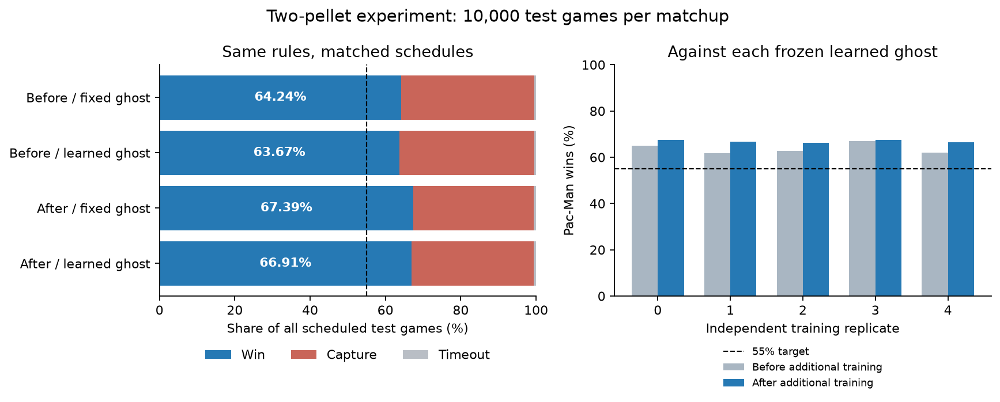

RECORDED test suite result:
........................................................................ [ 13%]
........................................................................ [ 26%]
........................................................................ [ 39%]
........................................................................ [ 52%]
........................................................................ [ 66%]
........................................................................ [ 79%]
........................................................................ [ 92%]
.........................................                                [100%]
545 passed in 20.45s
RECORDED training-layout analysis:
{
  "training_games": 550000,
  "distinct_training_wall_layouts": 26012,
  "per_run": [
    {
      "replicate": 0,
      "games": 110000,
      "distinct_wall_layouts": 18227,
      "stages": {
        "baseline": 30000,
        "ghost": 30000,
        "adapt": 50000
      }

### Recorded intermediate study

Different four-corner rules and ghost; these rates are not a controlled comparison with the final game. Historical source reference `d3120d1`.

| Historical agent | Wins | Losses | Ties | Games | Win rate |
|---|---:|---:|---:|---:|---:|
| learned | 736 | 220 | 44 | 1000 | 73.6% |
| pathfinding | 149 | 851 | 0 | 1000 | 14.9% |
| random | 0 | 1000 | 0 | 1000 | 0.0% |

RECORDED historical test suite result:
........................................................................ [ 15%]
........................................................................ [ 30%]
........................................................................ [ 45%]
........................................................................ [ 60%]
........................................................................ [ 75%]
........................................................................ [ 90%]
............................................                             [100%]
476 passed in 11.94s


In [42]:
import gzip

BUNDLE = WORKSPACE / "reports/hybrid-55"
aggregate = json.loads((BUNDLE / "aggregate.json").read_text())
inventory = json.loads((BUNDLE / "sha256.json").read_text())
assert len(inventory) == 137
for name, expected in inventory.items():
    assert hashlib.sha256(safe_destination("reports/hybrid-55/" + name).read_bytes()).hexdigest() == expected
checks = json.loads(run_python(["-c", """
import json
from pathlib import Path
import pacman
from scripts.verify_hybrid_run import verify_run
assert Path(pacman.__file__).resolve().is_relative_to(Path.cwd())
print(json.dumps([verify_run(Path('reports/hybrid-55') / f'replicate-{i}', replay_limit=0)
                  for i in range(5)]))
"""]))
assert all(check["record_consistency_verified"] and check["reports"] == 17
           and check["records_checked"] == 25000 and check["games_replayed"] == 0 for check in checks)
(RUNS / "record-consistency.json").write_text(json.dumps(checks, indent=2))
print("Fresh consistency audit: all 85 saved reports and 125,000 record rows; zero bulk game replays.")
print("The prior archive replayed all 125,000 games. That replay is recorded evidence, not this run.")
rows = ["| Frozen matchup | Wins | Losses | Ties | Games | Win rate |",
        "|---|---:|---:|---:|---:|---:|"]
for matchup, registered in aggregate["test"].items():
    counts = Counter()
    for replicate in range(5):
        path = BUNDLE / f"replicate-{replicate}/{matchup}-test.json.gz"
        report = json.loads(gzip.decompress(path.read_bytes()))
        counts.update(record["outcome"] for record in report["records"])
    games = sum(counts.values())
    assert games == registered["games"] == 10000
    assert all(counts[outcome] == registered[outcome] for outcome in ("win", "loss", "tie"))
    assert counts["win"] / games == registered["win_rate"]
    rows.append(f"| {matchup} | {counts['win']} | {counts['loss']} | {counts['tie']} | {games} | {counts['win']/games:.2%} |")
assert aggregate["test"]["adapted-vs-learned"]["win"] == 6691
assert abs(aggregate["adaptation_gain_vs_learned"] - 0.0324) < 1e-12
display(Markdown("### Recorded final test results\n\n" + "\n".join(rows)))
display(Image(filename=str(BUNDLE / "results.png")))
print("RECORDED test suite result:")
print((BUNDLE / "final-tests.log").read_text().strip())
layout_evidence = json.loads((WORKSPACE / "evidence/training-map-counts.json").read_text())
assert layout_evidence["training_games"] == 550000
assert layout_evidence["distinct_training_wall_layouts"] == 26012
assert layout_evidence["distinct_test_wall_layouts"] == 491
assert layout_evidence["training_test_layout_overlap"] == 0
assert sum(row["games"] for row in layout_evidence["per_run"]) == 550000
archive_check = json.loads((BUNDLE / "archive-completion.json").read_text())
assert archive_check["full_verified_runs"] == 5 and archive_check["games_replayed"] == 125000
for replicate in range(5):
    saved_check = json.loads((BUNDLE / f"replicate-{replicate}/verification.json").read_text())
    assert saved_check["all_games_replayed"] and saved_check["games_replayed"] == 25000
print("RECORDED training-layout analysis:")
print(json.dumps(layout_evidence, indent=2))
historical = json.loads((WORKSPACE / "historical/eval-test.json").read_text())
rows = ["| Historical agent | Wins | Losses | Ties | Games | Win rate |",
        "|---|---:|---:|---:|---:|---:|"]
for agent in sorted({row["agent"] for row in historical["records"]}):
    counts = Counter(row["outcome"] for row in historical["records"] if row["agent"] == agent)
    games = sum(counts.values())
    rows.append(f"| {agent} | {counts['win']} | {counts['loss']} | {counts['tie']} | {games} | {counts['win']/games:.1%} |")
display(Markdown("### Recorded intermediate study\n\nDifferent four-corner rules and ghost; these rates are not a controlled comparison with the final game. Historical source reference `d3120d1`.\n\n" + "\n".join(rows)))
print("RECORDED historical test suite result:")
print((WORKSPACE / "historical/tests-final.log").read_text().strip())


## Live working example

The same final AI pair used by `./play` runs below with seed 1000000 and episode key 42. Pac-Man and the ghost both act automatically. The replay prints its final frame and saves all frames. A separate ten-game validation demonstration uses frozen policies and performs no Q-value updates.

In [43]:
policy_args = ["--pac-policy", "reports/hybrid-55/replicate-0/pacman.npz",
               "--ghost-policy", "reports/hybrid-55/replicate-0/ghost.npz"]
transcript = run_python(["-m", "pacman.hybrid", "watch", *policy_args,
                         "--seed", "1000000", "--key", "42", "--delay", "0", "--plain"])
(RUNS / "live-watch.txt").write_text(transcript)
record = json.loads(transcript.strip().splitlines()[-1])
assert record["outcome"] == "win" and record["turns"] == 13
checked_record = json.loads(run_python(["-c", """
import json
from pathlib import Path
from pacman.hybrid.artifacts import load_policy
from pacman.hybrid.experiment import run_episode
from pacman.hybrid.ghost import GhostController
from pacman.hybrid.learning import PacActor
root = Path('reports/hybrid-55/replicate-0')
pac = load_policy(root / 'pacman.npz', expected_role='pacman')
ghost = load_policy(root / 'ghost.npz', expected_role='ghost', rules=pac.rules)
before = pac.table.digest(), ghost.table.digest()
record = run_episode(1000000, 42, pac.rules, PacActor(pac.table), GhostController(pac.rules, ghost.table))
assert before == (pac.table.digest(), ghost.table.digest())
print(json.dumps(record))
"""]))
assert checked_record == record
print("Live frozen-policy demo: Pac-Man wins in 13 turns; policy table hashes unchanged.")
print("\n".join(transcript.strip().splitlines()[-7:-1]))
print("Full animation transcript:", RUNS / "live-watch.txt")

mini_output = RUNS / "validation-10.json"
print(run_python(["-m", "pacman.hybrid", "evaluate", *policy_args,
                  "--split", "val", "--games", "10", "--repeats", "1", "--replicate", "0",
                  "--out", str(mini_output)]))
mini = json.loads(mini_output.read_text())
assert mini["split"] == "val" and len(mini["records"]) == 10
assert [row["layout_seed"] for row in mini["records"]] == list(range(1000000, 1000010))
assert mini["policy_hashes"] == mini["frozen_hashes_after"]
assert all(row["outcome"] in ("win", "loss", "tie") for row in mini["records"])
assert all(value["q_updates"] == 0 for value in mini["coverage"].values())
print("Live smoke demonstration: first ten validation seeds, frozen policies, no learning.")
print("This ten-game demonstration is not a new estimate of held-out test performance.")


Live frozen-policy demo: Pac-Man wins in 13 turns; policy table hashes unchanged.
. . . . .
. . # # .
? . ? . G
? ? ? . .
? ? . P .
turn=13/100 pellets=0/2 ghost=pursue outcome=win
Full animation transcript: /private/var/folders/b7/zrvh84fd5lzdv299wwxvx5w00000gn/T/pacman-final-84ib0v3m/notebook_runs/live-watch.txt


{
  "games": 10,
  "loss": 3,
  "mean_turns": 20.3,
  "per_layout": {
    "127c5690ec5bd8644384bf2227ff15451c6a666aa064d4fe6f6de316e681ec6c": {
      "games": 1,
      "wins": 1
    },
    "361cd8c7cb0dba4af89aa2ea7a1f39e9851b315e16a84b8545511ee5301732b6": {
      "games": 1,
      "wins": 0
    },
    "3d51ab9a4b367db5950aa90bcf713327b097ed2b46493f6f909d69fbbebef908": {
      "games": 1,
      "wins": 1
    },
    "7b236f45c831717351f7ded57d238ba593ce72a7270819fc01c3e7ed6f139898": {
      "games": 1,
      "wins": 1
    },
    "7b6bd54a108ed348c0e6bc6e34aeceea30699ffb1b22863b1034e936efd8bf86": {
      "games": 1,
      "wins": 1
    },
    "8c0ad18f57d08c792003ab81eaa6a9ea874dad076686c19f831b00477c27bfdc": {
      "games": 1,
      "wins": 1
    },
    "a37e8677a92a77d65d08a5815fb63df9894d26e13b7a1f1efc6e9d801f40cd79": {
      "games": 1,
      "wins": 1
    },
    "bf240da6abe4f7f601195446af43c6628fb81fbfaa4c48738209da7d5e1776a8": {
      "games": 1,
      "wins": 1
    },
    "d4d78

## Optional small training demonstration

Change the Boolean below only to demonstrate the three training stages with tiny budgets. Its result is not the trained policy used in the report. To reproduce the full experiment, inspect the five embedded protocols and the visible CLI/analysis scripts.

In [44]:
RUN_SMALL_TRAINING = False
if RUN_SMALL_TRAINING:
    training_directory = Path(tempfile.mkdtemp(prefix="small-training-", dir=RUNS)) / "run"
    print(run_python(["-m", "pacman.hybrid", "train", "--out", str(training_directory),
                      "--replicate", "0", "--base-episodes", "30", "--ghost-episodes", "30",
                      "--adapt-episodes", "50", "--validation-games", "10", "--games", "10",
                      "--repeats", "1"]))
    print("Small teaching run only; it does not reproduce the full experiment.")
else:
    print("Training disabled. The recorded experiment used 550,000 training games across five replicates.")


Training disabled. The recorded experiment used 550,000 training games across five replicates.


---

<a id="extra-credit"></a>

# Extra credit: How the Pac-Man AI works

**Option 1 optional extra credit, worth up to 20 points.**

Christian Gore and Phillip Kononenko, CSCI 3202

This section explains how we implemented Pac-Man's Q-learning, the ghost's BFS and learned search, and the training updates. The numbered citations refer to the sources listed at the end of this section.

## Learning decisions from rewards

Our final game combines tabular Q-learning with breadth-first search (BFS). BFS finds shortest paths by edge count on our unweighted grid [5]. Q-learning estimates the return from choosing action a in state s through interaction with an environment. Rewards provide feedback, and exploration gives the learner experience with alternatives. Sutton and Barto describe these ideas and action-value methods in Chapters 2, 3, and 6 [1]. Our implementation uses Python dictionaries whose keys are feature tuples and whose rows hold four action values. Unseen rows return zeros.

Pac-Man's `PacActor` in `pacman/hybrid/learning.py` applies the Q-learning update [2]:

`Q(s,a) <- Q(s,a) + alpha * [r + gamma * max Q(s',a') - Q(s,a)]`

The maximum considers legal next actions. At a terminal win, capture, or timeout, the target is r alone. There is no bootstrap from a finished game. Pac-Man uses alpha = 0.1 and gamma = 1.0. It receives +1 for each pellet, +100 for winning, -100 for capture or timeout, and -0.05 per turn. Rewards add together. This encourages collection and shorter successful routes, rather than optimizing win probability alone.

## What Pac-Man observes

Pac-Man knows its own position, the current ghost position, and remaining pellets. It discovers adjacent walls and remembers them until reset. Our BFS treats unknown cells as open, finds a route toward a pellet, and replans after new observations. BFS supplies a direction hint rather than making the learned player's final choice.

The eight encoded inputs are the pellet-route direction, neighboring-direction mask, relative ghost position, bucketed ghost distance, estimated line of sight, remaining pellet count, bucketed pellet distance, and time remaining. Thus, the table combines progress and danger information. The legal mask excludes known blocked moves, while undiscovered walls can make longer route estimates inaccurate. Compression lets the learner reuse experience, although different physical situations can share a row.

Training uses epsilon-greedy action selection. The learner selects a random legal action with probability epsilon and otherwise selects a maximum-valued action. Epsilon decreases from 1.0 to 0.05 over the first 70% of each training stage, then remains at 0.05. Evaluation uses frozen tables, epsilon zero, and no updates. Exploration and greedy evaluation have different purposes [1].

## A ghost with search and memory

`pacman/hybrid/ghost.py` separates fixed navigation from learned search. The ghost knows the wall map, but Pac-Man is visible only along an unobstructed row or column. Its observation contains no hidden Pac-Man position. Heading comes only from consecutive visible positions. The ghost chases a sighting with BFS, then follows the last-seen position after visibility ends.

After reaching that area, it chooses a directional investigation target. Targets extend at most three open cells, each choice permits at most four moves, and a sighting permits at most three choices. Memory expires after 12 hidden observations. Reacquisition interrupts search. The ghost's feature tuple records its cell, last sighting, inferred heading, candidate directions, memory age, choices used, remaining time, and availability of the forward direction.

Only target selection learns. The ghost uses alpha = 0.1, gamma = 0.97, capture reward +1, Pac-Man-win reward -1, and timeout reward zero. Equal action values during greedy play use the fixed heading-or-random search rule. This also gives unseen zero-valued states a defined fallback.

## Learning across several turns

A ghost search decision can affect several turns. We accumulate rewards over its elapsed duration k and use the target:

`sum(gamma**j * r[j+1], j=0..k-1) + gamma**k * max Q(s',a')`

This elapsed-time discount follows the semi-Markov treatment of temporally extended choices [3]. A pending choice remains eligible for credit after Pac-Man becomes visible again. Capture can therefore reward that search even when Pac-Man walks into the ghost before its next action. Terminal notification closes the update once and removes the future-value term.

We train Pac-Man against a fixed ghost, train the ghost against frozen Pac-Man checkpoints, then continue Pac-Man against a frozen mixture. Changing opponents can change the learner's environment, a difficulty discussed by Foerster and colleagues [4]. Our staged freezing is our implementation choice. We use tabular learning without experience replay, not their deep-learning algorithm.

The tables compress partial observations and use constant learning rates. We do not claim that the complete Markov-state and sampling conditions behind Q-learning convergence hold here [2]. The saved results demonstrate empirical performance, including remaining losses and timeouts, rather than convergence to optimal play.

## References

[1] Sutton and Barto, 2018. [Reinforcement Learning, second edition](https://mitpress.mit.edu/9780262039246/reinforcement-learning/). MIT Press, Chapters 2, 3, and 6.

[2] Watkins and Dayan, 1992. [Q-learning](https://www.gatsby.ucl.ac.uk/~dayan/papers/cjch.pdf). Machine Learning 8, 279-292.

[3] Sutton, Precup, and Singh, 1999. [Between MDPs and semi-MDPs](https://people.cs.umass.edu/~barto/courses/cs687/Sutton-Precup-Singh-AIJ99.pdf). Artificial Intelligence 112, 181-211.

[4] Foerster and colleagues, 2017. [Stabilising Experience Replay for Deep Multi-Agent Reinforcement Learning](https://proceedings.mlr.press/v70/foerster17b.html). PMLR 70, 1146-1155.

[5] NetworkX documentation. [Shortest paths](https://networkx.org/documentation/stable/reference/algorithms/shortest_paths.html), unweighted graphs. We implement BFS directly; NetworkX is not a project dependency.

---

**End of extra-credit section.**
